In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

### ML

In [5]:
apt_iata = "FLR"
folder = os.path.join("data", "hist_schedule")

files = [
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.endswith(".csv")
]

df = pd.concat(
    [pd.read_csv(file, sep=';', low_memory=False) for file in files],
    ignore_index=True
)

#filter schedule
df_f = df[(df['AVIAZIONE'] == 'Commerciale') & (df['NATURA'] == 'P') & (df['SCALO_TECNICO'] == 0) & (df['ADULT'] != 0) & (~df['NUMERO_MASSIMO_PAX'].isna()) & 
          ((df['ADULT']+df['CHILD']) <= df['NUMERO_MASSIMO_PAX'])]

df_f

,ID_VOLO,ID_LEGATO,DATA_VOLO,NOME_ESERCENTE,NAME_CARRIER,MATRICOLA_AEROMOBILE,PESO_MASSIMO,MODELLO_AEROMOBILE,NUMERO_MASSIMO_PAX,CODICE_ICAO,...,CERTIFICATO,ESPORTATO,GATE,VOLO_RISCHEDULATO,STATO_ATTIVITA,READY,CERT_TIMESTAMP,DATA_DIR_CANC,CAUSALE_DIR_CANC,MERCE_ESENTE
29,26808735,26808210.0,20170101,NaN,AIR FRANCE,FGUGI,60.0,A318,131.0,AFR,...,S,S,NaN,NaN,Completato,NaN,2017-01-02 08:56:31.000,NaN,NaN,NaN
30,26808742,26808231.0,20170101,NaN,KLM-ROYAL DUTCH AIRLINES,PHEZO,45.0,E190,100.0,KLM,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 07:11:01.000,NaN,NaN,NaN
31,26808756,26808217.0,20170101,NaN,LUFTHANSA,DAECD,51.0,E190,94.0,DLH,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 08:24:24.000,NaN,NaN,NaN
32,26808763,26808196.0,20170101,NaN,VUELING AIRLINES,ECMKV,64.0,A319,144.0,VLG,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 09:31:49.000,NaN,NaN,NaN
33,26808770,26808189.0,20170101,NaN,SWISS,HBJVP,51.0,E190,110.0,SWR,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 10:52:52.000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,68716698,68716533.0,20251218,NaN,ITA AIRWAYS,EIIMB,64.0,A319,144.0,ITY,...,S,S,GATE 1,NaN,Completato,NaN,2026-01-05 10:55:26.000,NaN,NaN,0.0
314427,68924169,68923996.0,20251208,NaN,AIR SERBIA,YUAPF,68.0,A319,144.0,ASL,...,S,S,GATE 11,NaN,Completato,NaN,2025-12-08 21:27:43.000,NaN,NaN,0.0
314477,69100636,64538481.0,20251205,NaN,VOLOTEA,ECNGL,66.0,A319,156.0,VOE,...,S,S,GATE 2,NaN,Completato,NaN,2025-12-09 08:57:58.000,NaN,NaN,0.0
314736,69688892,64545032.0,20251217,NaN,AIR FRANCE,FHZUX,64.0,BCS3,148.0,AFR,...,S,S,GATE 3,NaN,Completato,NaN,2025-12-17 12:40:04.000,NaN,NaN,0.0


In [6]:
def standardize_df(df):
    df=df.copy()

    col_mapping= {'DATA_PREVISTA': 'date', 'ORA_PREVISTA': 'schtime', 
                  'CODICE_IATA':'car', 'CODICE_ICAO': 'car_icao', 'NUMERO_VOLO': 'flt_n', 'DESTINAZIONE': 'apt', 
                  'MODELLO_AEROMOBILE': 'ac', 'NUMERO_MASSIMO_PAX':'seats', 'ADULT': 'adults', 'CHILD': 'children', 'NUM_BAGAGLI': 'luggage'}
    df = df[col_mapping.keys()].copy()
    df.rename(columns=col_mapping, inplace=True)

    df["date"] = pd.to_datetime(df["date"].astype("string"), format="%Y%m%d", errors="coerce")

    df['week_day']= df['date'].dt.day_name(locale='en_US')
    df['month'] = df['date'].dt.month_name(locale='en_US')
    df['year'] = df['date'].dt.year

    schtime = (
        df["schtime"]
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.zfill(4)
    )

    schtime_dt = pd.to_datetime(
        schtime,
        format="%H%M",
        errors="coerce"
    )

    df["schtime"] = schtime_dt.dt.strftime("%H:%M")

    hour_decimal = schtime_dt.dt.hour + schtime_dt.dt.minute / 60

    df["sin_hour"] = np.sin(2 * np.pi * hour_decimal / 24)
    df["cos_hour"] = np.cos(2 * np.pi * hour_decimal / 24)

    df["fdatetime"] = pd.to_datetime(
        df["date"].dt.strftime("%Y-%m-%d")
        + " "
        + df["schtime"],
        errors="coerce"
    )

    # Carrier code
    df["car"] = (
        df["car"]
        .fillna(df["car_icao"])
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df = df[df["car"] != "_"].copy()

    # Flight number
    df["flt_n"] = (
        df["flt_n"]
        .fillna("")
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.replace(" ", "", regex=False)
        .str.upper()
        .str.replace(r"^0+(?=.)", "", regex=True)
    )

    # nflt = carrier + flight number, con uno spazio
    df["nflt"] = df["car"] + " " + df["flt_n"]
    df.drop(columns=["car_icao", 'flt_n'], inplace=True)

    df["ac"] = (
        df["ac"]
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df['pax'] = df['adults'] + df['children']
    df["load_factor"] = df["pax"] / df["seats"]

    return df

df1 = standardize_df(df_f)
# remove covid years
df1 = df1[~df1['year'].isin([2020, 2021])].copy()
print(df1.shape)
df1

(102722, 18)


,date,schtime,car,apt,ac,seats,adults,children,luggage,week_day,month,year,sin_hour,cos_hour,fdatetime,nflt,pax,load_factor
29,2017-01-01,06:20,AF,CDG,A318,131.0,115,10,101,Sunday,January,2017,0.996195,-0.087156,2017-01-01 06:20:00,AF 1267,125,0.954198
30,2017-01-01,06:30,KL,AMS,E190,100.0,95,2,117,Sunday,January,2017,0.991445,-0.130526,2017-01-01 06:30:00,KL 1638,97,0.970000
31,2017-01-01,07:20,LH,FRA,E190,94.0,89,2,79,Sunday,January,2017,0.939693,-0.342020,2017-01-01 07:20:00,LH 319,91,0.968085
32,2017-01-01,08:50,VY,MAD,A319,144.0,89,5,36,Sunday,January,2017,0.737277,-0.675590,2017-01-01 08:50:00,VY 1506,94,0.652778
33,2017-01-01,09:50,LX,ZRH,E190,110.0,81,11,80,Sunday,January,2017,0.537300,-0.843391,2017-01-01 09:50:00,LX 1679,92,0.836364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,2025-12-18,11:10,AZ,FCO,A319,144.0,118,1,142,Thursday,December,2025,0.216440,-0.976296,2025-12-18 11:10:00,AZ 1678,119,0.826389
314427,2025-12-08,20:20,JU,BEG,A319,144.0,67,1,45,Monday,December,2025,-0.819152,0.573576,2025-12-08 20:20:00,JU 469,68,0.472222
314477,2025-12-05,18:40,V7,CTA,A319,156.0,124,7,11,Friday,December,2025,-0.984808,0.173648,2025-12-05 18:40:00,V7 1705,131,0.839744
314736,2025-12-17,12:20,AF,CDG,BCS3,148.0,122,4,82,Wednesday,December,2025,-0.087156,-0.996195,2025-12-17 12:20:00,AF 1367,126,0.851351


##### creazione base per futuri voli

In [57]:
def build_ac_lookup(
    df: pd.DataFrame,
    lookback_days: int = 730,
    min_flights: int = 10,
):
    """
    Costruisce i lookup usando solo gli ultimi `lookback_days` giorni di storico
    (default 2 anni), per riflettere flotta/rotte attuali, non quelle del 2017.
 
    Catena di fallback:
      seats:  nflt -> (car, ac) -> ac -> global
      ac:     nflt -> (car, apt) -> car -> global
 
    Il livello "nflt" (numero di volo specifico) e' il piu' preciso: uno stesso
    numero di volo tende a essere operato in modo consistente dallo stesso
    equipaggiamento/capacita' nel tempo.
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
 
    cutoff = df["date"].max() - pd.Timedelta(days=lookback_days)
    recent = df[df["date"] >= cutoff]
 
    valid = recent[["car", "apt", "ac", "seats", "nflt"]].dropna()
    valid = valid[valid["seats"] > 0]
 
    # --- capienza tipica per nflt (primo livello, il piu' specifico) ---
    nflt_seats_stats = (
        valid.groupby("nflt")["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_nflt = (
        nflt_seats_stats[nflt_seats_stats["n_flights"] >= min_flights]
        .set_index("nflt")["seats"]
        .astype(int)
    )
 
    # --- capienza tipica per car, ac (fallback) ---
    car_ac_stats = (
        valid.groupby(["car", "ac"])["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_car_ac = (
        car_ac_stats[car_ac_stats["n_flights"] >= min_flights]
        .set_index(["car", "ac"])["seats"]
        .astype(int)
    )
 
    # --- capacita' tipica per solo ac (fallback finale prima del globale) ---
    seats_by_ac = (
        valid.groupby("ac")["seats"]
        .agg(lambda s: s.mode().iloc[0])
        .astype(int)
    )
 
    # --- modello aereo piu' usato per nflt (primo livello, il piu' specifico) ---
    nflt_ac_counts = (
        valid.groupby(["nflt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    nflt_totals = nflt_ac_counts.groupby("nflt")["n_flights"].transform("sum")
 
    ac_by_nflt = (
        nflt_ac_counts[nflt_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["nflt"], keep="first")
        .set_index("nflt")["ac"]
    )
 
    # --- modello piu' usato per car, apt (fallback) ---
    route_counts = (
        valid.groupby(["car", "apt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    route_totals = route_counts.groupby(["car", "apt"])["n_flights"].transform("sum")
 
    route_ac = (
        route_counts[route_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car", "apt"], keep="first")
        .set_index(["car", "apt"])["ac"]
    )
 
    # --- modello piu' usato per carrier (fallback finale prima del globale) ---
    carrier_counts = (
        valid.groupby(["car", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    carrier_totals = carrier_counts.groupby("car")["n_flights"].transform("sum")
 
    carrier_ac = (
        carrier_counts[carrier_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car"], keep="first")
        .set_index("car")["ac"]
    )
 
    # --- fallback globale ---
    global_ac = valid["ac"].mode().iloc[0]
    global_seats = valid["seats"].mode().iloc[0]
 
    return {
        "seats_by_nflt": seats_by_nflt,
        "seats_by_car_ac": seats_by_car_ac,
        "seats_by_ac": seats_by_ac,
        "ac_by_nflt": ac_by_nflt,
        "route_ac": route_ac,
        "carrier_ac": carrier_ac,
        "global_ac": global_ac,
        "global_seats": global_seats,
    }

In [58]:
ac_lookup_bundle = build_ac_lookup(df1)

save_path = os.path.join("data", apt_iata, "ac_lookup.joblib")
os.makedirs(os.path.dirname(save_path), exist_ok=True)
joblib.dump(ac_lookup_bundle, save_path)

['data\\FLR\\ac_lookup.joblib']

##### testing

                 pax          seats    load_factor
count  102722.000000  102722.000000  102722.000000
mean      101.434279     127.629349       0.792031
std        27.822603      23.002886       0.162514
min         1.000000       6.000000       0.006944
5%         52.000000      94.000000       0.455133
25%        85.000000     112.000000       0.713115
50%       102.000000     131.000000       0.833333
75%       123.000000     144.000000       0.910000
95%       142.000000     156.000000       0.979167
99%       150.000000     180.000000       1.000000
max       174.000000     189.000000       1.000000


Text(0.5, 1.0, 'Distribution of pax per flight')

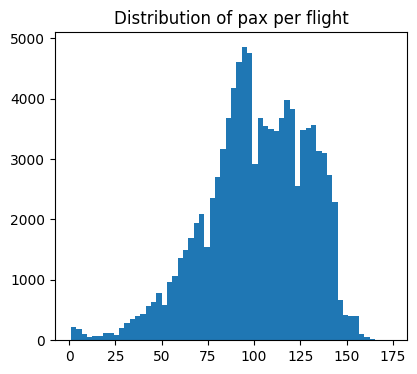

In [7]:
# outliers in pax e luaggage
print(df1[["pax", "seats", "load_factor"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

plt.figure(figsize=(10,4))
plt.subplot(121)
hist = plt.hist(df1["pax"], bins=60)
plt.title("Distribution of pax per flight")

In [8]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

def regression_report(y_true, y_pred, title=""):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mask = y_true != 0
    mape = (
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        ) * 100
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
        * 100
    )

    print(title)
    print(f"MAE: {mae:.2f}")
    print(f"MAPE: {mape:.2f} %")
    print(f"RMSE: {rmse:.2f}")
    print(f"WAPE: {wape:.2f} %")
    print(f"R2: {r2:.3f}")

In [9]:
def baseline_model(train, val):

    train = train.copy()
    val = val.copy()

    global_lf = train["pax"].mean()

    mean_full = (
        train
        .groupby(["car", "apt", "ac", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt_month = (
        train
        .groupby(["car", "apt", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt = (
        train
        .groupby(["car", "apt"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car = (
        train
        .groupby("car")["pax"]
        .mean()
        .rename("pred_pax")
    )

    out = val.copy()

    # livello più specifico
    out = out.merge(
        mean_full,
        on=["car", "apt", "ac", "month"],
        how="left"
    )

    # fallback car + apt + month
    fallback = out.merge(
        mean_car_apt_month,
        on=["car", "apt", "month"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback car + apt
    fallback = out.merge(
        mean_car_apt,
        on=["car", "apt"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback carrier
    fallback = out.merge(
        mean_car,
        on="car",
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # ultimo fallback: media globale
    out["pred_pax"] = out["pred_pax"].fillna(global_lf)

    return out

In [10]:
# validation 2024 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Validation 2024")

#Baseline Validation 2024
MAE: 13.64
MAPE: 15.62 %
RMSE: 17.88
WAPE: 12.50 %
R2: 0.508


In [11]:
# test 2025 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Test 2025")

#Baseline Test 2025
MAE: 14.31
MAPE: 74.57 %
RMSE: 20.84
WAPE: 13.33 %
R2: 0.443


In [12]:
# validation 2024 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Validation PAX 2024")

# XGBoost Validation PAX 2024
MAE: 12.56
MAPE: 13.71 %
RMSE: 16.36
WAPE: 11.51 %
R2: 0.588


In [13]:
# test 2025 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Test PAX 2025")

# XGBoost Test PAX 2025
MAE: 11.74
MAPE: 17.36 %
RMSE: 15.76
WAPE: 10.93 %
R2: 0.682


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

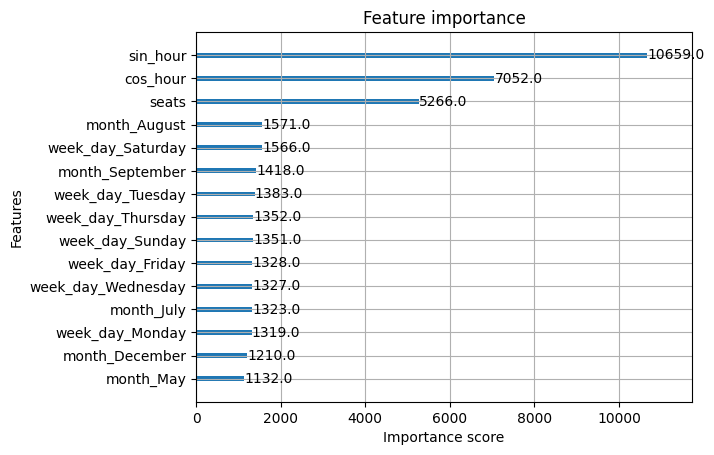

In [14]:
from xgboost import plot_importance
plot_importance(xgb_pax, max_num_features=15)

##### training for production

In [16]:
# training fino al 2025 incluso

df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2026
train = df.loc[train_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
y_train = train[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

# save model and encoders

import joblib

model_bundle = {
    "model": xgb_pax,
    "apt_encoder": apt_encoder,
    "other_encoder": other_encoder,
    "features": features,
    "apt_column": apt_column,
    "other_categorical_columns": other_categorical_columns,
    "numeric_columns": numeric_columns,
    "target": "pax",
}

joblib.dump(
    model_bundle,
    f"data/pax_model.joblib",
)

['data/pax_model.joblib']

### arrival curves

In [37]:
# entire schedule
apt_iata= 'FLR'

url = f"https://aosnice-api.toscana-aeroporti.com/{apt_iata}/getPlannedFlights"
response = requests.get(url)
response.raise_for_status()
data = response.json()
flights = data["RESPONSE"]["result"]["elements"]

rows = []
for f in flights:
    rows.append({
        "flight_number": f.get("number"),
        "nature": f.get("nature", {}).get("code"),
        "carrier": f.get("carrier", {}).get("publicCode"),
        "airport": f.get("airport", {}).get("code"),
        "periods": f.get("periods", [])
    })

all_flights = pd.DataFrame(rows)

# filter departures and explode periods
sched = all_flights[all_flights["nature"] == "P"].drop(columns=["nature"]).rename(columns={"airport": "apt"}).copy()
sched["periods"] = sched["periods"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
sched = (
    sched
    .explode("periods", ignore_index=True)
    .join(pd.json_normalize(sched.explode("periods")["periods"]))
    .drop(columns=["periods"])
)

sched["from"] = pd.to_datetime(sched["from"]).dt.normalize()
sched["to"] = pd.to_datetime(sched["to"]).dt.normalize()
sched["flight_number"] = (sched["flight_number"].astype(str).str.replace(r"\.0$", "", regex=True).str.lstrip("0"))
sched["freq"] = sched["frequency"].str.split(",")
sched.to_csv(os.path.join('data', 'schedule_all.csv'), index=False)

In [40]:
# security data
df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')
df_security = df_security[
    (df_security['LAST_POSITION'] == 'SECURITY_AREA') &
    (df_security['PASSAGE_AUTHORIZED'] == 1)
].copy()

df_security["FLIGHT_NUMBER"] = df_security["FLIGHT_NUMBER"].astype(str).str.lstrip("0")
df_security["DATE_OF_FLIGHT"] = pd.to_datetime(df_security["DATE_OF_FLIGHT"]).dt.normalize()
df_security["SCR_TIME"] = pd.to_datetime(df_security["SCR_TIME"], errors="coerce")

df_security = (
    df_security
    .sort_values('SCR_TIME')
    .drop_duplicates(subset='ID', keep='last')
    .reset_index(drop=True)
)

cols_to_keep = ['ID', 'DATE_OF_FLIGHT', 'OPERATING_CARRIER', 'FLIGHT_NUMBER', 'SCR_TIME']
df_security = df_security[cols_to_keep].copy()
df_security["weekday"] = df_security["DATE_OF_FLIGHT"].dt.isocalendar().day

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\4287610874.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')


In [42]:
# merge
sched = pd.read_csv(os.path.join('data', 'schedule_all.csv'))
sched['flight_number'] = sched['flight_number'].astype(str)

out = df_security.merge(
    sched,
    left_on=["OPERATING_CARRIER", "FLIGHT_NUMBER"],
    right_on=["carrier", "flight_number"],
    how="left"
).drop(columns=["carrier", "flight_number"])
out["frequency"] = out["frequency"].fillna("")

mask = (
    out["DATE_OF_FLIGHT"].between(out["from"], out["to"])
    &
    out.apply(
        lambda r: str(r["weekday"]) in r["frequency"].split(","),
        axis=1
    )
)

out = out[mask].copy()

out["SCR_TIME"] = pd.to_datetime(out["SCR_TIME"], errors="coerce")
out["time"] = pd.to_datetime(out["time"], errors="coerce")
out['flight_number'] = out['OPERATING_CARRIER'] + ' ' + out['FLIGHT_NUMBER']

out["departure_dt"] = (
    out["DATE_OF_FLIGHT"]
    + pd.to_timedelta(out["time"].dt.hour, unit="h")
    + pd.to_timedelta(out["time"].dt.minute, unit="m")
    + pd.to_timedelta(out["time"].dt.second, unit="s")
)

out["advance"] = (out["departure_dt"] - out["SCR_TIME"]).dt.total_seconds() / 60

out["month"] = out["departure_dt"].dt.month_name(locale="en_US")
out["departure_hour"] = out["departure_dt"].dt.hour
out["time_band"] = pd.cut(
    out["departure_hour"],
    bins=[-1, 5, 9, 13, 17, 21, 23],
    labels=[
        "00-05",
        "06-09",
        "10-13",
        "14-17",
        "18-21",
        "22-23",
    ]
)
out.rename(columns={"OPERATING_CARRIER": "car"}, inplace=True)

out["advance"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    304311.000000
mean        105.636527
std          35.450038
min        -561.066667
1%           30.936667
5%           52.700000
10%          62.983333
25%          81.200000
50%         103.550000
75%         129.083333
90%         154.983333
95%         168.650000
99%         178.700000
max         347.183333
Name: advance, dtype: float64

In [43]:
# clean outliers
p5 = out["advance"].quantile(0.05)
p99 = out["advance"].quantile(0.999)

df_arrivals_clean = out[(out["advance"] <= p99) & (out["advance"] >= p5)].copy()

print(f"soglia p5: {p5:.1f} min")
print(f"soglia p99: {p99:.1f} min")
print("righe totali:", len(out))
print("righe rimosse:", len(out) - len(df_arrivals_clean))
print("righe rimanenti:", len(df_arrivals_clean))

soglia p5: 52.7 min
soglia p99: 201.5 min
righe totali: 304311
righe rimosse: 15512
righe rimanenti: 288799


#### test vari

In [44]:
def advance_summary(df, group_cols, min_count=100):

    summary = (
        df.groupby(group_cols)["advance"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            p05=lambda x: x.quantile(0.05),
            p25=lambda x: x.quantile(0.25),
            p75=lambda x: x.quantile(0.75),
            p95=lambda x: x.quantile(0.95),
        )
        .reset_index()
    )

    summary = summary[
        summary["count"] >= min_count
    ].copy()

    return summary.sort_values(
        "median",
        ascending=False
    )

def plot_boxplot(df, group_col, min_count=100, top_n=20):
    counts = df[group_col].value_counts()

    if isinstance(df[group_col].dtype, pd.CategoricalDtype):
        valid_groups = [
            g for g in df[group_col].cat.categories
            if counts.get(g, 0) >= min_count
        ]
    else:
        valid_groups = counts[counts >= min_count].index.tolist()

    valid_groups = valid_groups[:top_n]

    data = [
        df.loc[df[group_col] == g, "advance"].dropna()
        for g in valid_groups
    ]

    plt.figure(figsize=(12, 6))

    plt.boxplot(
        data,
        tick_labels=valid_groups,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 1,
            "alpha": 0.5,
            "markeredgewidth": 1,
        }
    )

    plt.ylabel("Minutes before departure")
    plt.xlabel(group_col)
    plt.title(f"Security advance by {group_col}")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

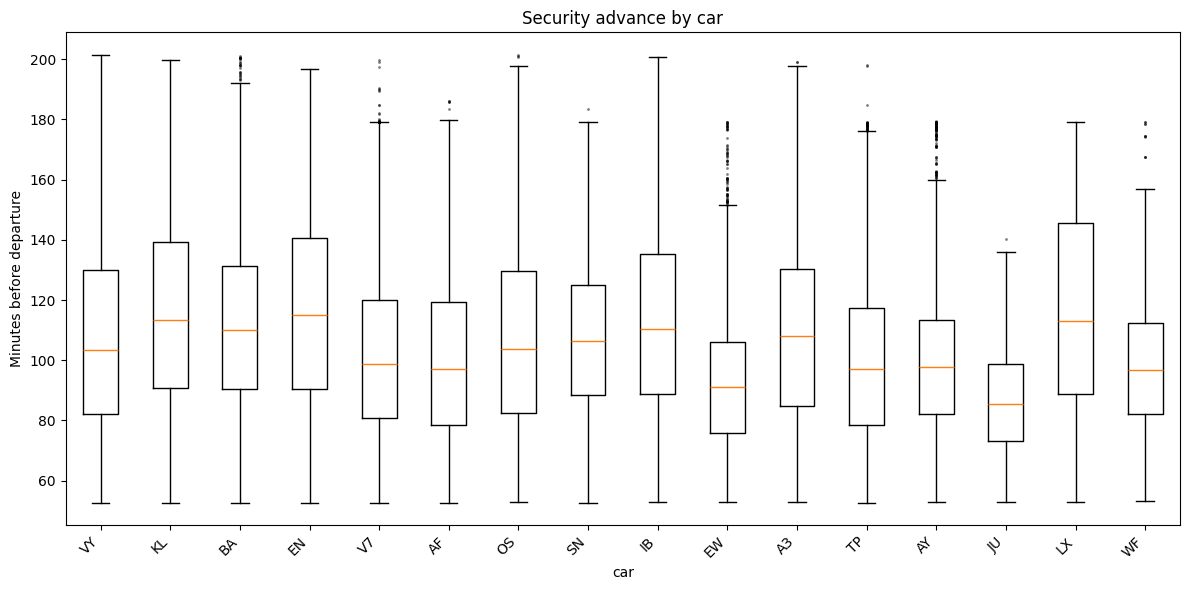

In [45]:
by_carrier = plot_boxplot(
    df_arrivals_clean,
    "car"
)

by_carrier

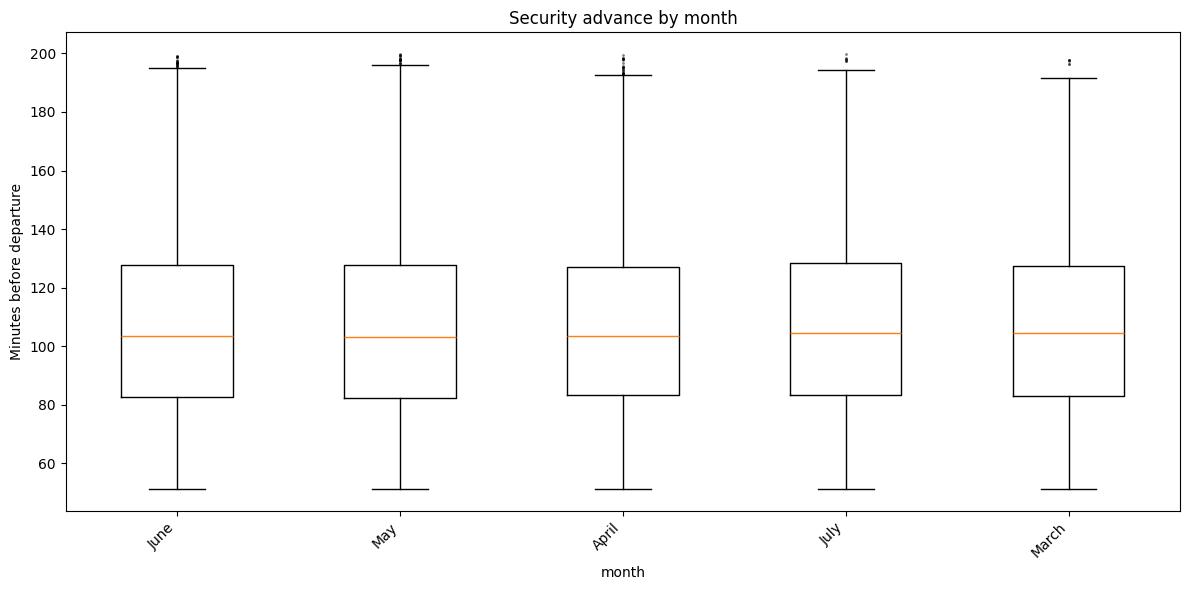

In [85]:
by_month = plot_boxplot(
    df_arrivals_clean,
    "month"
)

by_month

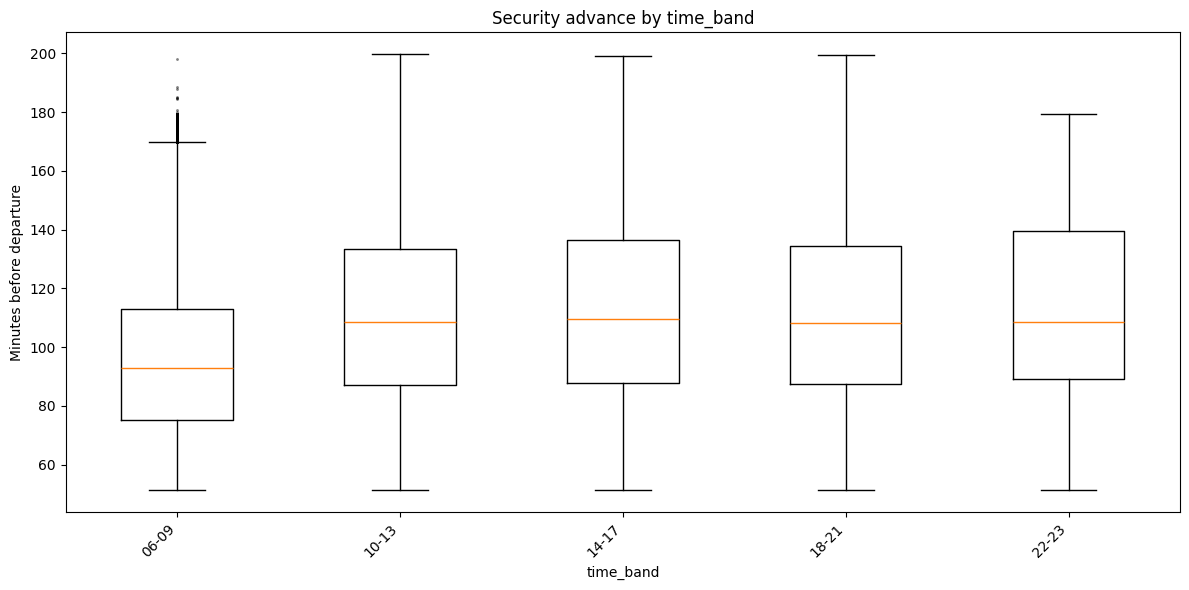

In [86]:
by_time = plot_boxplot(
    df_arrivals_clean,
    "time_band",
    min_count=1
)
by_time

#### normalizing flows

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import zuko

torch.manual_seed(42)
np.random.seed(42)

df_nf = df_arrivals_clean.copy()
df_nf["log_advance"] = np.log(df_nf["advance"])

cat_cols = ["car", "month", "time_band", "apt"]
MIN_FREQ = 10

code_lookup = {}
cardinalities = {}

for col in cat_cols:
    counts = df_nf[col].value_counts()
    keep = set(counts[counts >= MIN_FREQ].index)
    categories = sorted(keep) + ["UNK"]
    lookup = {cat: i for i, cat in enumerate(categories)}

    df_nf[col + "_code"] = df_nf[col].where(df_nf[col].isin(keep), "UNK").map(lookup)
    code_lookup[col] = lookup
    cardinalities[col] = len(categories)

print("cardinalità (incluso UNK):", cardinalities)

# split per volo
df_nf["flight_key"] = df_nf["flight_number"] + "_" + df_nf["DATE_OF_FLIGHT"].astype(str)

unique_flights = df_nf["flight_key"].unique()
rng = np.random.default_rng(42)
rng.shuffle(unique_flights)

n_val = int(0.15 * len(unique_flights))
val_flights = set(unique_flights[:n_val])
df_nf["is_val"] = df_nf["flight_key"].isin(val_flights)

train_df = df_nf[~df_nf["is_val"]].reset_index(drop=True)
val_df = df_nf[df_nf["is_val"]].reset_index(drop=True)

# standardizzazione log_advance (mean=0, std=1)
log_adv_mean = train_df["log_advance"].mean()
log_adv_std = train_df["log_advance"].std()

train_df["log_advance_std"] = (train_df["log_advance"] - log_adv_mean) / log_adv_std
val_df["log_advance_std"] = (val_df["log_advance"] - log_adv_mean) / log_adv_std

code_cols = [c + "_code" for c in cat_cols]

class AdvanceDataset(Dataset):
    def __init__(self, frame):
        self.y = torch.tensor(frame["log_advance_std"].to_numpy(), dtype=torch.float32).unsqueeze(-1)
        self.cats = torch.tensor(frame[code_cols].to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.y[idx], self.cats[idx]

train_loader = DataLoader(AdvanceDataset(train_df), batch_size=1024, shuffle=True)
val_loader = DataLoader(AdvanceDataset(val_df), batch_size=4096, shuffle=False)

cardinalità (incluso UNK): {'car': 17, 'month': 6, 'time_band': 6, 'apt': 26}


In [47]:
class Embedder(nn.Module):
    def __init__(self, cardinalities, embed_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, embed_dim) for card in cardinalities.values()
        ])

    def forward(self, cats):
        parts = [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)]
        return torch.cat(parts, dim=-1)

embed_dim = 8
embedder = Embedder(cardinalities, embed_dim=embed_dim)
context_dim = embed_dim * len(cat_cols)

flow = zuko.flows.NSF(
    features=1,
    context=context_dim,
    transforms=3,
    hidden_features=(64, 64),
)

optimizer = torch.optim.Adam(
    list(embedder.parameters()) + list(flow.parameters()),
    lr=1e-3,
)

def run_epoch(loader, train=True):
    embedder.train(train)
    flow.train(train)
    total_loss, n = 0.0, 0

    for y, cats in loader:
        context = embedder(cats)
        dist = flow(context)
        loss = -dist.log_prob(y).mean()

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * len(y)
        n += len(y)

    return total_loss / n

best_val = float("inf")
patience, bad_epochs = 8, 0
best_state = None

for epoch in range(200):
    train_nll = run_epoch(train_loader, train=True)
    with torch.no_grad():
        val_nll = run_epoch(val_loader, train=False)

    print(f"epoch {epoch+1:03d}  train NLL {train_nll:.4f}  val NLL {val_nll:.4f}")

    if val_nll < best_val:
        best_val = val_nll
        bad_epochs = 0
        best_state = (
            {k: v.clone() for k, v in embedder.state_dict().items()},
            {k: v.clone() for k, v in flow.state_dict().items()},
        )
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"early stopping all'epoca {epoch+1} (miglior val NLL: {best_val:.4f})")
            break

embedder.load_state_dict(best_state[0])
flow.load_state_dict(best_state[1])

epoch 001  train NLL 1.3169  val NLL 1.2962
epoch 002  train NLL 1.2959  val NLL 1.2985
epoch 003  train NLL 1.2918  val NLL 1.2931
epoch 004  train NLL 1.2881  val NLL 1.2901
epoch 005  train NLL 1.2854  val NLL 1.2937
epoch 006  train NLL 1.2852  val NLL 1.2874
epoch 007  train NLL 1.2834  val NLL 1.2939
epoch 008  train NLL 1.2824  val NLL 1.2904
epoch 009  train NLL 1.2810  val NLL 1.2890
epoch 010  train NLL 1.2803  val NLL 1.2904
epoch 011  train NLL 1.2813  val NLL 1.2889
epoch 012  train NLL 1.2779  val NLL 1.2910
epoch 013  train NLL 1.2786  val NLL 1.2879
epoch 014  train NLL 1.2775  val NLL 1.2900
early stopping all'epoca 14 (miglior val NLL: 1.2874)


<All keys matched successfully>

In [48]:
def encode_value(col, value):
    lookup = code_lookup[col]
    return lookup.get(value, lookup["UNK"])

def sample_advance(car, month, time_band, apt, n_samples=5000):
    codes = [encode_value(c, v) for c, v in zip(cat_cols, [car, month, time_band, apt])]
    cats_tensor = torch.tensor([codes] * n_samples, dtype=torch.long)

    embedder.eval()
    flow.eval()
    with torch.no_grad():
        context = embedder(cats_tensor)
        z_samples = flow(context).sample()

    log_adv_samples = z_samples.squeeze(-1) * log_adv_std + log_adv_mean
    return torch.exp(log_adv_samples).numpy()

#### Validation

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\3716960570.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()


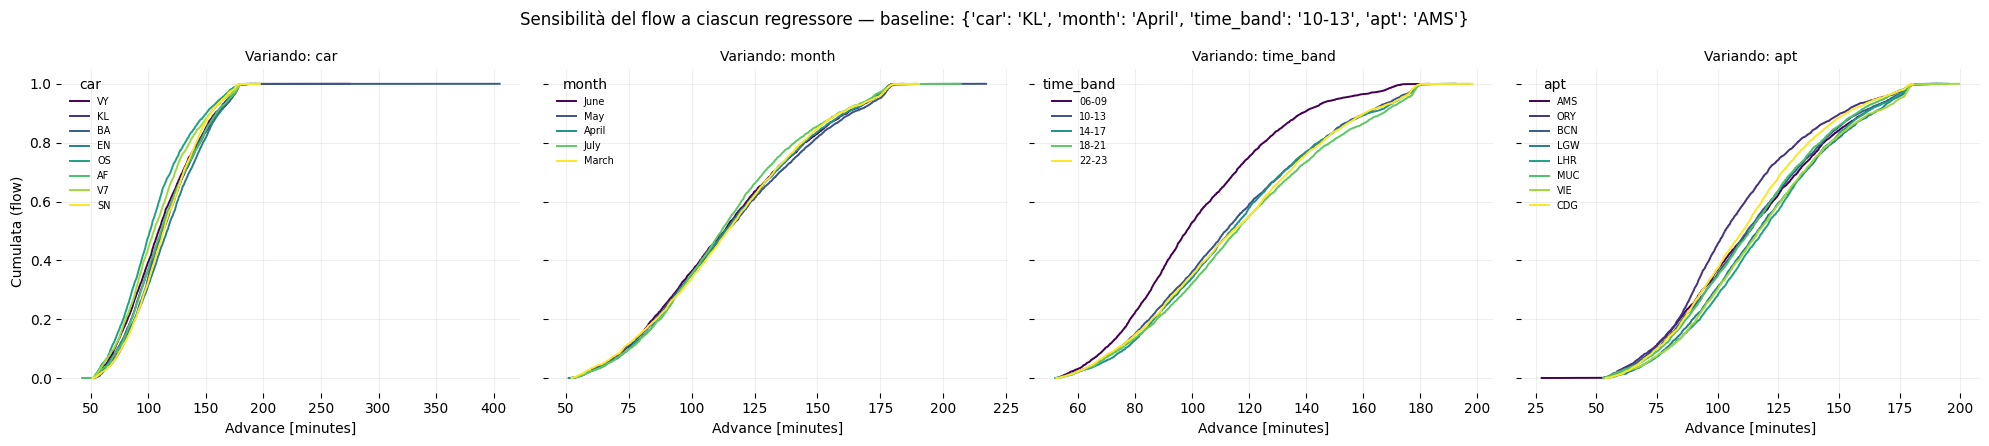

In [51]:
TIME_BAND_ORDER = ["00-05", "06-09", "10-13", "14-17", "18-21", "22-23"]
BASE_COMBO = dict(zip(
    cat_cols,
    train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()
))

TOP_N = 8  # valori più frequenti da confrontare per categoria, altrimenti apt/car sono illeggibili

fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4.5), sharey=True)

for ax, cat in zip(axes, cat_cols):
    if cat == "time_band":
        top_values = [v for v in TIME_BAND_ORDER if v in train_df["time_band"].unique()]
    else:
        top_values = (
            train_df.groupby(cat)["flight_key"].nunique()
            .sort_values(ascending=False)
            .head(TOP_N)
            .index
        )

    colors = plt.cm.viridis(np.linspace(0, 1, len(top_values)))

    for value, color in zip(top_values, colors):
        combo = {**BASE_COMBO, cat: value}
        sampled = sample_advance(combo["car"], combo["month"], combo["time_band"], combo["apt"], n_samples=3000)
        s = np.sort(sampled)
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=color, linewidth=1.4, label=str(value))

    ax.set_title(f"Variando: {cat}", fontsize=10)
    ax.set_xlabel("Advance [minutes]")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7, title=cat)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Cumulata (flow)")
fig.suptitle(f"Sensibilità del flow a ciascun regressore — baseline: {BASE_COMBO}")
plt.tight_layout()

#### save for production

In [52]:
torch.save({
    "embedder_state": embedder.state_dict(),
    "flow_state": flow.state_dict(),
    "code_lookup": code_lookup,
    "cardinalities": cardinalities,
    "cat_cols": cat_cols,
    "log_adv_mean": log_adv_mean,
    "log_adv_std": log_adv_std,
    "embed_dim": embed_dim,
    "transforms": 3,
    "hidden_features": (64, 64),
}, f"data/arrival_flow.pt")

### Allocation

#### single funcs

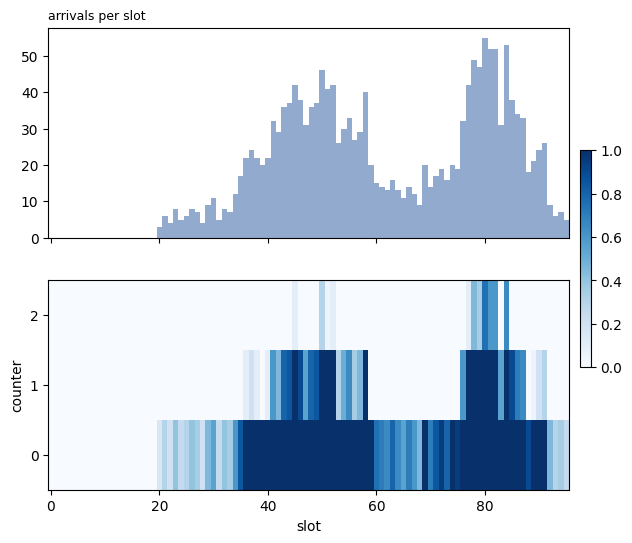

In [16]:
def _synthetic_day(seed, T=96, baseline=5, start=20):
    rng = np.random.default_rng(seed)
    t = np.arange(T)

    lam = np.full(T, baseline, dtype=float)

    for _ in range(2):
        center = rng.uniform(10, T - 10)
        width = rng.uniform(4, 9)
        height = rng.uniform(30, 70)

        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    lam[:start] = 0

    return rng.poisson(lam).astype(int).tolist()

from app.services.security_class import arrivals_to_demand_grid

def plot_grid(arrivals, D):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

arrivals = _synthetic_day(seed=1)

registry={
    1: {'label': '1', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 20, 'processing_unit': 15, 'priority': 1},
    4: {'label': '4', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 20, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, 15)

rates_in_order = [rate_by_label[l] for l in server_labels]

grid = arrivals_to_demand_grid(arrivals, utils.mean_processing_rate(server_registry))
plot_grid(arrivals, grid)

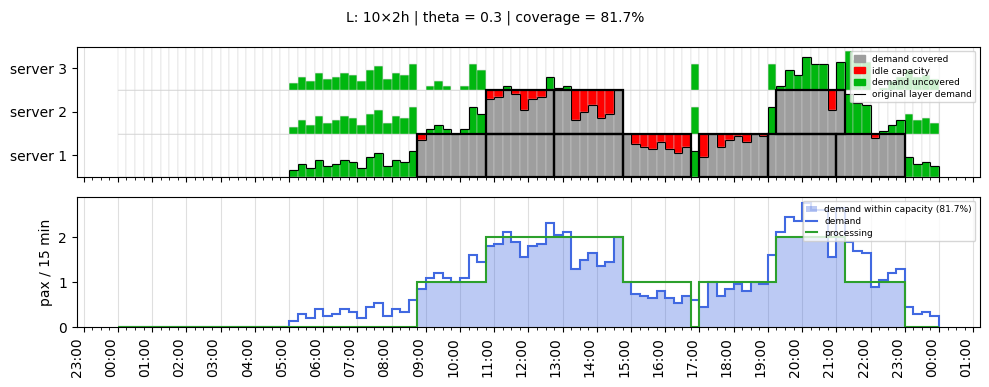

In [17]:
from app.services.coverage_dp import solve_coverage_batch_multi, allocate_milp, solve_allocated_multi, effective_grid, coverage_report_multi

lengths=[8]
theta=0.3
K_total= 20
length_totals={8:10}

curves = solve_coverage_batch_multi(grid, lengths, theta)
alloc = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
sols = solve_allocated_multi(grid, theta, alloc, inherit=True)

D_eff = effective_grid(grid, [s.coverage for s in sols])
time_values = pd.date_range("2026-06-01 00:00", periods=grid.shape[1], freq="15min")

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = [str(r + 1) for r in range(grid.shape[0])]
blocks = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)]
          for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)                                                   # domanda in "lane"
proc = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)   # lane aperte per slot

plotutils.plot_blocks(D=D_eff, D_ref=grid, blocks=blocks, labels=labels, time_values=time_values, theta=theta, bin_minutes=15,
                      demand_curve=rho, processing_curve=proc)

#### class and synthetic arrivals

2026-11-25 09:58:06,690 | INFO | app.services.security_class | [SecurityPlanner] running


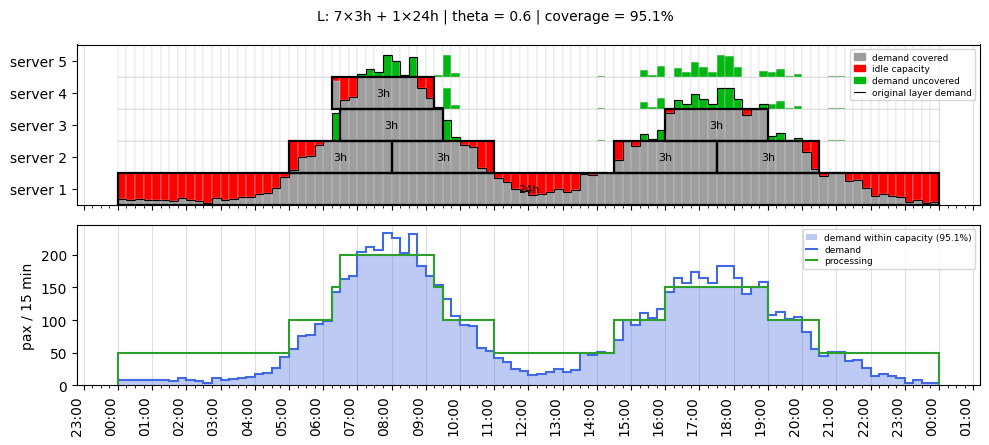

In [18]:
def make_synthetic_arrivals(
    pax_per_server_bin: float,
    peak_servers=(4.2, 3.4),
    peak_hours=(8.0, 17.5),
    widths_h=(1.6, 2.0),
    base_servers=0.15,
    day="2026-03-02",
    bin_minutes=15,
    seed=0,
) -> pd.Series:
    T = 24 * 60 // bin_minutes
    t_h = (np.arange(T) + 0.5) * bin_minutes / 60                      # centro del bin, in ore
    servers_needed = np.full(T, base_servers)
    for hour, width, amp in zip(peak_hours, widths_h, peak_servers):
        servers_needed += amp * np.exp(-0.5 * ((t_h - hour) / width) ** 2)
    rng = np.random.default_rng(seed)
    index = pd.date_range(day, periods=T, freq=f"{bin_minutes}min")
    return pd.Series(rng.poisson(servers_needed * pax_per_server_bin).astype(float),
                     index=index, name="arrivals")

BIN_MINUTES = 15
arrivals = make_synthetic_arrivals(50, seed=1)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    7: {'label': '7', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    8: {'label': '8', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

planner = security_class.SecurityPlanner(arrivals=arrivals, server_registry=server_registry)

lengths = [3]
theta = 0.6
K_total = 100
length_totals = {3: 15}

res = planner.run(lengths=lengths, theta=theta, K_total=K_total, length_totals=length_totals, first_server=True)

plotutils.plot_allocation(res)

#### from schedule (single day)

In [190]:
date=dt.datetime(2026, 6, 19)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
arrivals= samplers.expected_arrivals(flight_demand)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-11-26 18:24:03,179 | WARNING | app.services.preprocessing | More than 10% of flights (13/66) fall back to the unknown arrival sampler. Check the arrival model coverage.


2026-11-26 18:24:03,197 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 18:24:03,246 | INFO | app.services.security_class | [SecuritySimulator] 1 total tasks, 4 workers


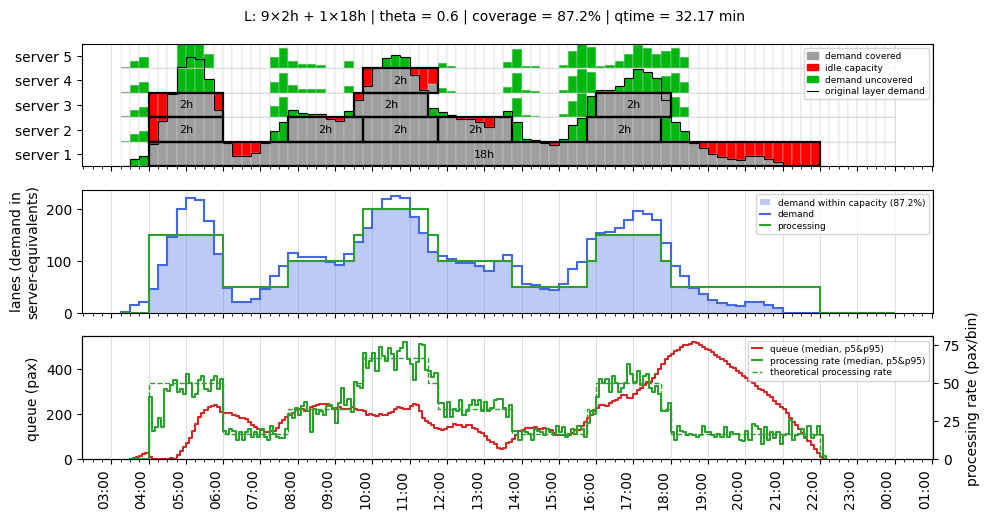

In [191]:
lengths = [2]
theta = 0.6
K_total = 100
length_totals = {}

planner = security_class.SecurityPlanner(arrivals=arrivals, server_registry=server_registry)
res = planner.run(lengths=lengths, theta=theta, K_total=K_total, length_totals=length_totals, first_server=("04:00", "22:00"), inherit=True)

classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)
sim_results = classe2.run(n_scenarios=1, n_workers=4, timebin=5, base_seed=base_seed,)

plotutils.plot_allocation(res, df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis)

fluid 59.96 min | simulatore 58.39 min


array([<Axes: xlabel='time'>, <Axes: xlabel='time'>,
       <Axes: xlabel='time'>], dtype=object)

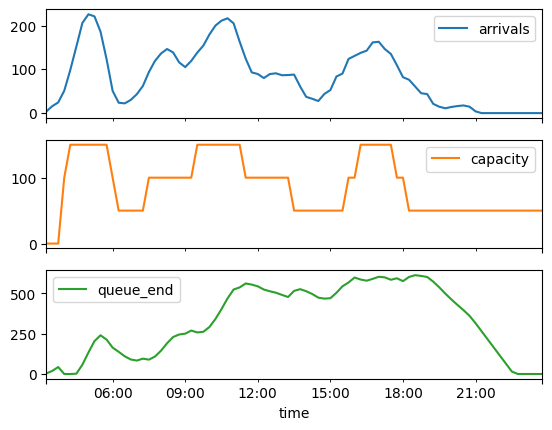

In [6]:
from app.services.fluid_approx import fluid_from_result

q_fluid, diag = fluid_from_result(res)
q_sim = sim_results.df_kpis["qtime_mean"].iloc[0]        # attesa media del simulatore
print(f"fluid {q_fluid:.2f} min | simulatore {q_sim:.2f} min")
diag[["arrivals", "capacity", "queue_end"]].plot(subplots=True)

#### from schedule (multiple day) ! DA SISTEMARE!!

In [2]:
dates = pd.date_range("2026-06-01", periods=5, freq="D")

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"].isin(dates)].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
arrivals= security_class.expected_arrivals(flight_demand)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-28 12:08:01,091 | WARNING | app.services.preprocessing | More than 10% of flights (54/306) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [ ]:
lengths=[4, 1.5]
theta=0.7
K_total=1000
length_per_day={4:10, 1.5:15}

planner = security_class.MultiDayPlanner(arrivals, server_registry)

res = planner.run(lengths=lengths, theta=0.5, K_total=K_total, length_per_day=length_per_day)

2026-10-19 16:10:37,093 | INFO | app.services.security_class | [MultiDayPlanner] curves: 5 days x 5 layers, lengths=[1.5, 4.0] h, alpha=0.50


In [4]:
planner.report_by_day()

,n_blocks,demand,covered_demand,missed_demand,idle_capacity,coverage,objective,n_blocks_6,n_blocks_16
day,,,,,,,,,
2026-06-01,16,138.16,129.714531,8.445469,16.285469,0.938872,121.571797,11,5
2026-06-02,17,129.90,122.866786,7.033214,19.133214,0.945857,113.300179,13,4
2026-06-03,16,117.02,109.130430,7.889570,16.869570,0.932579,100.695645,13,3
2026-06-04,16,128.78,119.050174,9.729826,16.949826,0.924446,110.575261,12,4
2026-06-05,18,142.04,134.869670,7.170330,23.130330,0.949519,123.304505,13,5


In [ ]:
for n, r in enumerate(res.day_results):
    print(planner.days[n].date())
    plotutils.plot_allocation(r, show_second=False)

#### Perturbation test

##### using simulation

In [3]:
from app.services.perturbation import *
import app.services.simulation_batch as sb  
import app.services.local_search as ls

date=dt.datetime(2026, 6, 1)

out_path = os.path.join("data", f"perturbation_study_{date.date()}.xlsx")
waits_dir = os.path.join("data", f"waits_{date.date()}")
os.makedirs(waits_dir, exist_ok=True)

In [ ]:
schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
arrivals= samplers.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

# plotutils.save_context(planner, os.path.join("data", f"context_{date.date()}.npz"))

2026-11-20 16:49:05,577 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


2026-11-20 16:49:10,083 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 16:49:10,137 | INFO | app.services.security_class | [SecuritySimulator] 1 total tasks, 4 workers


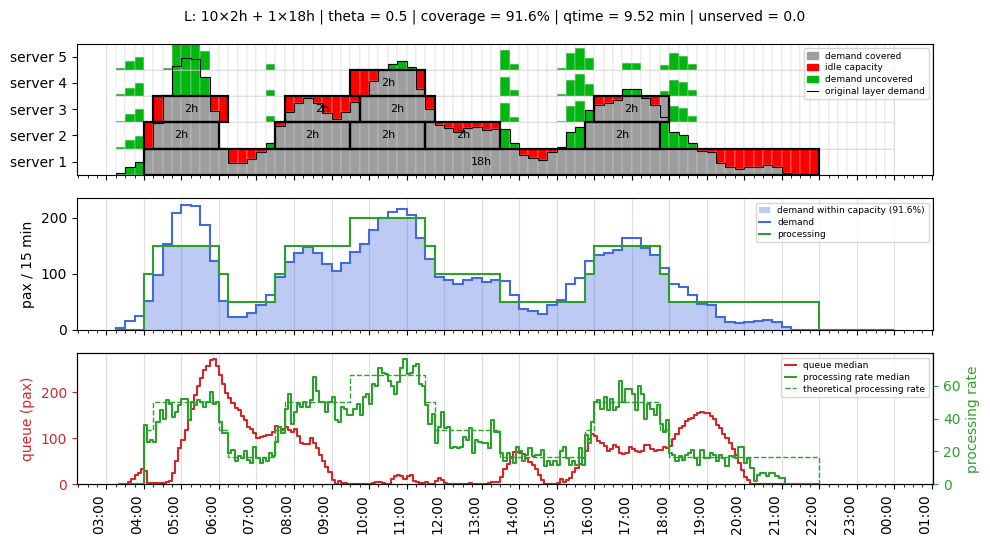

In [5]:
# first test before launching perturbation loop

lengths = [2]
theta = 0.5
K_total = 100
length_totals = {2: 25}

arrivals= samplers.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals=arrivals, server_registry=server_registry)
res = planner.run(lengths=lengths, theta=theta, K_total=K_total, length_totals=length_totals, first_server=("04:00", "22:00"))

classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)
sim_results = classe2.run(n_scenarios=1, n_workers=4, timebin=5, base_seed=base_seed)

plotutils.plot_allocation(res, df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis)

In [ ]:
from app.services.simulation_batch import simulate_kpis

lengths = [2]
K_total = 100
length_totals = {2: 25}

theta_step = 0.1
first_server = ("04:00", "22:00")
max_moves = 5
n_reps = 199
step = 3
batch_id = 0

fs_txt = str(first_server)

T = planner.demand_grid.shape[1]
N_pax = float(planner.arrivals.sum())
arr_np = planner.arrivals.to_numpy()

df_prev = pd.read_excel(out_path) if os.path.exists(out_path) else pd.DataFrame()
if len(df_prev):
    if "batch" not in df_prev:
        df_prev["batch"] = 0
    if "first_server" not in df_prev:
        df_prev["first_server"] = "None"
    df_prev["first_server"] = df_prev["first_server"].astype(str)
rows = df_prev.to_dict("records")
done = ({(round(a, 6), int(b), c) for a, b, c in zip(df_prev["theta"], df_prev["batch"], df_prev["first_server"])}
        if len(df_prev) else set())
rep = int(df_prev["rep"].max()) + 1 if len(df_prev) else 0

for theta_i in np.arange(0.0, 0.8, theta_step):
    theta_i = round(float(theta_i), 6)
    if (theta_i, batch_id, fs_txt) in done:
        print(f"theta={theta_i}, batch={batch_id}, first_server={fs_txt}: already in {out_path}, skipped")
        continue
    res_a = planner.run(lengths=lengths, length_totals=length_totals, theta=theta_i, K_total=K_total,
                        first_server=first_server)

    bounds = res_a.first_server_window and (res_a.first_server_window[0], res_a.first_server_window[0] + res_a.first_server_window[1])

    base = schedule_to_blocks(planner, res_a)
    fixed_labels = {res_a.server_labels[0]} if first_server else set()
    n_blocks = sum(len(v) for v in base.values())
    n_movable = sum(len(v) for lab, v in base.items() if lab not in fixed_labels)
    if n_movable == 0:
        print(f"theta={theta_i}: no movable windows, skipped")
        continue

    rng = np.random.default_rng([42, int(round(theta_i * 1000)), batch_id])

    mine = [r for r in rows if np.isclose(r["theta"], theta_i) and str(r["first_server"]) == fs_txt]
    seen = {r["blocks"] for r in mine} | {blocks_to_json(base)}
    offset = len(mine)

    # 1) schedule del lotto
    schedules = [(base, [])] if batch_id == 0 else []
    target = n_reps + (1 if batch_id == 0 else 0)
    for _ in range(20 * n_reps):
        if len(schedules) >= target:
            break
        k = int(rng.integers(1, max_moves + 1))
        blocks, moves = perturb_blocks(base, T, k, rng, step=step, fixed=fixed_labels, bounds=bounds)
        key = blocks_to_json(blocks)
        if key in seen:
            continue
        seen.add(key)
        schedules.append((blocks, moves))

    print(f"theta={theta_i}, batch={batch_id}: {len(schedules)} new schedules")
    if not schedules:
        continue

    # 2) simulazioni
    intervals_list = [utils.server_schedule_to_intervals(blocks_to_schedule(planner, b)) for b, _ in schedules]
    chunk = 100
    parts, tl_parts, waits_all = [], [], []
    for i0 in range(0, len(intervals_list), chunk):
        df_kpis, timelines, waits = simulate_kpis(
            flight_demand, intervals_list[i0:i0 + chunk], server_registry,
            n_scenarios=50, n_workers=os.cpu_count(), timebin=15,
            base_seed=base_seed, return_timeline=True, return_waits=True)
        parts.append(df_kpis); tl_parts += timelines; waits_all += waits
    kpis = pd.concat(parts, ignore_index=True)

    wfile = f"waits_theta{theta_i}_b{batch_id}.npz"
    np.savez_compressed(
        os.path.join(waits_dir, wfile),
        **{f"{offset + j}|s{s}": w for j, ws in enumerate(waits_all) for s, w in enumerate(ws)})

    # 3) coda fluida, righe
    for j, (blocks, moves) in enumerate(schedules):
        rep_theta = offset + j
        k = kpis.iloc[j]
        q_f, u_f = ls.fluid_metrics(arr_np, planner.rate_by_label, blocks, planner.bin_minutes)
        q_s, u_s = float(k["qtime_mean"]), float(k["n_unserved"])

        rows.append(dict(
            date=date, lengths=str(lengths), length_totals=str(length_totals), K_total=K_total,
            theta=theta_i, first_server=fs_txt,
            batch=batch_id, n_blocks=n_blocks, rep=rep, rep_theta=rep_theta,
            is_baseline=(batch_id == 0 and j == 0), n_pax=N_pax,
            **coverage_from_blocks(planner, res_a, blocks),
            coverage=compute_coverage(arr_np, planner.rate_by_label, blocks),
            q_fluid=q_f, unserved_fluid=u_f,
            qtime_mean=q_s, n_unserved=u_s, qtime_above_30_pct=k["qtime_above_30_pct"],
            n_moves=len(moves), moves=json.dumps(moves), blocks=blocks_to_json(blocks),
            waits_file=wfile,
            timeline=json.dumps(tl_parts[j])))
        rep += 1

    pd.DataFrame(rows).to_excel(out_path, index=False)
    print(f"theta={theta_i}, batch={batch_id}: saved")

df_pert = pd.DataFrame(rows)

2026-11-05 11:53:36,303 | INFO | app.services.security_class | [SecurityPlanner] lengths=[2.0] h, theta=0.00, first_server=('04:00', '22:00')


theta=0.0, batch=0: 200 new schedules


2026-11-05 12:09:36,650 | INFO | app.services.security_class | [SecurityPlanner] lengths=[2.0] h, theta=0.10, first_server=('04:00', '22:00')


theta=0.0, batch=0: saved
theta=0.1, batch=0: 200 new schedules


2026-11-05 12:25:25,555 | INFO | app.services.security_class | [SecurityPlanner] lengths=[2.0] h, theta=0.20, first_server=('04:00', '22:00')


theta=0.1, batch=0: saved
theta=0.2, batch=0: 200 new schedules


... (6 outputs left out)

2026-11-05 13:12:40,164 | INFO | app.services.security_class | [SecurityPlanner] lengths=[2.0] h, theta=0.60, first_server=('04:00', '22:00')


theta=0.5, batch=0: saved
theta=0.6, batch=0: 200 new schedules


2026-11-05 13:30:05,500 | INFO | app.services.security_class | [SecurityPlanner] lengths=[2.0] h, theta=0.70, first_server=('04:00', '22:00')


theta=0.6, batch=0: saved
theta=0.7, batch=0: 200 new schedules
theta=0.7, batch=0: saved


In [6]:
date=dt.datetime(2026, 6, 1)
df_pert = pd.read_excel(os.path.join("data", f"perturbation_study_{date.date()}.xlsx"))
df_pert

,date,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,rep_theta,...,q_fluid,unserved_fluid,qtime_mean,n_unserved,qtime_above_30_pct,n_moves,moves,blocks,waits_file,timeline
0,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,0,0,...,0.102600,0,0.390526,0,0.045455,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,1,1,...,0.102600,0,0.373120,0,0.045455,1,"[[""5"", 1, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
2,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,2,2,...,0.125298,0,0.437667,0,0.045455,3,"[[""4"", 0, 3], [""3"", 0, 3], [""3"", 1, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
3,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,3,3,...,0.282182,0,0.737138,0,0.045455,4,"[[""2"", 5, -3], [""4"", 0, 3], [""4"", 1, -3], [""3""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
4,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,4,4,...,1.941214,0,2.305132,0,0.045455,3,"[[""4"", 2, -3], [""5"", 1, 3], [""2"", 6, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1595,195,...,113.184551,0,115.876500,0,91.342212,5,"[[""2"", 1, -3], [""3"", 0, 3], [""3"", 1, -3], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [14, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1596,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1596,196,...,114.354820,0,114.116671,0,94.794152,4,"[[""2"", 1, -3], [""2"", 2, -3], [""2"", 0, 3], [""3""...","{""1"": [[3, 72]], ""2"": [[6, 8], [14, 8], [22, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1597,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1597,197,...,115.790254,0,118.649585,0,91.342212,2,"[[""3"", 0, 3], [""2"", 4, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1598,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1598,198,...,113.184728,0,116.026097,0,91.342212,3,"[[""2"", 4, 3], [""3"", 1, -3], [""3"", 0, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."


C:\Users\zanch\AppData\Local\Temp\ipykernel_3692\723951831.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  fig.legend(loc="upper right")


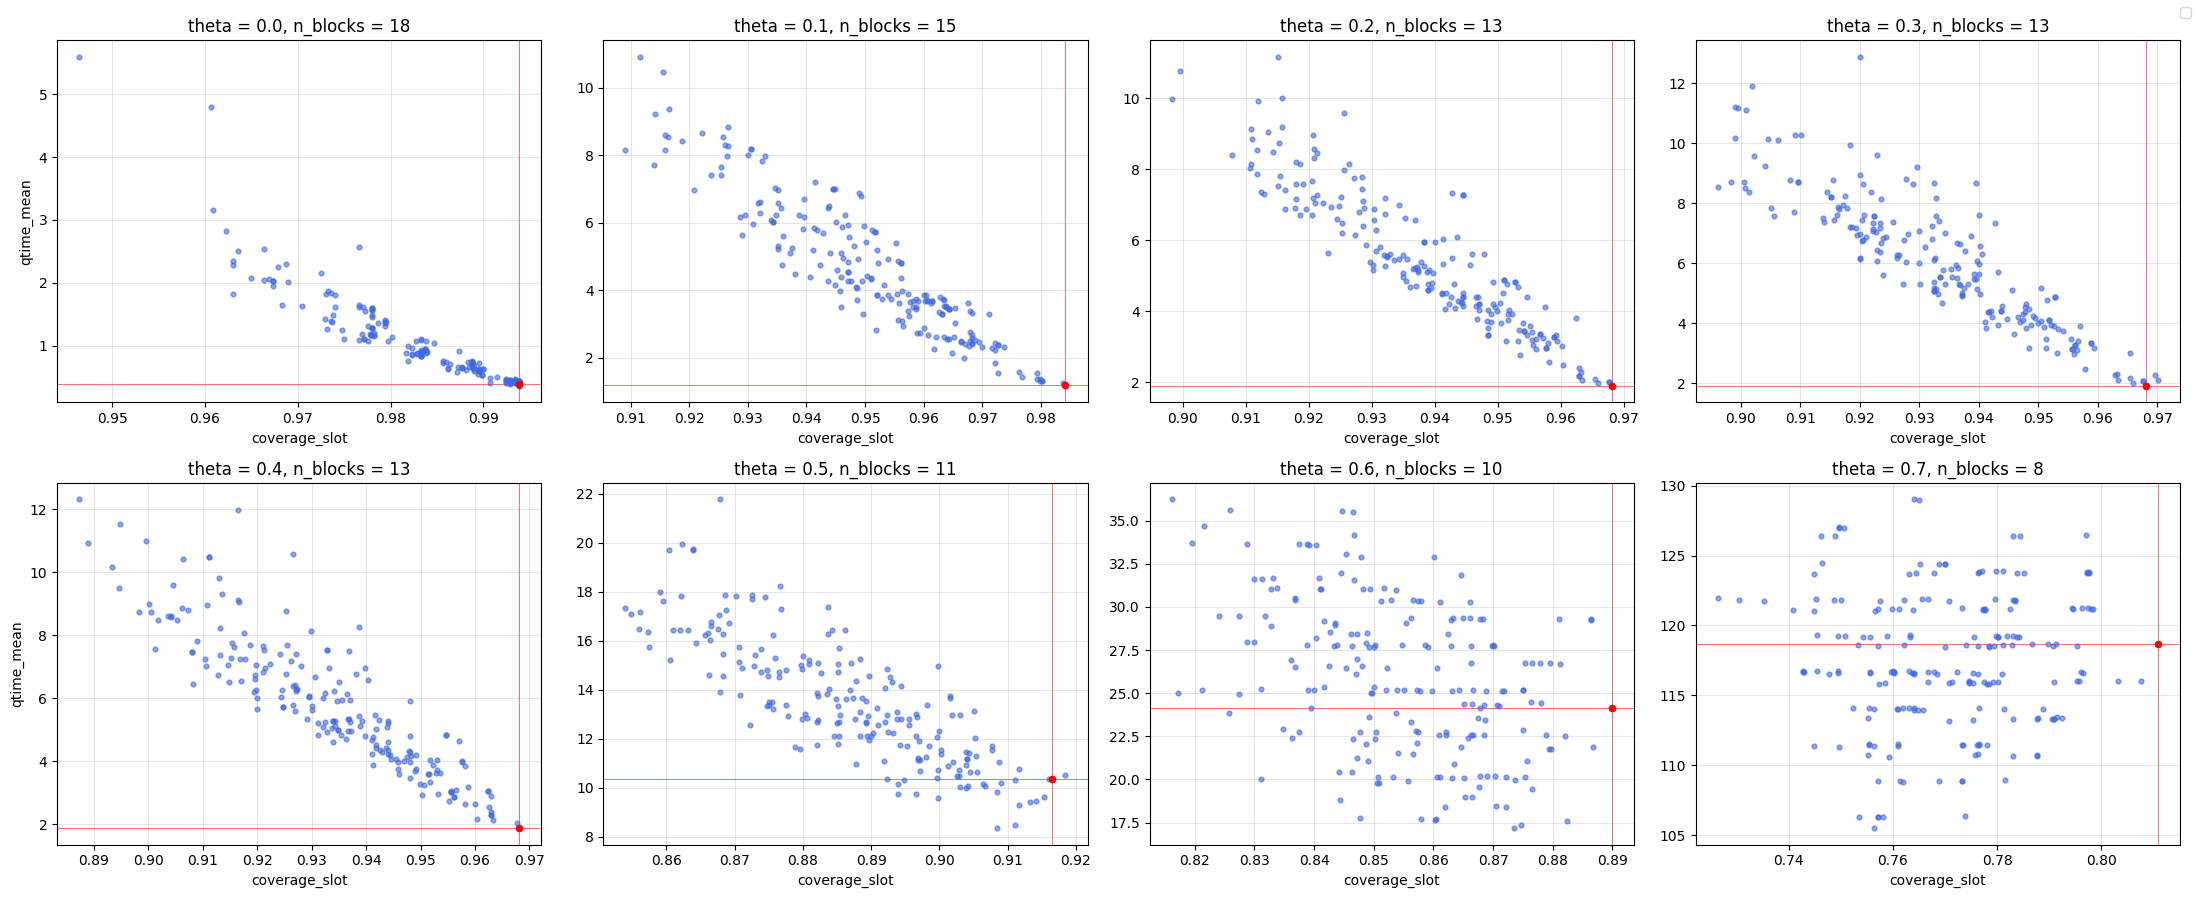

In [ ]:
import math
from matplotlib.lines import Line2D

x, y = "coverage", "qtime_mean"
max_cols = 4
theta_in = sorted(df_pert["theta"].unique())
theta_in= [x for x in theta_in if x <= 0.7]

n_rows = math.ceil(len(theta_in) / max_cols)
n_cols = min(len(theta_in), max_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows), squeeze=False)
flat = axes.ravel()
for ax, a in zip(flat, theta_in):
    d = df_pert[df_pert["theta"] == a]
    ax.scatter(d[x], d[y], s=12, marker="o", color="royalblue", alpha=0.6, zorder=2)

    if d["is_baseline"].any():
        b = d[d["is_baseline"]].iloc[0]
        ax.scatter(b[x], b[y], s=20, marker="o",
                   color="red", linewidths=1, zorder=3) 
        ax.axhline(b[y], color="red", linewidth=0.4, zorder=0)
        ax.axvline(b[x], color="red", linewidth=0.4, zorder=0)
    ax.set_title(f"theta = {a}, n_blocks = {d['n_blocks'].iloc[0]}")
    ax.set_xlabel(x)
    ax.grid(color="gray", alpha=0.2)

for ax in flat[len(theta_in):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel(y)
fig.legend(loc="upper right")
plt.tight_layout()
plt.show()

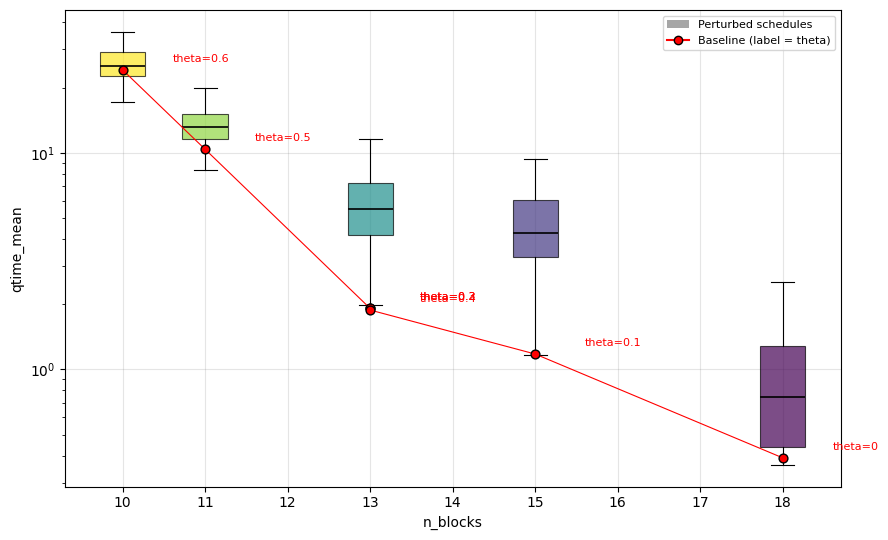

In [44]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib import cm, colors
from matplotlib.patches import Patch

x, y = "n_blocks", "qtime_mean"
u_col, u_tol = "n_unserved", 0.0
theta_max = 0.6

d = df_pert[df_pert["theta"] <= theta_max].copy()
pert = d[~d["is_baseline"]]
base = d[d["is_baseline"]].sort_values([x, "theta"])

fig, ax = plt.subplots(figsize=(9, 5.5))

groups = [
    (n, g)
    for n, g in pert.groupby(x)
    if g[y].notna().any()
]

positions = [n for n, g in groups]
values = [g[y].dropna().values for n, g in groups]

norm = colors.Normalize(vmin=d["theta"].min(), vmax=d["theta"].max())
cmap = plt.get_cmap("viridis")

bp = ax.boxplot(
    values,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops=dict(color="black", linewidth=1.2),
    whiskerprops=dict(linewidth=0.8),
    capprops=dict(linewidth=0.8),
    boxprops=dict(linewidth=0.8),
    manage_ticks=False
)

for box, (_, g) in zip(bp["boxes"], groups):
    box.set_facecolor(cmap(norm(g["theta"].mean())))
    box.set_alpha(0.7)

ax.plot(base[x], base[y], "-", color="red", linewidth=0.8, zorder=3)
ax.scatter(base[x], base[y],s=40, color="red", edgecolor="black", zorder=4)

for _, r in base.iterrows():
    ax.annotate(
        f"theta={r['theta']:g}",
        (r[x]+0.5, r[y]),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8,
        color="red"
    )

ax.set_xlabel("n_blocks")
ax.set_ylabel(y)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(color="gray", alpha=0.2)

handles = [
    Patch(facecolor="gray", alpha=0.7, label="Perturbed schedules"),
    Line2D(
        [], [], marker="o", color="red",
        markeredgecolor="black", linestyle="-",
        label="Baseline (label = theta)"
    )
]
ax.set_yscale("log")

ax.legend(handles=handles, loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

In [61]:
df_pert

,date,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,rep_theta,...,q_fluid,unserved_fluid,qtime_mean,n_unserved,qtime_above_30_pct,n_moves,moves,blocks,waits_file,timeline
0,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,0,0,...,0.102600,0,0.390526,0,0.045455,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,1,1,...,0.102600,0,0.373120,0,0.045455,1,"[[""5"", 1, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
2,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,2,2,...,0.125298,0,0.437667,0,0.045455,3,"[[""4"", 0, 3], [""3"", 0, 3], [""3"", 1, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
3,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,3,3,...,0.282182,0,0.737138,0,0.045455,4,"[[""2"", 5, -3], [""4"", 0, 3], [""4"", 1, -3], [""3""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
4,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,4,4,...,1.941214,0,2.305132,0,0.045455,3,"[[""4"", 2, -3], [""5"", 1, 3], [""2"", 6, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1595,195,...,113.184551,0,115.876500,0,91.342212,5,"[[""2"", 1, -3], [""3"", 0, 3], [""3"", 1, -3], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [14, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1596,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1596,196,...,114.354820,0,114.116671,0,94.794152,4,"[[""2"", 1, -3], [""2"", 2, -3], [""2"", 0, 3], [""3""...","{""1"": [[3, 72]], ""2"": [[6, 8], [14, 8], [22, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1597,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1597,197,...,115.790254,0,118.649585,0,91.342212,2,"[[""3"", 0, 3], [""2"", 4, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1598,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1598,198,...,113.184728,0,116.026097,0,91.342212,3,"[[""2"", 4, 3], [""3"", 1, -3], [""3"", 0, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."


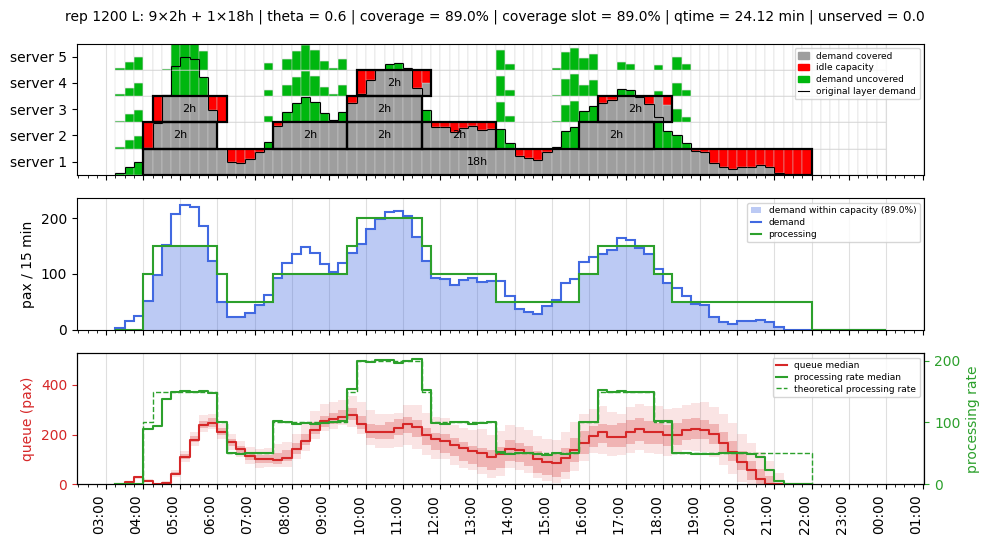

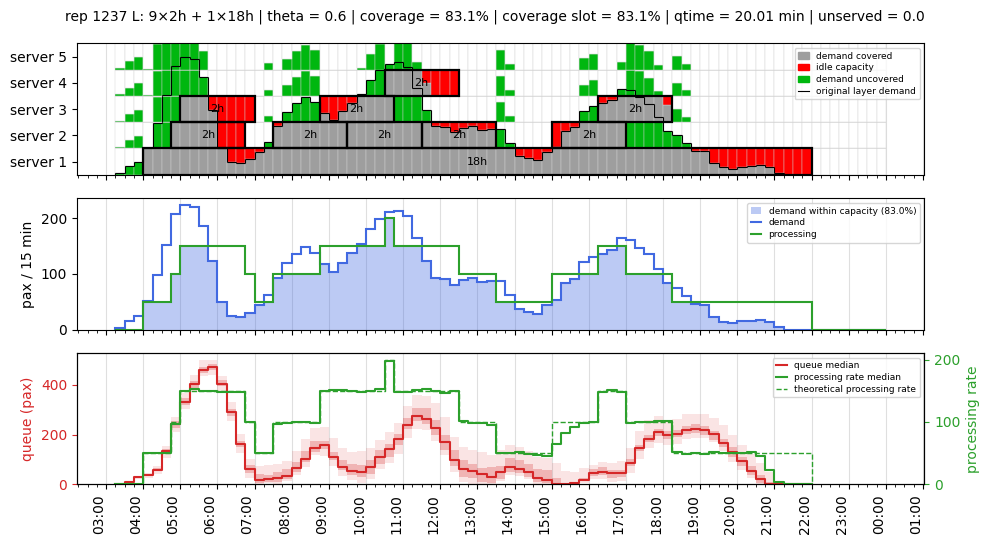

In [48]:
ctx = plotutils.load_context(os.path.join("data", f"context_{date.date()}.npz"))

r_a = df_pert[(df_pert["theta"] == 0.6) & (df_pert["rep_theta"] == 0)].iloc[0]
r_b = df_pert[(df_pert["theta"] == 0.6) & (df_pert["rep_theta"] == 37)].iloc[0]

ymax = max(sb.timeline_to_df(r["timeline"])["queue_length_p95"].max() for r in (r_a, r_b)) * 1.05

plotutils.plot_row(r_a, ctx, show_second=True, queue_max=ymax)
plotutils.plot_row(r_b, ctx, show_second=True, queue_max=ymax)

In [60]:
df_pert

,date,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,rep_theta,...,q_fluid,unserved_fluid,qtime_mean,n_unserved,qtime_above_30_pct,n_moves,moves,blocks,waits_file,timeline
0,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,0,0,...,0.102600,0,0.390526,0,0.045455,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,1,1,...,0.102600,0,0.373120,0,0.045455,1,"[[""5"", 1, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
2,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,2,2,...,0.125298,0,0.437667,0,0.045455,3,"[[""4"", 0, 3], [""3"", 0, 3], [""3"", 1, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
3,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,3,3,...,0.282182,0,0.737138,0,0.045455,4,"[[""2"", 5, -3], [""4"", 0, 3], [""4"", 1, -3], [""3""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
4,2026-06-01,[2],{2: 25},100,0.0,"('04:00', '22:00')",0,18,4,4,...,1.941214,0,2.305132,0,0.045455,3,"[[""4"", 2, -3], [""5"", 1, 3], [""2"", 6, 3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...",waits_theta0.0_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1595,195,...,113.184551,0,115.876500,0,91.342212,5,"[[""2"", 1, -3], [""3"", 0, 3], [""3"", 1, -3], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [14, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1596,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1596,196,...,114.354820,0,114.116671,0,94.794152,4,"[[""2"", 1, -3], [""2"", 2, -3], [""2"", 0, 3], [""3""...","{""1"": [[3, 72]], ""2"": [[6, 8], [14, 8], [22, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1597,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1597,197,...,115.790254,0,118.649585,0,91.342212,2,"[[""3"", 0, 3], [""2"", 4, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."
1598,2026-06-01,[2],{2: 25},100,0.7,"('04:00', '22:00')",0,8,1598,198,...,113.184728,0,116.026097,0,91.342212,3,"[[""2"", 4, 3], [""3"", 1, -3], [""3"", 0, -3]]","{""1"": [[3, 72]], ""2"": [[3, 8], [17, 8], [25, 8...",waits_theta0.7_b0.npz,"{""t0"": ""2026-06-01T03:15:00"", ""step_min"": 15.0..."


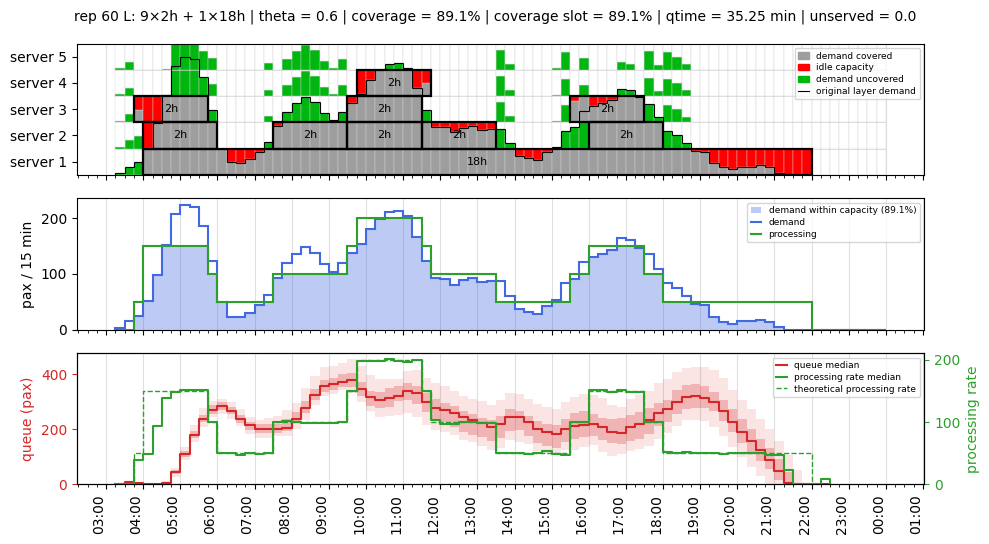

3 block 0: (2,8) -> (4,8)


2026-11-03 14:43:35,735 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 4 workers


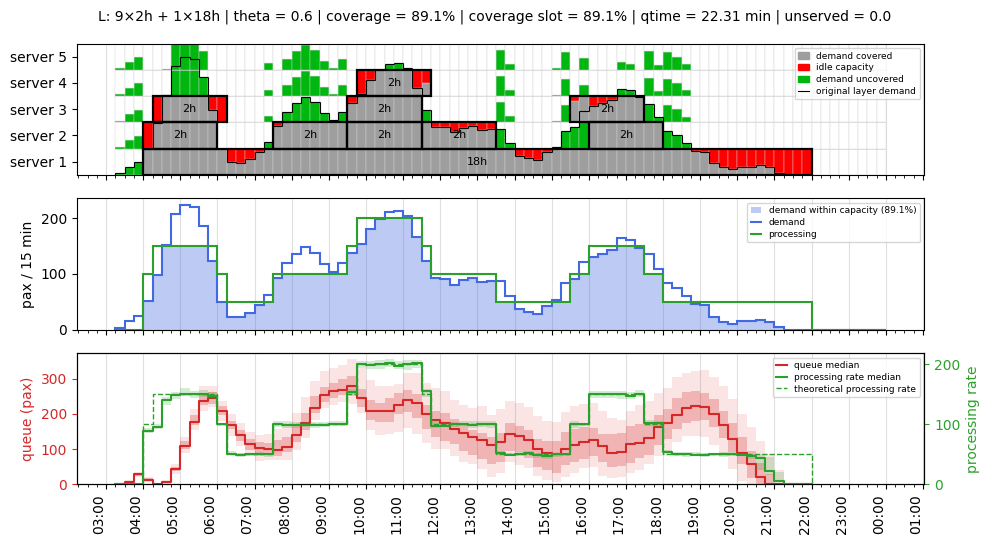

In [ ]:
# modify solution
from app.services.perturbation import *
from app.services.coverage_dp import effective_grid

ctx = plotutils.load_context(os.path.join("data", f"context_{date.date()}.npz"))
labels = list(ctx["labels"][:ctx["D"].shape[0]])
D = ctx["D"] 
T = D.shape[1]

row = df_pert[(df_pert["theta"] == 0.6) & (df_pert["rep_theta"] == 0)].iloc[0]
blocks = parse_blocks(row["blocks"])
fixed_labels = {labels[0]} if str(row["first_server"]) != "None" else set()

plotutils.plot_row(row, ctx, show_second=True)

new_blocks, log = edit_blocks(
    blocks, labels,
    edits=[dict(lane="3", block=0, shift=2)],
    T=T, add=[], fixed=fixed_labels, bounds=bounds)
print("\n".join(log))

# --- theta per riga (theta_first: mettilo se l'avevi diverso da theta) ---
theta_vec = np.full(D.shape[0], float(row["theta"]))
# theta_vec[0] = theta_first

# --- griglia con i riporti dello schedule modificato + coverage ---
cov_mask = plotutils.coverage_mask(new_blocks, labels, D.shape)
D_eff = effective_grid(D, list(cov_mask))
cov, obj, _ = plotutils.coverage_from_arrays(D_eff, new_blocks, labels, theta_vec)
coverage = float(D_eff[cov].sum() / D.sum())
q_f, u_f = ls.fluid_metrics(ctx["arrivals"], ctx["rate_by_label"], new_blocks, ctx["bin_minutes"])
coverage = compute_coverage(ctx["arrivals"], ctx["rate_by_label"], new_blocks)

proc = plotutils.processing_from_blocks(new_blocks, ctx["rate_by_label"], T)

# --- simulazione ---
t0, step = ctx["time_values"].iloc[0], pd.Timedelta(minutes=ctx["bin_minutes"])
server_schedule = {
    lane: [((t0 + s * step).to_pydatetime(), (t0 + (s + n) * step).to_pydatetime()) for s, n in bl]
    for lane, bl in new_blocks.items() if len(bl)
}
classe2 = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(server_schedule),
    server_registry=server_registry)
sim_results = classe2.run(n_scenarios=50, n_workers=4, timebin=15, base_seed=base_seed)

q_sim = float(sim_results.df_kpis.qtime_mean.iloc[0])
n_unserved = float(sim_results.df_kpis.n_unserved.iloc[0])

metrics = dict(coverage=coverage, coverage=coverage, qtime_mean=q_sim, n_unserved=n_unserved)

plotutils.plot_blocks(D_eff, new_blocks, labels, ctx["time_values"], theta_vec, ctx["bin_minutes"],
                      metrics=metrics, D_ref=D,
                      demand_curve=ctx["arrivals"], processing_curve=proc, show_second=True,
                      df_timeline=sim_results.df_timeline)

##### confronto sim vs fuild approx

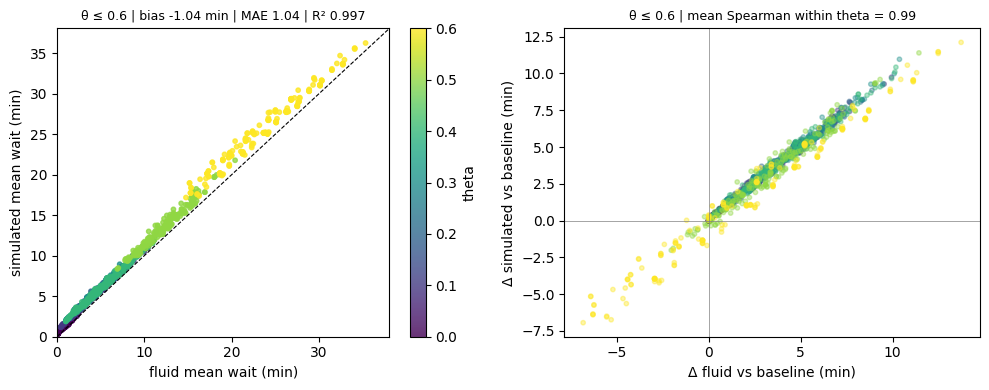

In [7]:
from scipy.stats import spearmanr
THETA_MAX = 0.6
d = df_pert[df_pert["theta"] <= THETA_MAX].copy()  
d["err"] = d["q_fluid"] - d["qtime_mean"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))

# 1) accuratezza
sc_ = a1.scatter(d["q_fluid"], d["qtime_mean"], c=d["theta"], cmap="viridis", s=10, alpha=0.8)
lim = [0, max(d["q_fluid"].max(), d["qtime_mean"].max()) * 1.05]
a1.plot(lim, lim, "k--", lw=0.8); a1.set_xlim(lim); a1.set_ylim(lim)
r2 = np.corrcoef(d["q_fluid"], d["qtime_mean"])[0, 1] ** 2
a1.set_xlabel("fluid mean wait (min)"); a1.set_ylabel("simulated mean wait (min)")
a1.set_title(f"θ ≤ {THETA_MAX} | bias {d['err'].mean():+.2f} min | MAE {d['err'].abs().mean():.2f} | R² {r2:.3f}", fontsize=9)
fig.colorbar(sc_, ax=a1, label="theta")

# 2) concordanza: delta rispetto alla baseline del proprio theta
base = d[d["is_baseline"]].set_index("theta")[["q_fluid", "qtime_mean"]]
d = d.join(base, on="theta", rsuffix="_b")
d["dF"], d["dS"] = d["q_fluid"] - d["q_fluid_b"], d["qtime_mean"] - d["qtime_mean_b"]
m = ~d["is_baseline"]
rho = np.mean([spearmanr(g["q_fluid"], g["qtime_mean"])[0] for _, g in d.groupby("theta") if len(g) > 3])
a2.scatter(d.loc[m, "dF"], d.loc[m, "dS"], c=d.loc[m, "theta"], cmap="viridis", s=10, alpha=0.4)
a2.axhline(0, color="gray", lw=0.5); a2.axvline(0, color="gray", lw=0.5)
a2.set_xlabel("Δ fluid vs baseline (min)"); a2.set_ylabel("Δ simulated vs baseline (min)")
a2.set_title(f"θ ≤ {THETA_MAX} | mean Spearman within theta = {rho:.2f}", fontsize=9)

fig.tight_layout(); plt.show()

##### using fluid approx

In [10]:
from app.services.perturbation import *
import app.services.simulation_batch as sb  
import app.services.local_search as ls
from app.services.fluid_approx import capacity_per_slot, fluid_wait

date=dt.datetime(2026, 6, 1)

out_path = os.path.join("data", f"new_perturbation_study_fluid_{date.date()}.xlsx")
os.makedirs(os.path.dirname(out_path), exist_ok=True)

In [11]:
schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
arrivals= samplers.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

2026-11-26 10:48:17,961 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


2026-11-26 10:48:18,343 | INFO | app.services.security_class | [SecurityPlanner] running


2026-11-26 10:48:18,447 | INFO | app.services.security_class | [SecuritySimulator] 1 total tasks, 4 workers


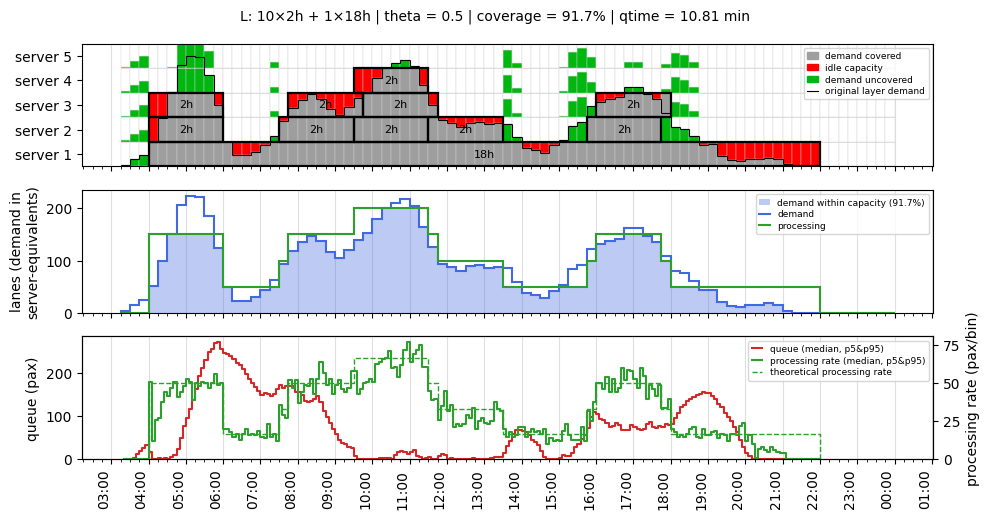

In [12]:
# first test before launching perturbation loop

lengths = [2]
theta = 0.5
K_total = 100
length_totals = {2: 25}

arrivals= samplers.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals=arrivals, server_registry=server_registry)
res = planner.run(inherit=True, lengths=lengths, theta=theta, K_total=K_total, length_totals=length_totals, first_server=("04:00", "22:00"))

classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)
sim_results = classe2.run(n_scenarios=1, n_workers=4, timebin=5, base_seed=base_seed)

plotutils.plot_allocation(res, df_timeline=sim_results.df_timeline, df_kpis=sim_results.df_kpis)

In [6]:
# loop solo con fluid, più L (un solo L ammesso per volta)

LS = [2, 3, 4]
K_TOTAL = 1000

theta_step = 0.1
first_server = ("04:00", "22:00")
max_moves = 15
n_reps = 499
step = 6
batch_id = 0

fs_txt = str(first_server)

T = planner.demand_grid.shape[1]
N_pax = float(planner.arrivals.sum())
arr_np = planner.arrivals.to_numpy()

out_path = os.path.join("data", f"new_perturbation_study_fluid_{date.date()}.xlsx")
df_prev = pd.read_excel(out_path) if os.path.exists(out_path) else pd.DataFrame()

if len(df_prev):
    if "batch" not in df_prev:
        df_prev["batch"] = 0
    if "first_server" not in df_prev:
        df_prev["first_server"] = "None"
    df_prev["first_server"] = df_prev["first_server"].astype(str)
rows = df_prev.to_dict("records")
done = ({(round(a, 6), int(b), c, str(l), str(lt), int(k))
         for a, b, c, l, lt, k in zip(df_prev["theta"], df_prev["batch"],
                                       df_prev["first_server"], df_prev["lengths"],
                                       df_prev["length_totals"], df_prev["K_total"])}
        if len(df_prev) else set())

rep = int(df_prev["rep"].max()) + 1 if len(df_prev) else 0

for L in LS:
    lengths = [L]
    K_total = K_TOTAL
    length_totals = {L: K_TOTAL}
    cfg = (str(lengths), str(length_totals), int(K_total))
    print(f"\n===== L={L} =====")

    for theta_i in np.arange(0.0, 0.8, theta_step):
        theta_i = round(float(theta_i), 6)
        if (theta_i, batch_id, fs_txt, *cfg) in done:
            print(f"L={L} theta={theta_i}, batch={batch_id}: already in {out_path}, skipped")
            continue
        res_a = planner.run(lengths=lengths, length_totals=length_totals, theta=theta_i, K_total=K_total,
                            first_server=first_server, inherit=True)

        bounds = res_a.first_server_window and (res_a.first_server_window[0],
                                                res_a.first_server_window[0] + res_a.first_server_window[1])

        base = schedule_to_blocks(planner, res_a)
        fixed_labels = {res_a.server_labels[0]} if first_server else set()
        n_blocks = sum(len(v) for v in base.values())
        n_movable = sum(len(v) for lab, v in base.items() if lab not in fixed_labels)
        if n_movable == 0:
            print(f"L={L} theta={theta_i}: no movable windows, skipped")
            continue

        rng = np.random.default_rng([42, L, int(round(theta_i * 1000)), batch_id])

        mine = [r for r in rows
                if np.isclose(r["theta"], theta_i)
                and str(r["first_server"]) == fs_txt
                and (str(r["lengths"]), str(r["length_totals"]), int(r["K_total"])) == cfg]
        seen = {r["blocks"] for r in mine} | {blocks_to_json(base)}
        offset = len(mine)

        # 1) schedule del lotto
        schedules = [(base, [])] if batch_id == 0 else []
        target = n_reps + (1 if batch_id == 0 else 0)
        for _ in range(20 * n_reps):
            if len(schedules) >= target:
                break
            k = int(rng.integers(1, max_moves + 1))
            blocks, moves = perturb_blocks(base, T, k, rng, step=step, fixed=fixed_labels, bounds=bounds)
            key = blocks_to_json(blocks)
            if key in seen:
                continue
            seen.add(key)
            schedules.append((blocks, moves))

        print(f"L={L} theta={theta_i}, batch={batch_id}: {len(schedules)} new schedules")
        if not schedules:
            continue

        # 2) coda fluida, righe
        for j, (blocks, moves) in enumerate(schedules):
            rep_theta = offset + j
            cap = capacity_per_slot(blocks, planner.rate_by_label, T)
            q_f = fluid_wait(arr_np, cap, planner.bin_minutes)

            rows.append(dict(
                date=date, lengths=str(lengths), length_totals=str(length_totals), K_total=K_total,
                theta=theta_i, first_server=fs_txt,
                batch=batch_id, n_blocks=n_blocks, rep=rep, rep_theta=rep_theta,
                is_baseline=(batch_id == 0 and j == 0), n_pax=N_pax,
                **coverage_from_blocks(planner, res_a, blocks),
                coverage=compute_coverage(arr_np, planner.rate_by_label, blocks),
                q_fluid=q_f,
                n_moves=len(moves), moves=json.dumps(moves), blocks=blocks_to_json(blocks)))
            rep += 1

        pd.DataFrame(rows).to_excel(out_path, index=False)
        print(f"L={L} theta={theta_i}, batch={batch_id}: saved")

df_pert_fluid = pd.DataFrame(rows)

2026-11-25 15:57:34,137 | INFO | app.services.security_class | [SecurityPlanner] running



===== L=2 =====
L=2 theta=0.0, batch=0: 500 new schedules


2026-11-25 15:57:34,425 | INFO | app.services.security_class | [SecurityPlanner] running


L=2 theta=0.0, batch=0: saved
L=2 theta=0.1, batch=0: 500 new schedules


2026-11-25 15:57:34,904 | INFO | app.services.security_class | [SecurityPlanner] running


L=2 theta=0.1, batch=0: saved
L=2 theta=0.2, batch=0: 500 new schedules


... (38 outputs left out)

2026-11-25 15:58:05,835 | INFO | app.services.security_class | [SecurityPlanner] running


L=4 theta=0.5, batch=0: saved
L=4 theta=0.6, batch=0: 500 new schedules


2026-11-25 15:58:08,679 | INFO | app.services.security_class | [SecurityPlanner] running


L=4 theta=0.6, batch=0: saved
L=4 theta=0.7, batch=0: 500 new schedules
L=4 theta=0.7, batch=0: saved


In [7]:
df_pert_fluid

,date,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,rep_theta,...,n_pax,covered_demand,idle_capacity,coverage_sum,objective,coverage,q_fluid,n_moves,moves,blocks
0,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,0,0,...,6908.0,137.310016,70.689984,0.993848,137.310016,0.993848,0.103412,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,1,1,...,6908.0,133.770578,74.229422,0.968229,133.770578,0.968229,1.451349,4,"[[""4"", 1, 6], [""4"", 0, 1], [""3"", 2, 4], [""3"", ...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,2,2,...,6908.0,134.586429,73.413571,0.974135,134.586429,0.974135,0.736040,14,"[[""4"", 1, 5], [""4"", 0, 5], [""4"", 2, -4], [""2"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,3,3,...,6908.0,137.310016,70.689984,0.993848,137.310016,0.993848,0.103412,2,"[[""3"", 3, -5], [""3"", 2, 1]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,4,4,...,6908.0,136.683311,71.316689,0.989312,136.683311,0.989312,0.214363,3,"[[""3"", 0, 4], [""3"", 1, -1], [""3"", 2, -1]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11995,495,...,6908.0,91.965711,28.034289,0.665646,7.965711,0.665646,206.541506,3,"[[""2"", 0, 6], [""3"", 0, 5], [""2"", 1, 1]]","{""1"": [[3, 72]], ""2"": [[24, 16], [47, 16]], ""3..."
11996,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11996,496,...,6908.0,96.183111,23.816889,0.696172,12.183111,0.696172,175.273549,3,"[[""2"", 1, 3], [""3"", 0, -4], [""2"", 0, -5]]","{""1"": [[3, 72]], ""2"": [[13, 16], [49, 16]], ""3..."
11997,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11997,497,...,6908.0,95.985134,24.014866,0.694739,11.985134,0.694739,178.747889,3,"[[""2"", 1, -6], [""3"", 0, 3], [""2"", 0, -1]]","{""1"": [[3, 72]], ""2"": [[17, 16], [40, 16]], ""3..."
11998,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11998,498,...,6908.0,97.882677,22.117323,0.708473,13.882677,0.708473,178.747490,3,"[[""2"", 1, -2], [""2"", 0, -4], [""3"", 0, 2]]","{""1"": [[3, 72]], ""2"": [[14, 16], [44, 16]], ""3..."


C:\Users\zanch\AppData\Local\Temp\ipykernel_38904\1393353665.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  fig.legend(loc="upper right")


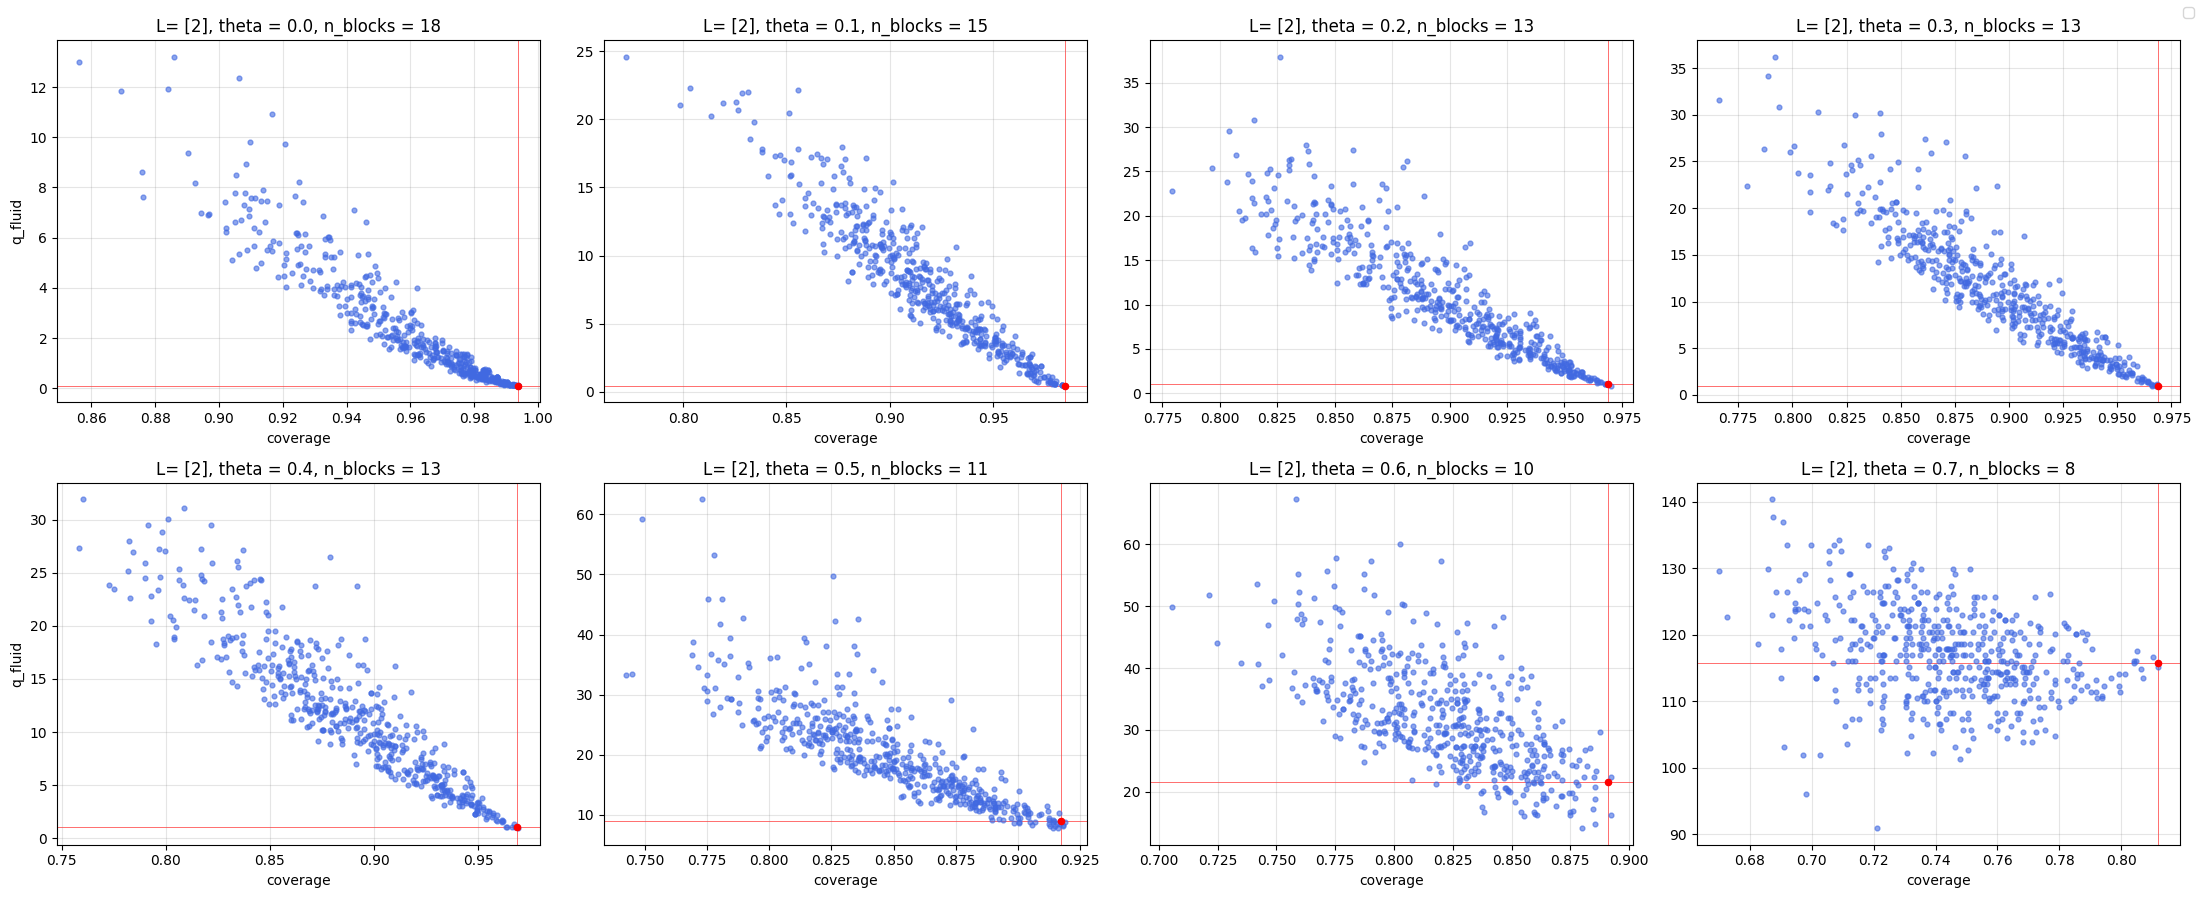

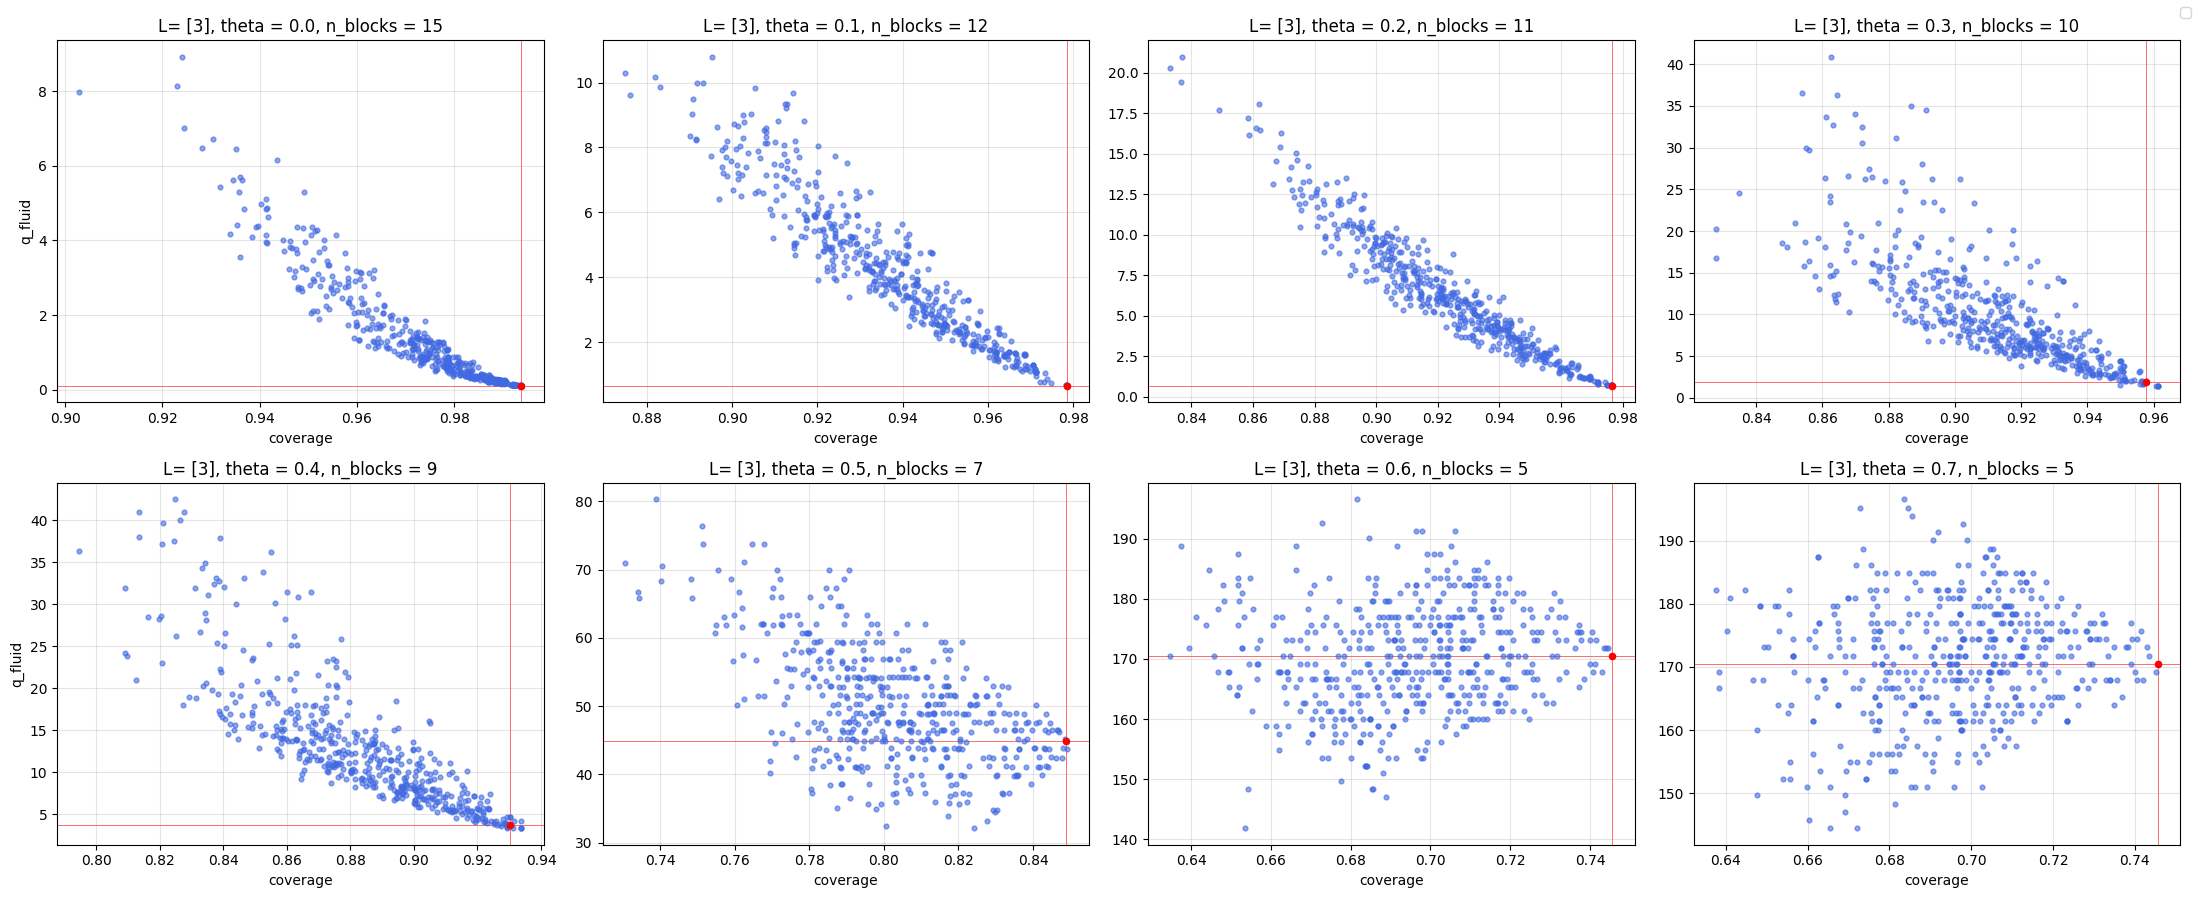

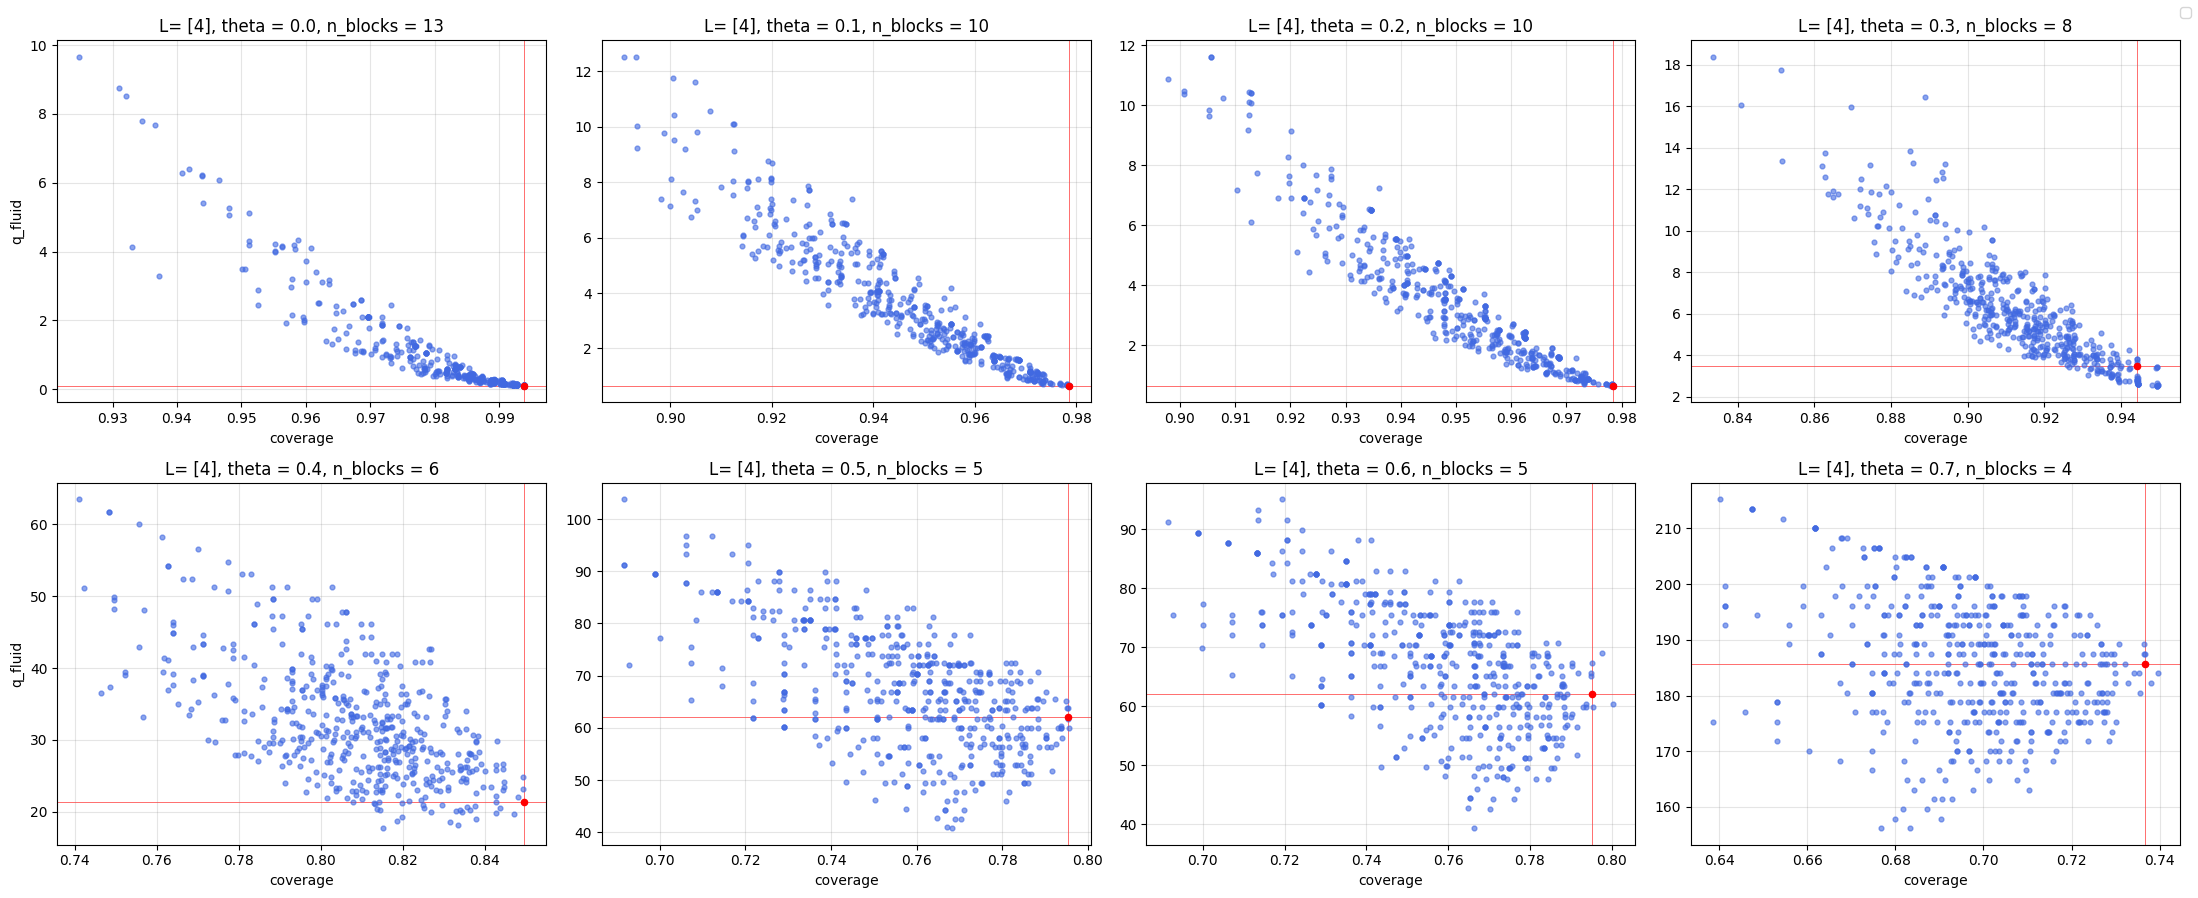

In [8]:
import math
from matplotlib.lines import Line2D

x, y = "coverage", "q_fluid"
max_cols = 4
lengthts = sorted(df_pert_fluid["lengths"].unique())
theta_in = sorted(df_pert_fluid["theta"].unique())
theta_in= [x for x in theta_in if x <= 0.7]

n_rows = math.ceil(len(theta_in) / max_cols)
n_cols = min(len(theta_in), max_cols)

for length in lengthts:
    df_pert_fluid_filtered = df_pert_fluid[df_pert_fluid["lengths"] == length]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows), squeeze=False)
    flat = axes.ravel()
    for ax, a in zip(flat, theta_in):
        d = df_pert_fluid_filtered[df_pert_fluid_filtered["theta"] == a]
        ax.scatter(d[x], d[y], s=12, marker="o", color="royalblue", alpha=0.6, zorder=2)

        if d["is_baseline"].any():
            b = d[d["is_baseline"]].iloc[0]
            ax.scatter(b[x], b[y], s=20, marker="o",
                    color="red", linewidths=1, zorder=3) 
            ax.axhline(b[y], color="red", linewidth=0.4, zorder=0)
            ax.axvline(b[x], color="red", linewidth=0.4, zorder=0)
        ax.set_title(f"L= {length}, theta = {a}, n_blocks = {d['n_blocks'].iloc[0]}")
        ax.set_xlabel(x)
        ax.grid(color="gray", alpha=0.2)

    for ax in flat[len(theta_in):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel(y)
    fig.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib import cm, colors
from matplotlib.patches import Patch

x, y = "n_blocks", "q_fluid"
u_col, u_tol = "n_unserved", 0.0
theta_max = 0.6

d = df_pert_fluid[df_pert_fluid["theta"] <= theta_max].copy()

for l in sorted(df_pert_fluid["lengths"].unique()):
    d_l = d[d["lengths"] == l]

    pert = d_l[~d_l["is_baseline"]]
    base = d_l[d_l["is_baseline"]].sort_values([x, "theta"])

    fig, ax = plt.subplots(figsize=(5, 4))
    groups = [
        (n, g)
        for n, g in pert.groupby(x)
        if g[y].notna().any()
    ]

    positions = [n for n, g in groups]
    values = [g[y].dropna().values for n, g in groups]

    norm = colors.Normalize(vmin=d["theta"].min(), vmax=d["theta"].max())
    cmap = plt.get_cmap("viridis")

    bp = ax.boxplot(
        values,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color="black", linewidth=1.2),
        whiskerprops=dict(linewidth=0.8),
        capprops=dict(linewidth=0.8),
        boxprops=dict(linewidth=0.8),
        manage_ticks=False
    )

    for box, (_, g) in zip(bp["boxes"], groups):
        box.set_facecolor(cmap(norm(g["theta"].mean())))
        box.set_alpha(0.7)

    ax.plot(base[x], base[y], "-", color="red", linewidth=0.8, zorder=3)
    ax.scatter(base[x], base[y],s=40, color="red", edgecolor="black", zorder=4)

    for _, r in base.iterrows():
        ax.annotate(
            f"theta={r['theta']:g}",
            (r[x]+0.5, r[y]),
            textcoords="offset points",
            xytext=(6, 6),
            fontsize=8,
            color="red"
        )

    ax.set_xlabel("n_blocks")
    ax.set_ylabel(y)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(color="gray", alpha=0.2)

    handles = [
        Patch(facecolor="gray", alpha=0.7, label="Perturbed schedules"),
        Line2D(
            [], [], marker="o", color="red",
            markeredgecolor="black", linestyle="-",
            label="Baseline (label = theta)"
        )
    ]
    ax.set_yscale("log")
    ax.set_title(f"L={l} | θ ≤ {theta_max}")
    ax.legend(handles=handles, loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()

In [15]:
df_pert_fluid

,date,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,rep_theta,...,n_pax,covered_demand,idle_capacity,coverage_sum,objective,coverage,q_fluid,n_moves,moves,blocks
0,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,0,0,...,6908.0,137.310016,70.689984,0.993848,137.310016,0.993848,0.103412,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,1,1,...,6908.0,133.770578,74.229422,0.968229,133.770578,0.968229,1.451349,4,"[[""4"", 1, 6], [""4"", 0, 1], [""3"", 2, 4], [""3"", ...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,2,2,...,6908.0,134.586429,73.413571,0.974135,134.586429,0.974135,0.736040,14,"[[""4"", 1, 5], [""4"", 0, 5], [""4"", 2, -4], [""2"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,3,3,...,6908.0,137.310016,70.689984,0.993848,137.310016,0.993848,0.103412,2,"[[""3"", 3, -5], [""3"", 2, 1]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-06-01,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,18,4,4,...,6908.0,136.683311,71.316689,0.989312,136.683311,0.989312,0.214363,3,"[[""3"", 0, 4], [""3"", 1, -1], [""3"", 2, -1]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11995,495,...,6908.0,91.965711,28.034289,0.665646,7.965711,0.665646,206.541506,3,"[[""2"", 0, 6], [""3"", 0, 5], [""2"", 1, 1]]","{""1"": [[3, 72]], ""2"": [[24, 16], [47, 16]], ""3..."
11996,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11996,496,...,6908.0,96.183111,23.816889,0.696172,12.183111,0.696172,175.273549,3,"[[""2"", 1, 3], [""3"", 0, -4], [""2"", 0, -5]]","{""1"": [[3, 72]], ""2"": [[13, 16], [49, 16]], ""3..."
11997,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11997,497,...,6908.0,95.985134,24.014866,0.694739,11.985134,0.694739,178.747889,3,"[[""2"", 1, -6], [""3"", 0, 3], [""2"", 0, -1]]","{""1"": [[3, 72]], ""2"": [[17, 16], [40, 16]], ""3..."
11998,2026-06-01,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,4,11998,498,...,6908.0,97.882677,22.117323,0.708473,13.882677,0.708473,178.747490,3,"[[""2"", 1, -2], [""2"", 0, -4], [""3"", 0, 2]]","{""1"": [[3, 72]], ""2"": [[14, 16], [44, 16]], ""3..."


q_fluid: 21.38 → 17.69


2026-11-25 16:14:25,892 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers
2026-11-25 16:14:36,532 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers


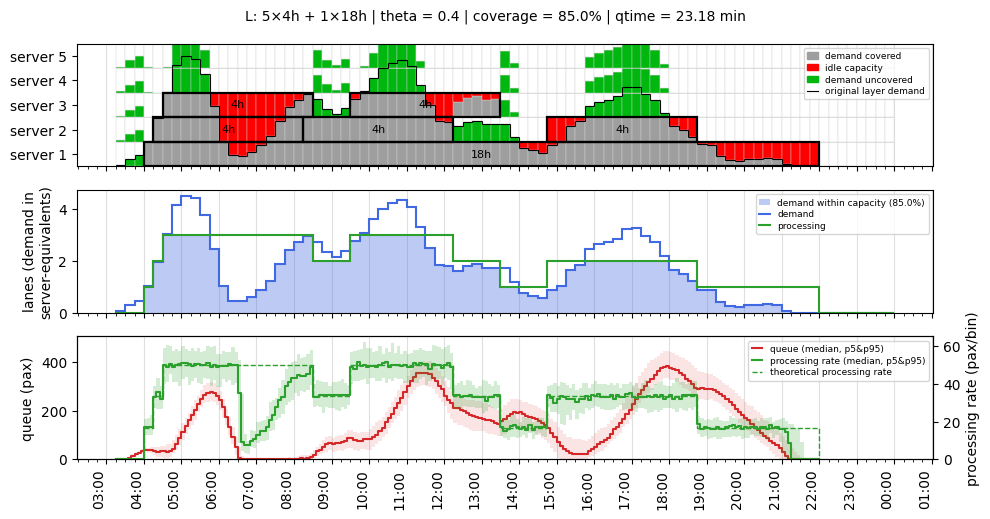

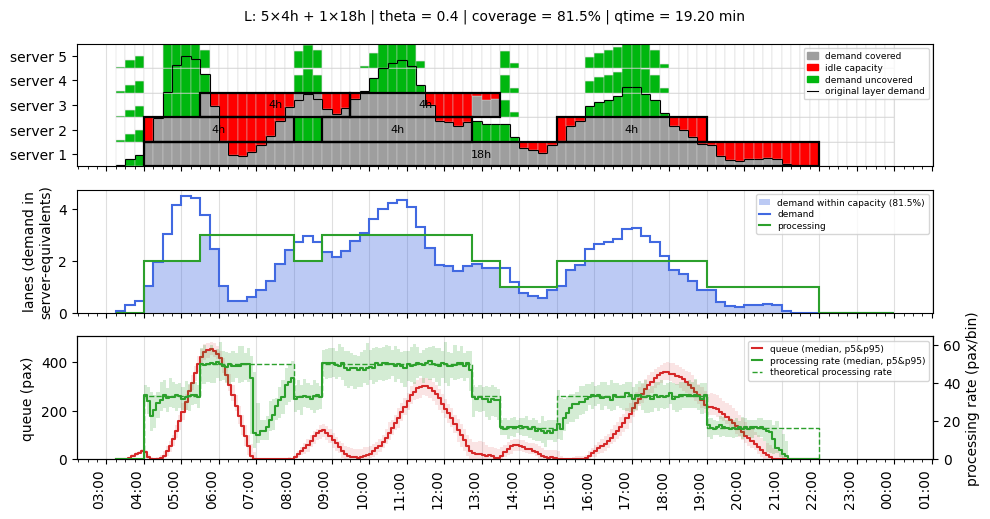

In [16]:
from app.services.coverage_dp import effective_grid
import json, numpy as np, pandas as pd

def pick(df, L, theta, rep_theta):
    m = (df["lengths"] == f"[{L}]") & np.isclose(df["theta"], theta) & (df["rep_theta"] == rep_theta)
    return df[m].iloc[0]

def run_point(row, flight_demand, server_registry, planner, n_scenarios=50, n_workers=6, base_seed=42):
    D = np.asarray(planner.demand_grid, float); T = D.shape[1]
    time_values = pd.DatetimeIndex(planner.arrivals.index)[:T]
    assert len(time_values) == T, "arrivals index and demand_grid have different lengths"
    labels = list(utils.sort_labels_by_priority(server_registry))
    blocks = {lab: [(int(s), int(l)) for s, l in bl] for lab, bl in json.loads(row["blocks"]).items()}

    step = pd.Timedelta(minutes=planner.bin_minutes); t0 = pd.Timestamp(time_values[0])
    sched = {lab: [((t0 + s * step).to_pydatetime(), (t0 + (s + l) * step).to_pydatetime()) for s, l in bl]
             for lab, bl in blocks.items() if len(bl)}
    sim = security_class.SecuritySimulator(flight_demand=flight_demand,
                                           intervals=utils.server_schedule_to_intervals(sched),
                                           server_registry=server_registry)
    res = sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=5, base_seed=base_seed)

    # copertura per riga (nell'ordine delle righe della griglia) -> domanda ereditata
    covs = []
    for lab in labels[:D.shape[0]]:
        c = np.zeros(T, dtype=bool)
        for s, l in blocks.get(lab, []): c[s:s + l] = True
        covs.append(c)
    D_eff = effective_grid(D, covs)
    proc = np.sum(covs, axis=0).astype(float)
    return dict(res=res, blocks=blocks, labels=labels, D=D, D_eff=D_eff, time_values=time_values, proc=proc)

def plot_point(p, theta, queue_max, bin_minutes=15):
    plotutils.plot_blocks(D=p["D_eff"], D_ref=p["D"], blocks=p["blocks"], labels=p["labels"],
                          time_values=p["time_values"], theta=theta, bin_minutes=bin_minutes,
                          demand_curve=p["D"].sum(axis=0), processing_curve=p["proc"],
                          df_timeline=p["res"].df_timeline, df_kpis=p["res"].df_kpis, queue_max=queue_max)

# --- i due punti
L=4
theta = 0.4
r_a = pick(df_pert_fluid, L=L, theta=theta, rep_theta=0)
r_b = pick(df_pert_fluid, L=L, theta=theta, rep_theta=483)
print("q_fluid:", round(r_a.q_fluid, 2), "→", round(r_b.q_fluid, 2))

pa = run_point(r_a, flight_demand, server_registry, planner, base_seed=base_seed)
pb = run_point(r_b, flight_demand, server_registry, planner, base_seed=base_seed)

qmax = int(max(p["res"].df_timeline["queue_length_p95"].max() for p in (pa, pb)) * 1.05)
plot_point(pa, theta=theta, queue_max=qmax); plot_point(pb, theta=theta, queue_max=qmax)

##### multiple days

In [16]:
def make_planner(d, schedule_std, arrival_model, server_registry, pax_model="data/pax_model.joblib"):
    sched = schedule_std[schedule_std["date"] == d].copy()
    pred = predictive.predict_pax(df=sched, path=pax_model)
    fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
    return security_class.SecurityPlanner(samplers.expected_arrivals(fd), server_registry)

def run_perturbation(dates, schedule_std, arrival_model, server_registry, LS, thetas, K_total=1000,
                     first_server=("04:00", "22:00"), max_moves=15, n_reps=99, step=6, batch_id=0,
                     inherits=(False, True), out_path="data/new_perturbation_multi_inh.pkl"):
    fs_txt = str(first_server)
    df_prev = pd.read_pickle(out_path) if os.path.exists(out_path) else pd.DataFrame()
    rows = df_prev.to_dict("records")
    key_of = lambda d, th, L, inh: (pd.Timestamp(d).normalize(), round(float(th), 6), int(batch_id), fs_txt,
                                    str([L]), str({L: K_total}), int(K_total), bool(inh))
    done = {(pd.Timestamp(r["date"]).normalize(), round(float(r["theta"]), 6), int(r["batch"]), str(r["first_server"]),
             str(r["lengths"]), str(r["length_totals"]), int(r["K_total"]), bool(r["inherit"])) for r in rows}
    rep = int(df_prev["rep"].max()) + 1 if len(df_prev) else 0

    for n, d in enumerate(dates):
        day = pd.Timestamp(d).normalize()
        todo = [(L, round(float(th), 6), inh) for L in LS for th in thetas for inh in inherits
                if key_of(day, th, L, inh) not in done]
        if not todo:
            continue
        try:
            planner = make_planner(d, schedule_std, arrival_model, server_registry)
        except Exception as e:
            print(f"[{n+1}/{len(dates)}] {day.date()} SKIP: {type(e).__name__}: {e}"); continue
        T = planner.demand_grid.shape[1]; N_pax = float(planner.arrivals.sum()); arr_np = planner.arrivals.to_numpy()

        for L, theta_i, inh in todo:
            lengths, length_totals = [L], {L: K_total}
            cfg = (str(lengths), str(length_totals), int(K_total))
            res_a = planner.run(lengths=lengths, length_totals=length_totals, theta=theta_i, K_total=K_total,
                                first_server=first_server, inherit=inh)
            bounds = res_a.first_server_window and (res_a.first_server_window[0],
                                                    res_a.first_server_window[0] + res_a.first_server_window[1])
            base = schedule_to_blocks(planner, res_a)
            fixed_labels = {res_a.server_labels[0]} if first_server else set()
            n_blocks = sum(len(v) for v in base.values())
            if sum(len(v) for lab, v in base.items() if lab not in fixed_labels) == 0:
                continue
            # stesso seed per inherit False/True: stesse estrazioni casuali (k, direzioni) applicate alle due baseline
            rng = np.random.default_rng([42, L, int(round(theta_i * 1000)), batch_id, int(day.strftime("%Y%m%d"))])

            mine = [r for r in rows if pd.Timestamp(r["date"]).normalize() == day and np.isclose(r["theta"], theta_i)
                    and bool(r["inherit"]) == bool(inh) and str(r["first_server"]) == fs_txt
                    and (str(r["lengths"]), str(r["length_totals"]), int(r["K_total"])) == cfg]
            seen = {r["blocks"] for r in mine} | {blocks_to_json(base)}
            offset = len(mine)

            schedules = [(base, [])] if batch_id == 0 else []
            target = n_reps + (1 if batch_id == 0 else 0)
            for _ in range(20 * n_reps):
                if len(schedules) >= target: break
                k = int(rng.integers(1, max_moves + 1))
                blocks, moves = perturb_blocks(base, T, k, rng, step=step, fixed=fixed_labels, bounds=bounds)
                kk = blocks_to_json(blocks)
                if kk in seen: continue
                seen.add(kk); schedules.append((blocks, moves))

            for j, (blocks, moves) in enumerate(schedules):
                cap = capacity_per_slot(blocks, planner.rate_by_label, T)
                rows.append(dict(
                    date=day, inherit=bool(inh), lengths=str(lengths), length_totals=str(length_totals), K_total=K_total,
                    theta=theta_i, first_server=fs_txt, batch=batch_id, n_blocks=n_blocks, rep=rep,
                    rep_theta=offset + j, is_baseline=(batch_id == 0 and j == 0), n_pax=N_pax,
                    **coverage_from_blocks(planner, res_a, blocks),
                    coverage=compute_coverage(arr_np, planner.rate_by_label, blocks),
                    q_fluid=fluid_wait(arr_np, cap, planner.bin_minutes),
                    n_moves=len(moves), moves=json.dumps(moves), blocks=blocks_to_json(blocks)))
                rep += 1
            done.add(key_of(day, theta_i, L, inh))

        pd.DataFrame(rows).to_pickle(out_path)
        print(f"[{n+1}/{len(dates)}] {day.date()} saved ({len(rows)} rows)")
    return pd.DataFrame(rows)

In [ ]:
schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

dates = sorted(schedule_std["date"].unique())[:93]

In [14]:
df_pert_fluid = run_perturbation(dates, schedule_std, arrival_model, server_registry, LS=[2, 3, 4],
                                 thetas=np.arange(0.0, 0.8, 0.1), n_reps=199,
                                 out_path="data/new_perturbation_multi.pkl")

2026-11-26 11:03:10,053 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 11:03:10,062 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,157 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,255 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,330 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,401 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,477 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,551 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,626 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,702 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:10,787 | 

[1/93] 2026-03-29 saved (9508 rows)


2026-11-26 11:03:16,165 | WARNING | app.services.preprocessing | More than 10% of flights (13/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 11:03:16,175 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,330 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,458 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,562 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,636 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,731 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,822 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:16,913 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:17,005 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:17,107 |

[2/93] 2026-03-30 saved (18982 rows)


2026-11-26 11:03:23,073 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,257 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,353 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,450 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,548 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,644 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,739 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,837 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:23,936 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:24,036 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:24,142 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 11:03:24,2

[3/93] 2026-03-31 saved (27642 rows)


... (174 outputs left out)

2026-11-26 12:12:51,199 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:52,579 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:53,996 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:55,312 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:56,683 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:58,047 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:12:59,412 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:13:00,874 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:13:02,346 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:13:03,802 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:13:05,174 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:13:06,5

[92/93] 2026-06-28 saved (852360 rows)


2026-11-26 12:14:01,748 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:03,140 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:05,150 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:06,889 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:08,361 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:09,805 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:11,178 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:12,627 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:14,038 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:15,467 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:16,944 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:14:18,3

[93/93] 2026-06-29 saved (861898 rows)


In [ ]:
df_pert_fluid= pd.read_pickle("data/new_perturbation_multi.pkl")

,date,inherit,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,...,n_pax,covered_demand,idle_capacity,coverage_sum,objective,coverage,q_fluid,n_moves,moves,blocks
0,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,0,...,6707.0,133.705491,66.294509,0.996761,133.705491,0.996761,0.043288,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,1,...,6707.0,126.621731,73.378269,0.943952,126.621731,0.943952,3.135614,12,"[[""3"", 2, -2], [""4"", 1, 5], [""3"", 1, -1], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,2,...,6707.0,127.962613,72.037387,0.953948,127.962613,0.953948,2.194102,5,"[[""3"", 3, 1], [""3"", 1, -3], [""2"", 6, 5], [""2"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,3,...,6707.0,118.541394,81.458606,0.883714,118.541394,0.883714,10.830848,11,"[[""2"", 5, -2], [""3"", 5, 5], [""3"", 3, 3], [""4"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,4,...,6707.0,130.902349,69.097651,0.975864,130.902349,0.975864,1.067567,2,"[[""3"", 3, 3], [""4"", 2, -5]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
861893,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861893,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,282.430125,1,"[[""2"", 0, -1]]","{""1"": [[3, 72]], ""2"": [[18, 16], [48, 16]]}"
861894,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861894,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,289.495345,1,"[[""2"", 0, 3]]","{""1"": [[3, 72]], ""2"": [[22, 16], [48, 16]]}"
861895,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861895,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,285.962520,1,"[[""2"", 0, 1]]","{""1"": [[3, 72]], ""2"": [[20, 16], [48, 16]]}"
861896,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861896,...,6794.0,86.874096,17.125904,0.639344,14.074096,0.639344,287.729068,1,"[[""2"", 1, 2]]","{""1"": [[3, 72]], ""2"": [[19, 16], [50, 16]]}"


In [ ]:
import math
from matplotlib.lines import Line2D

day = pd.Timestamp("2026-06-01")
x, y = "coverage", "q_fluid"
max_cols = 4
COL = {True: dict(cloud="#f4a6a6", base="red", name="inherited"),
       False: dict(cloud="#a9c4f5", base="tab:green", name="plain")}

dfp = df_pert_fluid[pd.to_datetime(df_pert_fluid["date"]).dt.normalize() == day]
theta_in = [t for t in sorted(dfp["theta"].unique()) if t <= 0.7]
n_rows = math.ceil(len(theta_in) / max_cols); n_cols = min(len(theta_in), max_cols)

for length in sorted(dfp["lengths"].unique()):
    dl = dfp[dfp["lengths"] == length]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.5 * n_rows), squeeze=False)
    flat = axes.ravel()
    for ax, a in zip(flat, theta_in):
        d = dl[dl["theta"] == a]
        for inh in (False, True):                                   # prima la piana, poi l'ereditata sopra
            di = d[d["inherit"] == inh]
            if di.empty: continue
            ax.scatter(di[x], di[y], s=12, marker="o", color=COL[inh]["cloud"], alpha=0.8, zorder=2)
        for inh in (False, True):
            di = d[(d["inherit"] == inh) & d["is_baseline"]]
            if di.empty: continue
            b = di.iloc[0]
            ax.scatter(b[x], b[y], s=40, marker="o", color=COL[inh]["base"], edgecolor="black", linewidths=0.6, zorder=4)
            ax.axhline(b[y], color=COL[inh]["base"], linewidth=0.5, zorder=1)
            ax.axvline(b[x], color=COL[inh]["base"], linewidth=0.5, zorder=1)
        nb = d["n_blocks"].iloc[0] if len(d) else "?"
        ax.set_title(f"L = {length}, θ = {a}, n_blocks = {nb}", fontsize=10)
        ax.set_xlabel(x); ax.grid(color="gray", alpha=0.2)
    for ax in flat[len(theta_in):]: ax.axis("off")
    for ax in axes[:, 0]: ax.set_ylabel(y)
    handles = [Line2D([], [], marker="o", ls="", color=COL[i]["cloud"], label=f"perturbations from {COL[i]['name']} baseline") for i in (False, True)] + \
              [Line2D([], [], marker="o", ls="", color=COL[i]["base"], mec="black", ms=7, label=f"baseline {COL[i]['name']}") for i in (False, True)]
    fig.legend(handles=handles, loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()

In [69]:
df_pert_fluid

,date,inherit,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,...,n_pax,covered_demand,idle_capacity,coverage_sum,objective,coverage,q_fluid,n_moves,moves,blocks
0,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,0,...,6707.0,133.705491,66.294509,0.996761,133.705491,0.996761,0.043288,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,1,...,6707.0,126.621731,73.378269,0.943952,126.621731,0.943952,3.135614,12,"[[""3"", 2, -2], [""4"", 1, 5], [""3"", 1, -1], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,2,...,6707.0,127.962613,72.037387,0.953948,127.962613,0.953948,2.194102,5,"[[""3"", 3, 1], [""3"", 1, -3], [""2"", 6, 5], [""2"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,3,...,6707.0,118.541394,81.458606,0.883714,118.541394,0.883714,10.830848,11,"[[""2"", 5, -2], [""3"", 5, 5], [""3"", 3, 3], [""4"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,4,...,6707.0,130.902349,69.097651,0.975864,130.902349,0.975864,1.067567,2,"[[""3"", 3, 3], [""4"", 2, -5]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
861893,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861893,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,282.430125,1,"[[""2"", 0, -1]]","{""1"": [[3, 72]], ""2"": [[18, 16], [48, 16]]}"
861894,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861894,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,289.495345,1,"[[""2"", 0, 3]]","{""1"": [[3, 72]], ""2"": [[22, 16], [48, 16]]}"
861895,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861895,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,285.962520,1,"[[""2"", 0, 1]]","{""1"": [[3, 72]], ""2"": [[20, 16], [48, 16]]}"
861896,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861896,...,6794.0,86.874096,17.125904,0.639344,14.074096,0.639344,287.729068,1,"[[""2"", 1, 2]]","{""1"": [[3, 72]], ""2"": [[19, 16], [50, 16]]}"


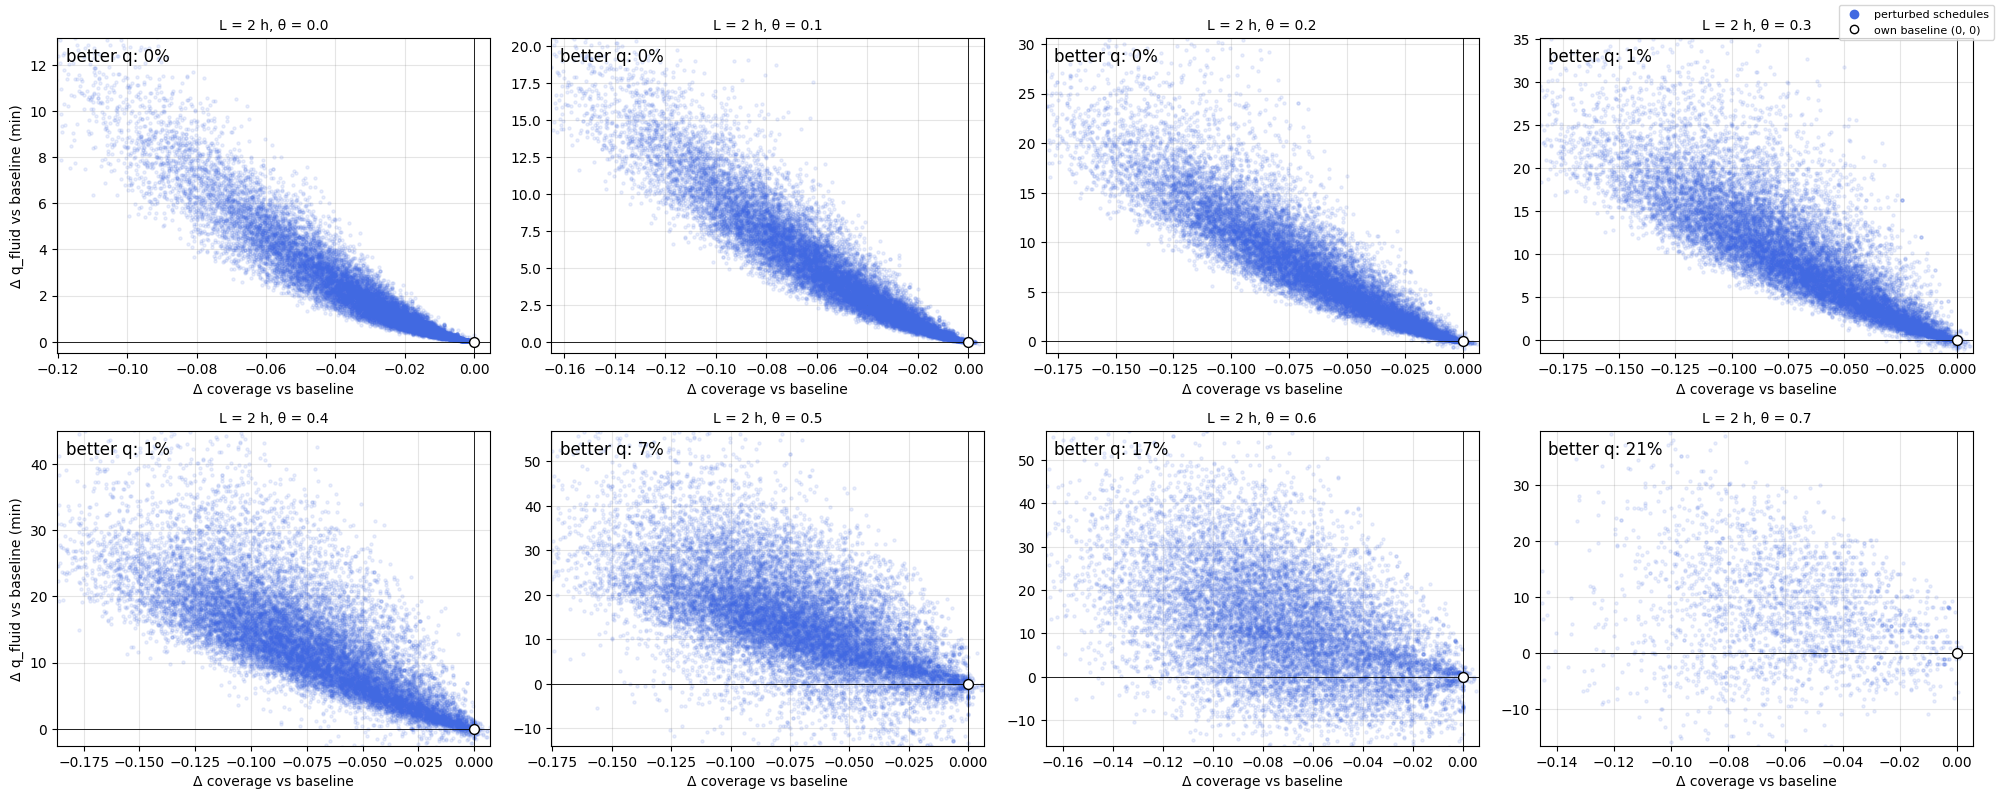

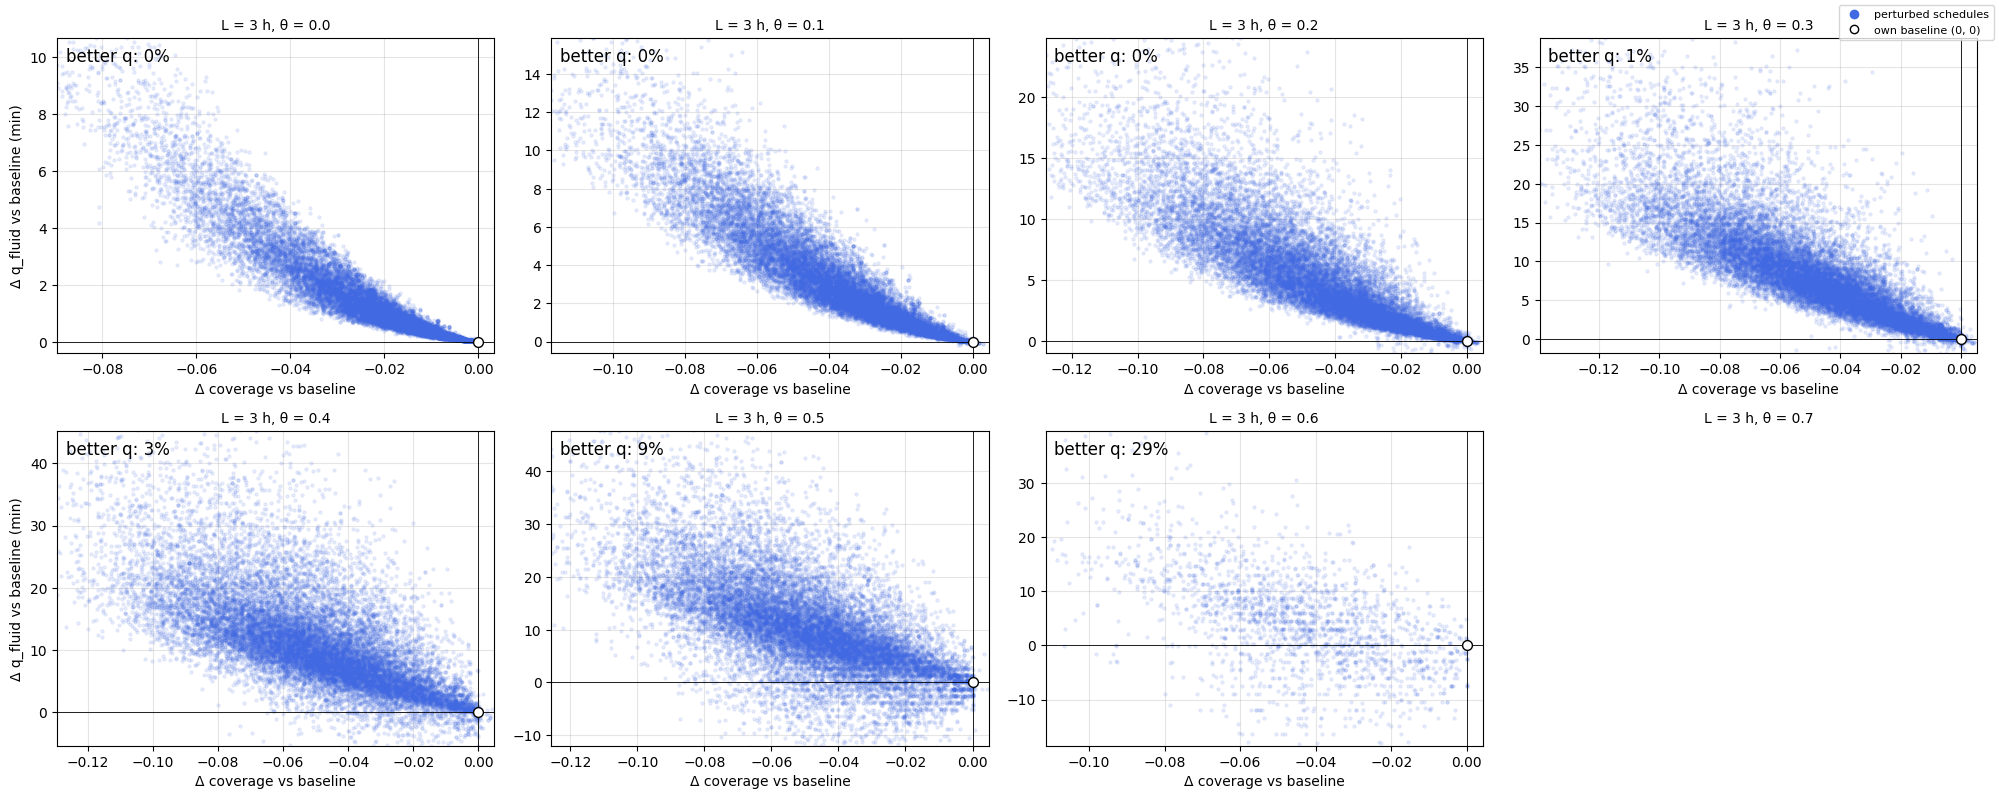

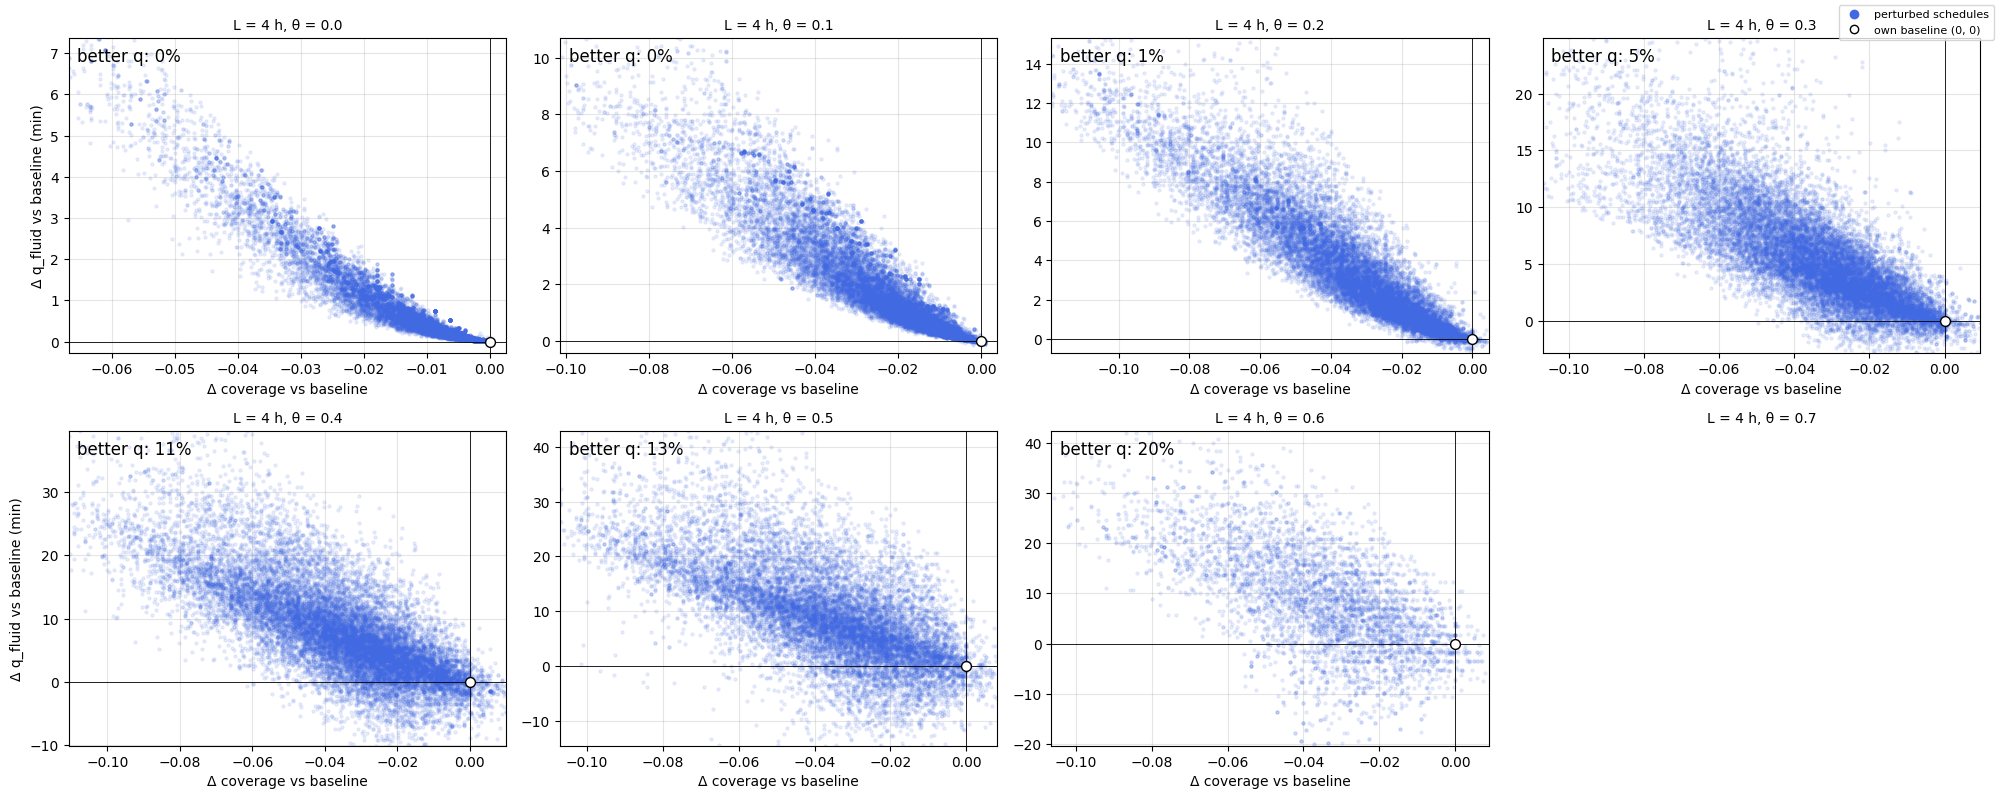

In [146]:
import math
from matplotlib.lines import Line2D

d = df_pert_fluid.copy() 
d= d[d['inherit'] == True].copy()
d["date"] = pd.to_datetime(d["date"]).dt.normalize()
key = ["date", "lengths", "theta", "inherit"]
base = d[d["is_baseline"]][key + ["coverage", "q_fluid"]].rename(columns={"coverage": "cov0", "q_fluid": "q0"})
d = d.merge(base, on=key)
d = d[~d["is_baseline"]].copy()
d["dcov"], d["dq"] = d["coverage"] - d["cov0"], d["q_fluid"] - d["q0"]

Q_MAX = 60
d = d[d["q0"] < Q_MAX]

theta_in = [t for t in sorted(d["theta"].unique()) if t <= 0.7]
max_cols = 4; n_rows = math.ceil(len(theta_in) / max_cols); n_cols = min(len(theta_in), max_cols)

for length in sorted(d["lengths"].unique()):
    dl = d[d["lengths"] == length]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False); flat = axes.ravel()
    for ax, a in zip(flat, theta_in):
        g = dl[dl["theta"] == a]
        ax.set_title(f"L = {length.strip('[]')} h, θ = {a}", fontsize=10)
        if g.empty:                                   # nessuna perturbazione: pannello vuoto
            ax.axis("off"); continue
        ax.scatter(g["dcov"], g["dq"], s=5, alpha=0.1, color="royalblue", rasterized=True, zorder=2)
        pooled = (g["dq"] < -0.1).mean()
        ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
        ax.scatter([0], [0], s=50, color="white", edgecolor="black", zorder=5)
        (xl, xh), (yl, yh) = g["dcov"].quantile([0.005, 0.995]), g["dq"].quantile([0.005, 0.995])
        xl, xh, yl, yh = min(xl, 0), max(xh, 0), min(yl, 0), max(yh, 0)      # includo sempre lo zero
        mx, my = 0.04 * (xh - xl), 0.04 * (yh - yl)                          # piccolo margine così il punto (0, 0) non è sul bordo
        ax.set_xlim(xl - mx, xh + mx); ax.set_ylim(yl - my, yh + my)
        ax.text(0.02, 0.97, f"better q: {pooled:.0%}", transform=ax.transAxes, va="top", fontsize=12)
        ax.set_xlabel("Δ coverage vs baseline"); ax.grid(color="gray", alpha=0.2)
    for ax in flat[len(theta_in):]: ax.axis("off")
    for ax in axes[:, 0]:
        if ax.axison: ax.set_ylabel("Δ q_fluid vs baseline (min)")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color="royalblue", label="perturbed schedules"),
                        Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="own baseline (0, 0)")],
               loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()

In [159]:
def baseline_best_table(df, inherit=True, tol=1e-9, caps=(30, 60)):
    d = df[df["inherit"] == inherit].copy() if "inherit" in df else df.copy()
    d["date"] = pd.to_datetime(d["date"]).dt.normalize()
    d["L"] = d["lengths"].str.strip("[]").astype(int)
    key = ["L", "theta", "date"]

    q0 = d[d["is_baseline"]].groupby(key)["q_fluid"].first().rename("q0")
    qmin = d.groupby(key)["q_fluid"].min().rename("qmin")
    per = pd.concat([q0, qmin], axis=1).dropna().reset_index()
    per["best"] = per["q0"] <= per["qmin"] + tol
    per["gap"] = per["q0"] - per["qmin"]

    def summ(g):
        out = {"cases": len(g), "% baseline best": 100 * g["best"].mean(), "median gap (min)": g["gap"].median()}
        for c in caps:
            s = g[g["q0"] < c]
            out[f"cases q<{c}"] = len(s)
            out[f"% best q<{c}"] = 100 * s["best"].mean() if len(s) else np.nan
            out[f"median gap q<{c}"] = s["gap"].median() if len(s) else np.nan          # <-- la colonna che mancava
        return pd.Series(out)

    by_L = per.groupby(["L", "theta"]).apply(summ, include_groups=False)
    pooled = per.assign(L="all").groupby(["L", "theta"]).apply(summ, include_groups=False)
    out = pd.concat([by_L, pooled]).round(1)
    for c in ["cases"] + [f"cases q<{c}" for c in caps]:
        out[c] = out[c].astype(int)
    return out

tab = baseline_best_table(df_pert_fluid, inherit=True, tol=0.5)

def slide_table(df, tol=0.1, cap=30, thetas=(0.1, 0.2, 0.3, 0.4, 0.5)):
    t = baseline_best_table(df, inherit=True, tol=tol, caps=(cap,)).reset_index()
    t = t[t["theta"].isin(thetas)]
    t["L"] = t["L"].map(lambda x: "all" if x == "all" else f"{x} h")
    pct = t.pivot(index="theta", columns="L", values=f"% best q<{cap}")[["2 h", "3 h", "4 h", "all"]]
    gap = t.pivot(index="theta", columns="L", values=f"median gap q<{cap}")[["2 h", "3 h", "4 h", "all"]]
    out = pct.round(0).astype("Int64").astype(str) + "%  (" + gap.round(1).astype(str) + " min)"
    out.index.name = "θ"
    return out

print(slide_table(df_pert_fluid, tol=0.5, cap=60).to_string())

L                2 h              3 h              4 h              all
θ                                                                      
0.1  100%  (0.0 min)  100%  (0.0 min)  100%  (0.0 min)  100%  (0.0 min)
0.2   98%  (0.0 min)   95%  (0.0 min)   98%  (0.0 min)   97%  (0.0 min)
0.3   80%  (0.1 min)   82%  (0.0 min)   52%  (0.5 min)   71%  (0.1 min)
0.4   74%  (0.1 min)   46%  (0.7 min)   13%  (2.6 min)   44%  (0.8 min)
0.5   23%  (3.1 min)   29%  (2.9 min)    7%  (5.1 min)   20%  (3.3 min)


In [161]:
d2 = df_pert_fluid[df_pert_fluid["inherit"]].copy()
d2["date"] = pd.to_datetime(d2["date"]).dt.normalize(); d2["L"] = d2["lengths"].str.strip("[]").astype(int)
key = ["L", "theta", "date"]
q0 = d2[d2["is_baseline"]].groupby(key)["q_fluid"].first().rename("q0")
p = d2[~d2["is_baseline"]].join(q0, on=key); p["better"] = (p["q_fluid"] - p["q0"]) < -0.1
per_case = p.groupby(key).agg(frac=("better", "mean"), any_better=("better", "any"), q0=("q0", "first")).reset_index()
per_case = per_case[per_case["q0"] < 60]
chk = per_case.groupby(["L", "theta"]).agg(pct_perturbations_better=("frac", lambda s: 100 * s.mean()),
                                            pct_cases_with_one_better=("any_better", lambda s: 100 * s.mean())).round(1)
print(chk.to_string())

         pct_perturbations_better  pct_cases_with_one_better
L theta                                                     
2 0.0                         0.0                        0.0
  0.1                         0.0                        1.1
  0.2                         0.3                       27.2
  0.3                         0.6                       50.0
  0.4                         1.1                       54.3
  0.5                         6.8                       85.6
  0.6                        17.2                       98.4
  0.7                        20.7                      100.0
3 0.0                         0.0                        0.0
  0.1                         0.0                        5.4
  0.2                         0.4                       17.4
  0.3                         0.7                       44.6
  0.4                         2.7                       67.4
  0.5                         8.9                       79.3
  0.6                   

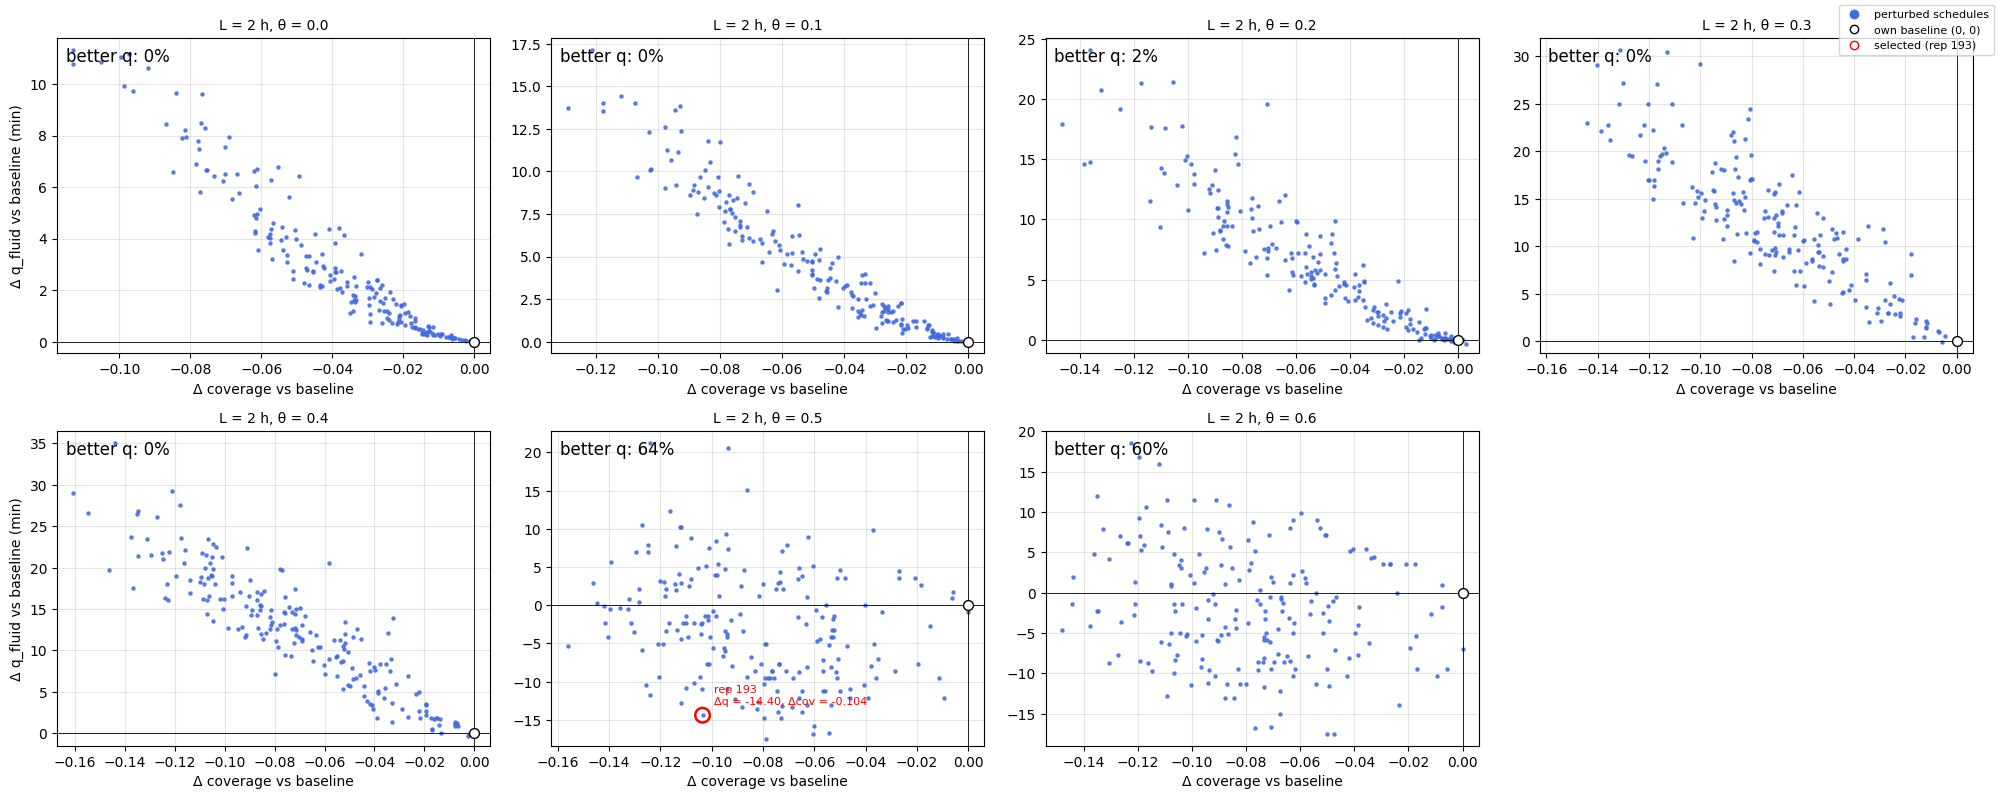

In [123]:
day = pd.Timestamp("2026-03-29")
inherit = True
L = 2
rep_theta = 193
theta_hl = 0.5

df_pert_fluid["date"] = pd.to_datetime(df_pert_fluid["date"]).dt.normalize()
d_day = df_pert_fluid[(df_pert_fluid["date"] == day) & (df_pert_fluid["inherit"] == inherit)
                      & (df_pert_fluid["lengths"] == f"[{L}]")].copy()

key = ["theta"]
base = d_day[d_day["is_baseline"]][key + ["coverage", "q_fluid"]].rename(columns={"coverage": "cov0", "q_fluid": "q0"})
d = d_day.merge(base, on=key)
d["dcov"], d["dq"] = d["coverage"] - d["cov0"], d["q_fluid"] - d["q0"]

Q_MAX = 60
d = d[d["q0"] < Q_MAX]

theta_in = [t for t in sorted(d["theta"].unique()) if t <= 0.7]
max_cols = 4; n_rows = math.ceil(len(theta_in) / max_cols); n_cols = min(len(theta_in), max_cols)

for length in sorted(d["lengths"].unique()):
    dl = d[d["lengths"] == length]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False); flat = axes.ravel()
    for ax, a in zip(flat, theta_in):
        g = dl[dl["theta"] == a]
        ax.set_title(f"L = {length.strip('[]')} h, θ = {a}", fontsize=10)
        if g.empty:
            ax.axis("off"); continue
        ax.scatter(g["dcov"], g["dq"], s=5, alpha=0.8, color="royalblue", rasterized=True, zorder=2)
        pooled = (g["dq"] < -0.1).mean()
        ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
        ax.scatter([0], [0], s=50, color="white", edgecolor="black", zorder=5)

        (xl, xh), (yl, yh) = g["dcov"].quantile([0.005, 0.995]), g["dq"].quantile([0.005, 0.995])
        if rep_theta is not None and (theta_hl is None or np.isclose(a, theta_hl)):
            h = g[g["rep_theta"] == rep_theta]
            if not h.empty:
                ax.scatter(h["dcov"], h["dq"], s=110, facecolor="none", edgecolor="red", linewidths=1.8, zorder=6)
                ax.annotate(f"rep {rep_theta}\nΔq = {h['dq'].iloc[0]:+.2f}, Δcov = {h['dcov'].iloc[0]:+.3f}",
                            (h["dcov"].iloc[0], h["dq"].iloc[0]), textcoords="offset points", xytext=(8, 8),
                            color="red", fontsize=8, zorder=7)
                xl, xh = min(xl, h["dcov"].min()), max(xh, h["dcov"].max())      # il punto evidenziato resta nel riquadro
                yl, yh = min(yl, h["dq"].min()), max(yh, h["dq"].max())

        xl, xh, yl, yh = min(xl, 0), max(xh, 0), min(yl, 0), max(yh, 0)           # includo sempre lo zero
        mx, my = 0.04 * (xh - xl), 0.04 * (yh - yl)
        ax.set_xlim(xl - mx, xh + mx); ax.set_ylim(yl - my, yh + my)
        ax.text(0.02, 0.97, f"better q: {pooled:.0%}", transform=ax.transAxes, va="top", fontsize=12)
        ax.set_xlabel("Δ coverage vs baseline"); ax.grid(color="gray", alpha=0.2)
    for ax in flat[len(theta_in):]: ax.axis("off")
    for ax in axes[:, 0]:
        if ax.axison: ax.set_ylabel("Δ q_fluid vs baseline (min)")
    fig.legend(handles=[Line2D([], [], marker="o", ls="", color="royalblue", label="perturbed schedules"),
                        Line2D([], [], marker="o", ls="", mfc="white", mec="black", label="own baseline (0, 0)"),
                        Line2D([], [], marker="o", ls="", mfc="none", mec="red", label=f"selected (rep {rep_theta})")],
               loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()

2026-11-26 14:46:06,226 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.


grid: (4, 83) | 2026-03-29 03:15:00 → 2026-03-29 23:45:00
rep_theta: 0 → 193
q_fluid: 52.40 → 38.01 | Δ coverage = -0.104 | movements applied: 6


2026-11-26 14:46:07,741 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers
2026-11-26 14:46:21,860 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers


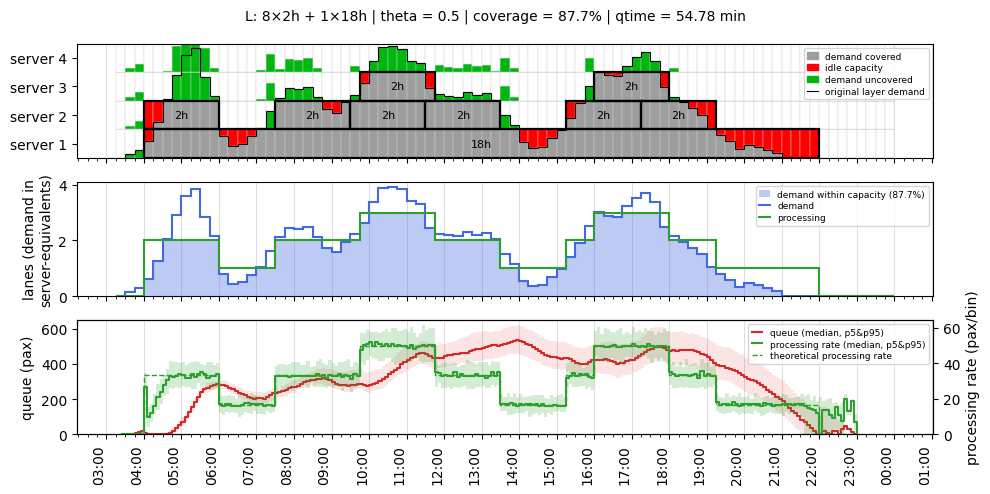

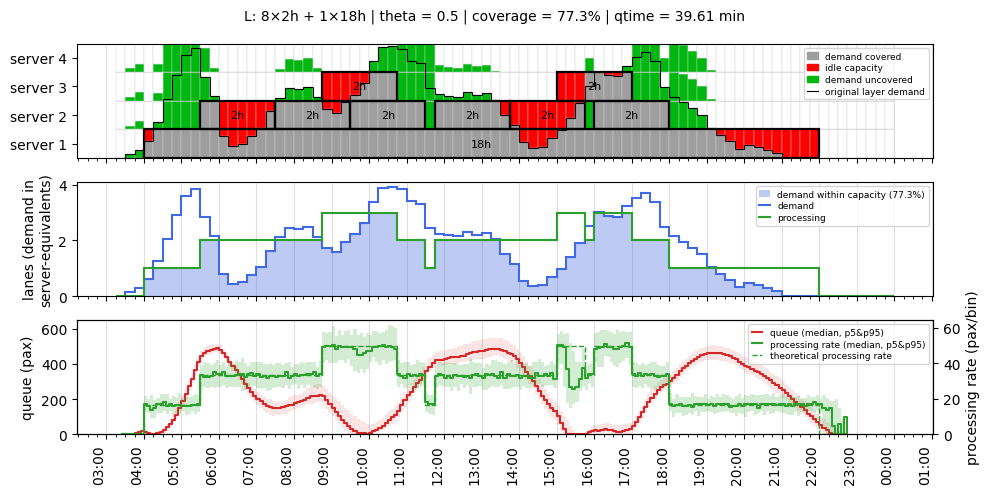

         baseline  perturbed
mean       54.784     39.629
p50        46.061     29.142
p90       106.181     80.568
p95       123.114    115.228
p99       139.120    138.602
P(W>15)     0.933      0.674


In [127]:
import json, numpy as np, pandas as pd
from app.services.coverage_dp import effective_grid

# ---------------- parametri
inherit, L, theta = True, 2, 0.5     # L in ore
rep_b = 193
n_scenarios = 50

# ---------------- planner e voli del giorno scelto
def make_day(d, schedule_std, arrival_model, server_registry, pax_model="data/pax_model.joblib"):
    sched = schedule_std[schedule_std["date"] == d].copy()
    pred = predictive.predict_pax(df=sched, path=pax_model)
    fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
    return security_class.SecurityPlanner(samplers.expected_arrivals(fd), server_registry), fd

planner, flight_demand = make_day(day, schedule_std, arrival_model, server_registry)
print("grid:", planner.demand_grid.shape, "|", planner.arrivals.index[0], "→", planner.arrivals.index[-1])

# ---------------- scelta dei due punti
df = df_pert_fluid.copy(); df["date"] = pd.to_datetime(df["date"]).dt.normalize()
g = df[(df["date"] == day) & (df["inherit"] == inherit) & (df["lengths"] == f"[{L}]") & np.isclose(df["theta"], theta)].copy()
r_a = g[g["is_baseline"]].iloc[0]
gp = g[~g["is_baseline"]].copy()
gp["dq"], gp["dcov"] = gp["q_fluid"] - r_a["q_fluid"], gp["coverage"] - r_a["coverage"]
r_b = gp.loc[gp["dq"].idxmin()] if rep_b is None else g[g["rep_theta"] == rep_b].iloc[0]
print(f"rep_theta: {r_a['rep_theta']} → {r_b['rep_theta']}")
print(f"q_fluid: {r_a['q_fluid']:.2f} → {r_b['q_fluid']:.2f} | Δ coverage = {r_b['coverage'] - r_a['coverage']:+.3f} | "
      f"movements applied: {r_b['n_moves']}")

def run_point(row, flight_demand, server_registry, planner, n_scenarios=50, n_workers=6, base_seed=42):
    D = np.asarray(planner.demand_grid, float); T = D.shape[1]
    time_values = pd.DatetimeIndex(planner.arrivals.index)[:T]
    assert len(time_values) == T, "arrivals index and demand_grid have different lengths"
    labels = list(utils.sort_labels_by_priority(server_registry))
    blocks = {lab: [(int(s), int(l)) for s, l in bl] for lab, bl in json.loads(row["blocks"]).items()}

    step = pd.Timedelta(minutes=planner.bin_minutes); t0 = pd.Timestamp(time_values[0])
    sched = {lab: [((t0 + s * step).to_pydatetime(), (t0 + (s + l) * step).to_pydatetime()) for s, l in bl]
             for lab, bl in blocks.items() if len(bl)}
    sim = security_class.SecuritySimulator(flight_demand=flight_demand,
                                           intervals=utils.server_schedule_to_intervals(sched),
                                           server_registry=server_registry)
    res = sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=5, base_seed=base_seed)

    covs = []                                                      # copertura per riga -> domanda ereditata
    for lab in labels[:D.shape[0]]:
        c = np.zeros(T, dtype=bool)
        for s, l in blocks.get(lab, []): c[s:s + l] = True
        covs.append(c)
    return dict(res=res, blocks=blocks, labels=labels, D=D, D_eff=effective_grid(D, covs),
                time_values=time_values, proc=np.sum(covs, axis=0).astype(float))

def plot_point(p, theta, queue_max, bin_minutes=15):
    plotutils.plot_blocks(D=p["D_eff"], D_ref=p["D"], blocks=p["blocks"], labels=p["labels"],
                          time_values=p["time_values"], theta=theta, bin_minutes=bin_minutes,
                          demand_curve=p["D"].sum(axis=0), processing_curve=p["proc"],
                          df_timeline=p["res"].df_timeline, df_kpis=p["res"].df_kpis, queue_max=queue_max)

def wait_stats(cdf):
    e = np.r_[cdf["queue_time_bin_start"].iloc[0], cdf["queue_time_bin_end"].values].astype(float)
    n = cdf["cum_count"].values.astype(float); p = np.r_[0.0, n / n[-1]]
    r = {"mean": (np.diff(p) * (e[:-1] + e[1:]) / 2).sum()}
    r.update({f"p{int(q*100)}": np.interp(q, p, e) for q in (0.5, 0.9, 0.95, 0.99)})
    r["P(W>15)"] = 1 - np.interp(15, e, p)
    return r

pa = run_point(r_a, flight_demand, server_registry, planner, n_scenarios=n_scenarios, base_seed=base_seed)
pb = run_point(r_b, flight_demand, server_registry, planner, n_scenarios=n_scenarios, base_seed=base_seed)

qmax = int(max(p["res"].df_timeline["queue_length_p95"].max() for p in (pa, pb)) * 1.05)
plot_point(pa, theta=theta, queue_max=qmax)
plot_point(pb, theta=theta, queue_max=qmax)

print(pd.DataFrame({"baseline": wait_stats(pa["res"].df_queue_cdf),
                    "perturbed": wait_stats(pb["res"].df_queue_cdf)}).round(3))

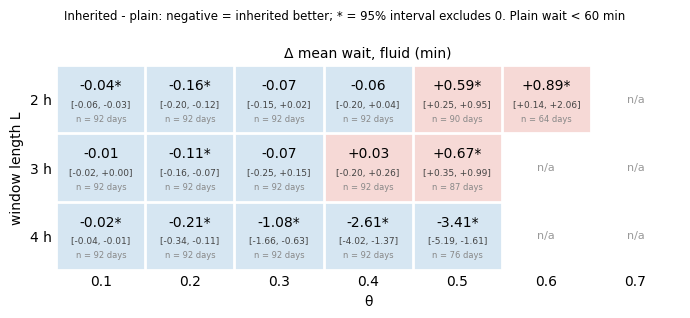

In [163]:
TOL = {"mean": 0.1, "p90": 0.5, "p95": 0.5, "p99": 1.0, "P(W>10)": 0.005, "P(W>15)": 0.005}

def summarize_days(df, metrics=("p95", "p99", "P(W>15)"), by=("theta",), tol=TOL, q_max=30,
                   n_boot=2000, seed=0):
    key = ["day", "L", "theta"]
    p, i = df[~df.inherit].set_index(key), df[df.inherit].set_index(key)
    d = pd.DataFrame({"changed": i["changed"], "q_plain": p["q_fluid"]})
    for m in metrics:
        d["d_" + m] = (i[m] - p[m]).where(d["changed"], 0.0)       # profilo identico -> delta = 0
    d = d[d["q_plain"] < q_max].reset_index()                       # solo i casi che il decisore considererebbe
    rng, out = np.random.default_rng(seed), []
    for k, g in d.groupby(list(by)):
        k = k if isinstance(k, tuple) else (k,)
        groups = [gg for _, gg in g.groupby("day")]                 # bootstrap sui giorni
        nd = len(groups)
        for m in metrics:
            blocks = [b["d_" + m].dropna().to_numpy() for b in groups]
            sums = np.array([b.sum() for b in blocks]); cnts = np.array([len(b) for b in blocks])
            x = np.concatenate(blocks)
            if len(x) == 0: continue
            idx = rng.integers(0, nd, size=(n_boot, nd))
            boots = sums[idx].sum(axis=1) / cnts[idx].sum(axis=1)
            out.append(dict(zip(by, k), metric=m, n=len(x), days=nd, changed=g["changed"].mean(),
                            mean=x.mean(), ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                            median=np.median(x), better=(x < -tol[m]).mean(), worse=(x > tol[m]).mean()))
    return pd.DataFrame(out).round(3)

from matplotlib.colors import ListedColormap

def heat_L_theta(df, q_max=15, min_days=15, need_sig=False,
                 metrics=(("p95", "Δ p95 (min)", 1, 1), ("P(W>15)", "Δ P(W>15) (pp)", 100, 1))):
    """Colore = segno della differenza (blu chiaro < 0, rosa chiaro > 0). need_sig=True: colora solo se l'intervallo esclude 0."""
    s = summarize_days(df, by=("L", "theta"), q_max=q_max, metrics=tuple(m[0] for m in metrics))
    Ls, ths = sorted(s["L"].unique()), sorted(s["theta"].unique())
    # remove theta=0
    ths = [t for t in ths if t > 0]
    cmap = ListedColormap(["#d6e6f2", "#f6d9d6"])                 # negativo, positivo
    fig, axs = plt.subplots(1, len(metrics), figsize=(7* len(metrics), 3.2))
    for ax, (m, title, k, d) in zip(np.atleast_1d(axs), metrics):
        g = s[s.metric == m].set_index(["L", "theta"])
        sign = np.full((len(Ls), len(ths)), np.nan); cells = {}
        for a, L in enumerate(Ls):
            for b, t in enumerate(ths):
                if (L, t) not in g.index or g.loc[(L, t), "days"] < min_days:
                    cells[(a, b)] = None; continue
                r = g.loc[(L, t)]; sig = r.ci_lo > 0 or r.ci_hi < 0
                if sig or not need_sig: sign[a, b] = 1.0 if r["mean"] > 0 else 0.0
                cells[(a, b)] = (f"{r['mean']*k:+.{d}f}{'*' if sig else ''}",
                 f"[{r.ci_lo*k:+.{d}f}, {r.ci_hi*k:+.{d}f}]",
                 f"n = {int(r['days'])} days")

                
        ax.imshow(np.ma.masked_invalid(sign), cmap=cmap, vmin=0, vmax=1, aspect="auto")
        for (a, b), c in cells.items():
            if c is None:
                ax.text(b, a, "n/a", ha="center", va="center", fontsize=8, color="#999")
            else:
                ax.text(b, a - 0.2, c[0], ha="center", va="center", fontsize=10)
                ax.text(b, a + 0.08, c[1], ha="center", va="center", fontsize=6.5, color="#444")
                ax.text(b, a + 0.28, c[2], ha="center", va="center", fontsize=6, color="#888")
        ax.set_xticks(range(len(ths))); ax.set_xticklabels([f"{t:g}" for t in ths]); ax.set_xlabel("θ")
        ax.set_yticks(range(len(Ls))); ax.set_yticklabels([f"{L} h" for L in Ls]); ax.set_ylabel("window length L")
        ax.set_title(title, fontsize=10)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_xticks(np.arange(-.5, len(ths)), minor=True); ax.set_yticks(np.arange(-.5, len(Ls)), minor=True)
        ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="both", length=0)
    fig.suptitle(f"Inherited - plain: negative = inherited better; * = 95% interval excludes 0. "
                 f"Plain wait < {q_max} min", fontsize=8.5)
    fig.tight_layout(); plt.show()

b = df_pert_fluid[df_pert_fluid["is_baseline"]].copy()
b["day"] = pd.to_datetime(b["date"]).dt.normalize()
b["L"] = b["lengths"].str.strip("[]").astype(int)
key = ["day", "L", "theta"]

sig = b.pivot_table(index=key, columns="inherit", values="blocks", aggfunc="first")     # blocchi delle due baseline
changed = (sig[False] != sig[True]).rename("changed").reset_index()
df_base = b[key + ["inherit", "q_fluid"]].merge(changed, on=key)

TOL["q_fluid"] = 0.1                                                                    # tolleranza per "better/worse"
heat_L_theta(df_base, q_max=60, min_days=30,
             metrics=(("q_fluid", "Δ mean wait, fluid (min)", 1, 2),))

In [171]:
df_pert_fluid

,date,inherit,lengths,length_totals,K_total,theta,first_server,batch,n_blocks,rep,...,n_pax,covered_demand,idle_capacity,coverage_sum,objective,coverage,q_fluid,n_moves,moves,blocks
0,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,0,...,6707.0,133.705491,66.294509,0.996761,133.705491,0.996761,0.043288,0,[],"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,1,...,6707.0,126.621731,73.378269,0.943952,126.621731,0.943952,3.135614,12,"[[""3"", 2, -2], [""4"", 1, 5], [""3"", 1, -1], [""2""...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,2,...,6707.0,127.962613,72.037387,0.953948,127.962613,0.953948,2.194102,5,"[[""3"", 3, 1], [""3"", 1, -3], [""2"", 6, 5], [""2"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,3,...,6707.0,118.541394,81.458606,0.883714,118.541394,0.883714,10.830848,11,"[[""2"", 5, -2], [""3"", 5, 5], [""3"", 3, 3], [""4"",...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-03-29,False,[2],{2: 1000},1000,0.0,"('04:00', '22:00')",0,17,4,...,6707.0,130.902349,69.097651,0.975864,130.902349,0.975864,1.067567,2,"[[""3"", 3, 3], [""4"", 2, -5]]","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
861893,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861893,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,282.430125,1,"[[""2"", 0, -1]]","{""1"": [[3, 72]], ""2"": [[18, 16], [48, 16]]}"
861894,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861894,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,289.495345,1,"[[""2"", 0, 3]]","{""1"": [[3, 72]], ""2"": [[22, 16], [48, 16]]}"
861895,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861895,...,6794.0,88.346776,15.653224,0.650182,15.546776,0.650182,285.962520,1,"[[""2"", 0, 1]]","{""1"": [[3, 72]], ""2"": [[20, 16], [48, 16]]}"
861896,2026-06-29,True,[4],{4: 1000},1000,0.7,"('04:00', '22:00')",0,3,861896,...,6794.0,86.874096,17.125904,0.639344,14.074096,0.639344,287.729068,1,"[[""2"", 1, 2]]","{""1"": [[3, 72]], ""2"": [[19, 16], [50, 16]]}"


righe totali: 861898 | ottimi (n_moves = 0): 4416
duplicati per (day, L, θ, inherit): 0
inh        day  L_h  theta   q_plain     q_inh
0   2026-03-29  2.0    0.0  0.043288  0.043288
1   2026-03-29  2.0    0.1  0.066697  0.066697
2   2026-03-29  2.0    0.2  1.761917  1.550506
3   2026-03-29  2.0    0.3  5.099247  5.278653
4   2026-03-29  2.0    0.4  5.099247  5.278653


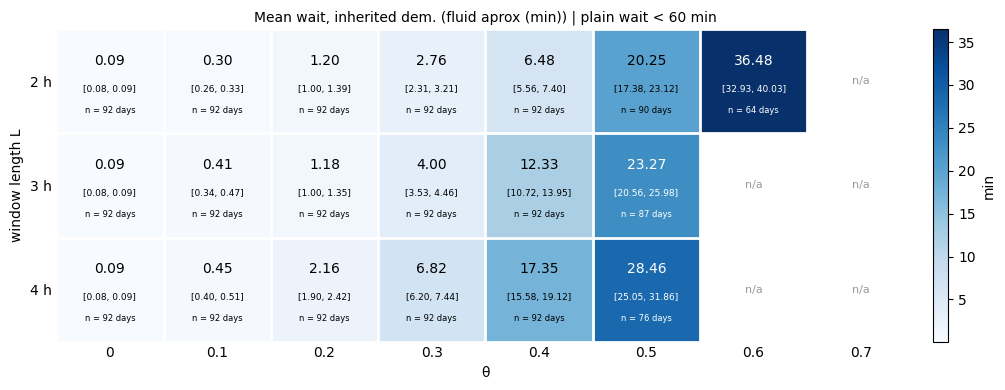

In [173]:
# ---------- 1) preparazione: una riga per (giorno, L, θ) con plain e inherited affiancati
def _first_len(x):
    if isinstance(x, str): x = json.loads(x)          # gestisce "[2]" come stringa
    return float(np.atleast_1d(x)[0])                  # e [2] come lista o array

df = df_pert_fluid.copy()
df["L_h"]   = df["lengths"].map(_first_len)            # lunghezza finestra in ore
df["theta"] = df["theta"].astype(float).round(1)
df["day"]   = pd.to_datetime(df["date"]).dt.normalize()
df["inh"]   = df["inherit"].astype(str).str.lower().isin(["true", "1"])

base = df[df["n_moves"].astype(int) == 0]              # solo soluzione ottima, niente perturbazioni
print(f"righe totali: {len(df)} | ottimi (n_moves = 0): {len(base)}")
print("duplicati per (day, L, θ, inherit):", base.duplicated(["day", "L_h", "theta", "inh"]).sum())

fl = (base.groupby(["day", "L_h", "theta", "inh"])["q_fluid"].mean()
          .unstack("inh")
          .rename(columns={False: "q_plain", True: "q_inh"})
          .reset_index())
print(fl.head())

# ---------- 2) heatmap del livello (media sui giorni ± IC 95%)
def heat_mean(fl, col="q_inh", filt_col="q_plain", q_max=60, min_days=30, d=2,
              title="Mean wait, inherited dem. (fluid aprox (min))", cmap="Blues", vmin=None, vmax=None):
    x = fl[fl[filt_col] < q_max] if filt_col else fl
    s = x.groupby(["L_h", "theta"])[col].agg(["mean", "std", "count"])
    s = s[s["count"] >= min_days]
    s["h"] = 1.96 * s["std"] / np.sqrt(s["count"])

    Ls, ths = sorted(fl["L_h"].unique()), sorted(fl["theta"].unique())
    M = np.full((len(Ls), len(ths)), np.nan)
    for (L, t), r in s.iterrows():
        M[Ls.index(L), ths.index(t)] = r["mean"]

    fig, ax = plt.subplots(figsize=(1.05 * len(ths) + 1.8, 1.0 * len(Ls) + 1.0))
    im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    for a in range(len(Ls)):
        for b in range(len(ths)):
            v = M[a, b]
            if np.isnan(v):
                ax.text(b, a, "n/a", ha="center", va="center", fontsize=8, color="#999"); continue
            r = s.loc[(Ls[a], ths[b])]
            c = "white" if im.norm(v) > 0.6 else "black"
            ax.text(b, a - 0.2, f"{v:.{d}f}", ha="center", va="center", fontsize=10, color=c)
            ax.text(b, a + 0.08, f"[{v - r['h']:.{d}f}, {v + r['h']:.{d}f}]",
                    ha="center", va="center", fontsize=6.5, color=c)
            ax.text(b, a + 0.28, f"n = {int(r['count'])} days", ha="center", va="center", fontsize=6, color=c)

    ax.set_xticks(range(len(ths))); ax.set_xticklabels([f"{t:g}" for t in ths]); ax.set_xlabel("θ")
    ax.set_yticks(range(len(Ls))); ax.set_yticklabels([f"{L:g} h" for L in Ls]); ax.set_ylabel("window length L")
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xticks(np.arange(-.5, len(ths)), minor=True); ax.set_yticks(np.arange(-.5, len(Ls)), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="both", length=0)
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="min")
    ax.set_title(title + (f" | plain wait < {q_max} min" if filt_col else ""), fontsize=10)
    fig.tight_layout(); plt.show()

# ---------- 3) uso
heat_mean(fl, col="q_inh", q_max=60, min_days=30)

#### SA

##### manual

2026-11-26 10:47:04,476 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 10:47:04,510 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 10:47:06,211 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers


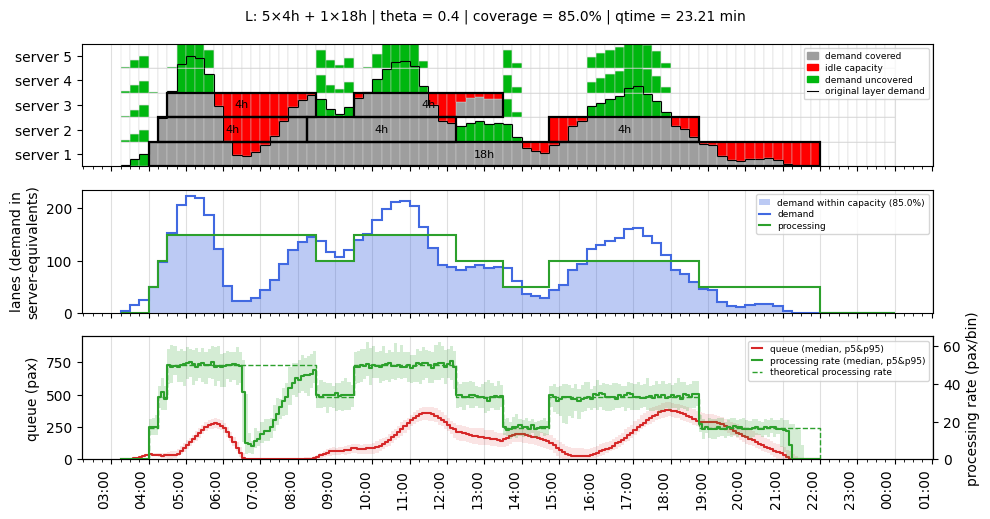

In [8]:
date=dt.datetime(2026, 6, 1)
theta = 0.4
lengths=[4]
length_totals={}
K_total=100
first_server=("04:00", "22:00")

schedule_or = pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std = preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))
flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

arrivals= samplers.expected_arrivals(flight_demand)
planner = security_class.SecurityPlanner(arrivals, server_registry)

res = planner.run(lengths=lengths, length_totals=length_totals, theta=theta, K_total=K_total, first_server=first_server, inherit=True)

classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)
sim_base_results = classe2.run(n_scenarios=50, n_workers=6, timebin=5, base_seed=base_seed)

plotutils.plot_allocation(res, df_timeline=sim_base_results.df_timeline, df_kpis=sim_base_results.df_kpis, queue_max=950)

annealing: 5000 iters, T0=6.283 -> T_end=0.006283 min, E0=21.4975
iter 500: T=3.149 E_cur=31.6527 E_best=18.3609 acc=74.4%
iter 1000: T=1.578 E_cur=23.1179 E_best=18.3609 acc=66.6%
iter 1500: T=0.791 E_cur=22.1825 E_best=18.3609 acc=58.5%
iter 2000: T=0.3964 E_cur=22.4770 E_best=18.3609 acc=52.3%
iter 2500: T=0.1987 E_cur=19.2966 E_best=18.3609 acc=44.0%
iter 3000: T=0.09957 E_cur=19.1947 E_best=18.3609 acc=37.2%
iter 3500: T=0.04991 E_cur=19.1947 E_best=18.3609 acc=32.0%
iter 4000: T=0.02501 E_cur=19.1947 E_best=18.3609 acc=28.0%
iter 4500: T=0.01254 E_cur=19.1947 E_best=18.3609 acc=24.9%
iter 5000: T=0.006283 E_cur=19.1947 E_best=18.3609 acc=22.4%


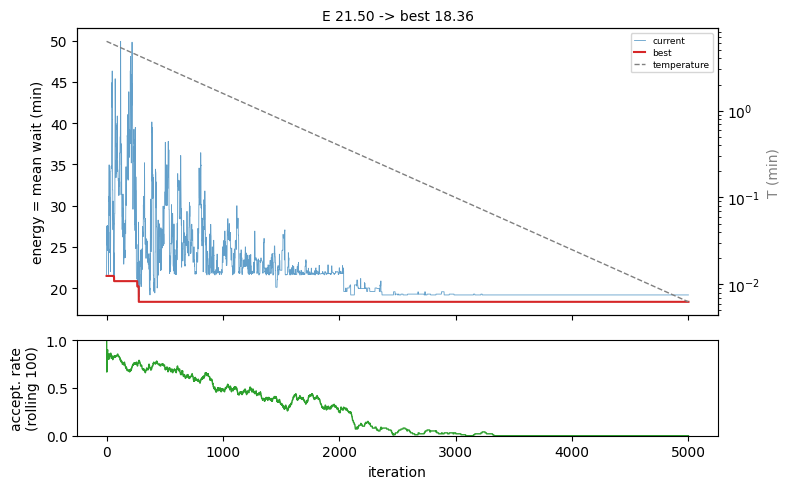

2026-11-26 10:47:32,588 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 4 workers


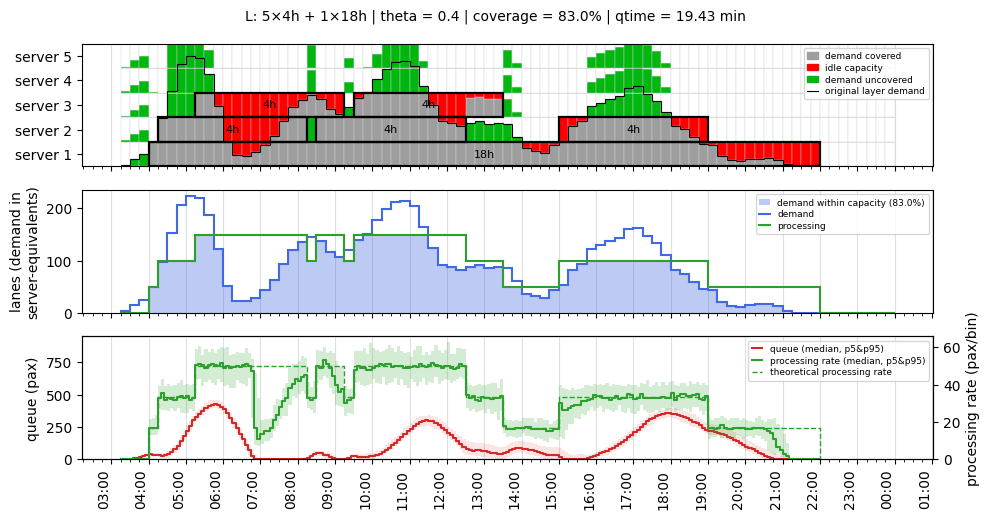

In [9]:
from app.services import local_search as ls
from app.services.perturbation import schedule_to_blocks, blocks_to_schedule, res_with_blocks

blocks0 = schedule_to_blocks(planner, res)
fixed_labels = {res.server_labels[0]} if first_server else set()

if first_server:
    (s0, l0), = blocks0[res.server_labels[0]]
    bounds = (s0, s0 + l0)
else:
    bounds = None

best_blocks, trace = ls.simulated_annealing(
    arrivals=planner.arrivals.to_numpy(), 
    rates=planner.rate_by_label, 
    D=res.demand_grid, 
    labels=list(res.server_labels), 
    theta=res.theta,
    blocks0=blocks0, 
    bin_minutes=planner.bin_minutes,
    fixed=fixed_labels, 
    bounds=bounds,
    n_iter=5000, max_step=4, p_jump=0.1, full_every=250, seed=0)

ls.plot_annealing_trace(trace)

# schedule finale: simulazione e plot come per la baseline
res_best = res_with_blocks(planner, res, best_blocks)
sim_best = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res_best.server_schedule),
    server_registry=server_registry).run(n_scenarios=50, n_workers=4, timebin=5, base_seed=base_seed)
plotutils.plot_allocation(res_best, df_timeline=sim_best.df_timeline, df_kpis=sim_best.df_kpis, queue_max=950)

In [18]:
trace

,iter,T,move,E_cand,E_cur,E_best,accepted,q_fluid,n_accepted,coverage,objective
0,0,3.759152,None,21.462468,21.462468,21.462468,True,21.462468,0,NaN,NaN
1,1,3.753962,"(2, 0, 2)",15.179261,15.179261,15.179261,True,15.179261,1,NaN,NaN
2,2,3.748780,"(4, 0, 3)",17.784956,17.784956,15.179261,True,17.784956,2,NaN,NaN
3,3,3.743604,"(4, 0, 3)",20.390642,20.390642,15.179261,True,20.390642,3,NaN,NaN
4,4,3.738436,None,41.236273,20.390642,15.179261,False,20.390642,3,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
4996,4996,0.003780,None,15.771633,14.039306,12.697592,False,14.039306,671,NaN,NaN
4997,4997,0.003775,None,23.333981,14.039306,12.697592,False,14.039306,671,NaN,NaN
4998,4998,0.003770,None,17.521333,14.039306,12.697592,False,14.039306,671,NaN,NaN
4999,4999,0.003764,None,16.349836,14.039306,12.697592,False,14.039306,671,NaN,NaN


##### loop

In [5]:
from app.services import local_search as ls
from app.services.perturbation import (schedule_to_blocks, blocks_to_schedule, coverage_from_blocks,
                                       compute_coverage)

thetas = [round(t, 6) for t in np.arange(0.1, 0.7, 0.1)]
seeds = [i for i in range(21)]
n_iter = 3000
arr_np = planner.arrivals.to_numpy()

traces, pairs, rows = {}, {}, []
for th in thetas:
    res_t = planner.run(lengths=lengths, length_totals=length_totals, theta=th, K_total=K_total,
                        first_server=first_server)
    b0 = schedule_to_blocks(planner, res_t)
    fixed_labels = {res_t.server_labels[0]} if first_server else set()
    if first_server:
        (s0, l0), = b0[res_t.server_labels[0]]
        bounds = (s0, s0 + l0)
    else:
        bounds = None
    for seed in seeds:
        best, tr = ls.simulated_annealing(
            arr_np, planner.rate_by_label, res_t.demand_grid, list(res_t.server_labels), res_t.theta,
            b0, planner.bin_minutes, fixed=fixed_labels, bounds=bounds,
            n_iter=n_iter, max_step=4, p_jump=0.1, full_every=0, seed=seed, verbose=False)
        traces[(th, seed)], pairs[(th, seed)] = tr, (b0, best)
        c0, c1 = coverage_from_blocks(planner, res_t, b0), coverage_from_blocks(planner, res_t, best)
        rows.append(dict(theta=th, seed=seed,
                         q_fluid_base=tr["E_cur"].iloc[0], q_fluid_sa=tr["E_best"].iloc[-1],
                         accepted=int(tr["n_accepted"].iloc[-1]),
                         cov_slot_base=compute_coverage(arr_np, planner.rate_by_label, b0),
                         cov_slot_sa=compute_coverage(arr_np, planner.rate_by_label, best),
                         obj_base=c0["objective"], obj_sa=c1["objective"]))
df_sa = pd.DataFrame(rows)

2026-11-20 17:47:53,883 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 17:48:07,089 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 17:48:16,826 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 17:48:27,012 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 17:48:36,944 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-20 17:48:46,174 | INFO | app.services.security_class | [SecurityPlanner] running


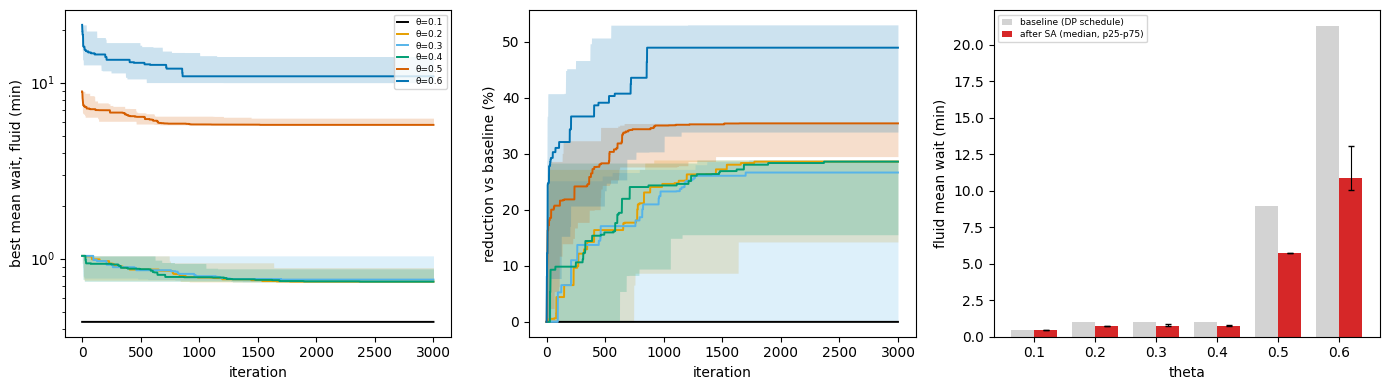

In [8]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4))
OKABE_ITO = ["#000000", "#E69F00", "#56B4E9", "#009E73", "#D55E00", "#0072B2", "#CC79A7", "#F0E442"]
color_of = {th: OKABE_ITO[i % len(OKABE_ITO)] for i, th in enumerate(thetas)}
for th in thetas:
    trs = [traces[(th, s)] for s in seeds]
    it = trs[0]["iter"].to_numpy()
    E = np.vstack([t["E_best"].to_numpy() for t in trs])
    red = 100 * (1 - E / E[:, [0]])
    c = color_of[th]
    for ax, Y, lab in ((a1, E, f"θ={th:g}"), (a2, red, None)):
        ax.plot(it, np.median(Y, axis=0), color=c, lw=1.4, label=lab)
        ax.fill_between(it, np.percentile(Y, 5, axis=0), np.percentile(Y, 95, axis=0),
                        color=c, alpha=0.2, linewidth=0)
a1.set_yscale("log"); a1.set_xlabel("iteration"); a1.set_ylabel("best mean wait, fluid (min)")
a2.set_xlabel("iteration"); a2.set_ylabel("reduction vs baseline (%)")
a1.legend(fontsize=6.5, loc="upper right", handlelength=1.2, borderpad=0.4, labelspacing=0.3)

g = df_sa.groupby("theta")
base = g["q_fluid_base"].first()
med = g["q_fluid_sa"].median()
lo, hi = g["q_fluid_sa"].quantile(0.25), g["q_fluid_sa"].quantile(0.75)
x = np.arange(len(base)); w = 0.38
a3.bar(x - w/2, base.to_numpy(), w, color="lightgray", label="baseline (DP schedule)")
a3.bar(x + w/2, med.to_numpy(), w, color="tab:red", label="after SA (median, p25-p75)",
       yerr=[(med - lo).to_numpy(), (hi - med).to_numpy()], capsize=2, error_kw=dict(lw=0.8))
a3.set_xticks(x); a3.set_xticklabels([f"{t:g}" for t in base.index])
a3.set_xlabel("theta"); a3.set_ylabel("fluid mean wait (min)")
a3.legend(fontsize=6.5, loc="upper left", handlelength=1.2, borderpad=0.4, labelspacing=0.3)
fig.tight_layout(); plt.show()

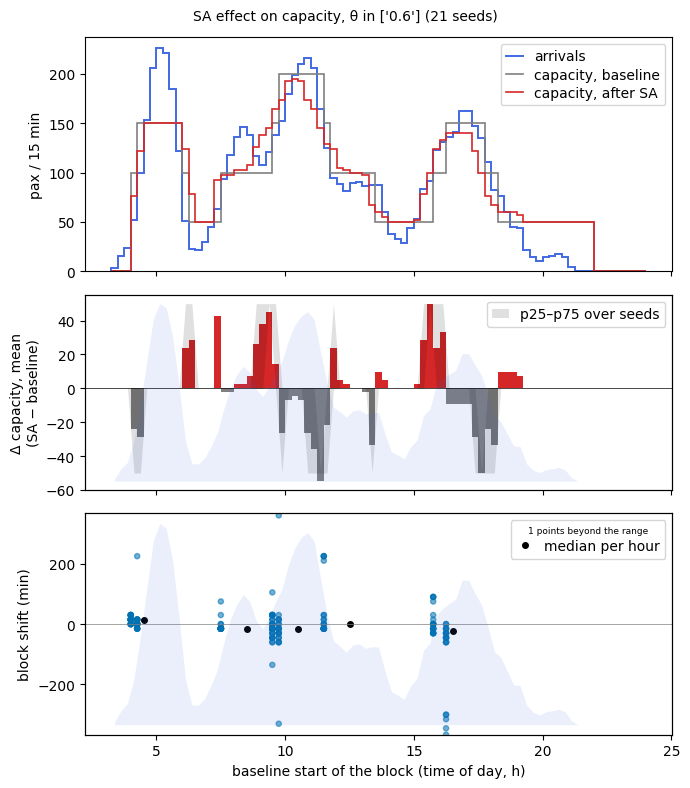

shift       1.000000
skew        0.276905
q_before   -0.324172
q_after     0.138428
Name: shift, dtype: float64


In [12]:
from app.services.fluid_approx import fluid_diagnostics, capacity_per_slot

tv = pd.to_datetime(planner.time_values)
time_h = (tv.hour + tv.minute / 60).to_numpy()
bm = planner.bin_minutes
edges = np.append(time_h, time_h[-1] + bm / 60)

def shift_summary(thetas=thetas, seeds=seeds, min_change=1e-9):
    """Una figura sola: effetto medio dell'SA sulla capacità per ora del giorno, su tutti i theta e i seed."""
    fixed_label = str(planner.server_labels[0]) if first_server else None
    T = len(arr_np)
    cap0, dcap, ths_used, blk = {}, {}, [], []
    for th in thetas:
        b0 = pairs[(th, seeds[0])][0]
        cap0[th] = capacity_per_slot(b0, planner.rate_by_label, T)
        dg = fluid_diagnostics(arr_np, cap0[th], bm)
        dc = np.vstack([capacity_per_slot(pairs[(th, s)][1], planner.rate_by_label, T) - cap0[th] for s in seeds])
        dcap[th] = dc
        if np.abs(dc).max() > min_change:
            ths_used.append(th)
        for s in seeds:
            bs = pairs[(th, s)][1]
            for lab in b0:
                if str(lab) == fixed_label:
                    continue
                for i, ((s0, l), (s1, _)) in enumerate(zip(sorted(b0[lab]), sorted(bs[lab]))):
                    w = arr_np[s0:s0 + l]; h = l // 2
                    blk.append(dict(theta=th, seed=s, lane=lab, start=s0, shift=s1 - s0,
                                    skew=(w[h:].sum() - w[:h].sum()) / max(w.sum(), 1e-9),
                                    q_before=dg["queue_end"].iloc[s0 - 1] if s0 > 0 else 0.0,
                                    q_after=dg["queue_end"].iloc[min(s0 + l - 1, T - 1)]))
    blocks = pd.DataFrame(blk)
    med_by_theta = np.vstack([np.median(dcap[th], axis=0) for th in thetas])
    pooled = np.vstack([dcap[th] for th in ths_used]) if ths_used else np.zeros((1, T))
    base_mean = np.mean([cap0[th] for th in ths_used], axis=0) if ths_used else np.zeros(T)

    if len(thetas) == 1:
        
        fig, (a1, a3, a4) = plt.subplots(3, 1, sharex=True, figsize=(7, 8),
                                            gridspec_kw={"height_ratios": [1.8, 1.5, 1.7]})

    else:
        fig, (a1, a2, a3, a4) = plt.subplots(4, 1, sharex=True, figsize=(7, 8),
                                            gridspec_kw={"height_ratios": [1.8, 1.6, 1.5, 1.7]})

    a1.stairs(arr_np, edges, color="royalblue", lw=1.4, label="arrivals")
    a1.stairs(base_mean, edges, color="gray", lw=1.2, label="capacity, baseline (mean over θ)" if len(ths_used) > 1 else "capacity, baseline")
    a1.stairs(base_mean + pooled.mean(axis=0), edges, color="tab:red", lw=1.2, label="capacity, after SA (mean over θ)" if len(ths_used) > 1 else "capacity, after SA")
    a1.set_ylabel(f"pax / {bm:g} min")
    a1.legend(loc="upper right", handlelength=1.2, borderpad=0.4, labelspacing=0.3)

    v = np.abs(med_by_theta).max() or 1.0

    if len(thetas) > 1:
        im = a2.pcolormesh(edges, np.arange(len(thetas) + 1), med_by_theta, cmap="RdBu_r", vmin=-v, vmax=v, shading="flat")
        a2.set_yticks(np.arange(len(thetas)) + 0.5); a2.set_yticklabels([f"θ={t:g}" for t in thetas], fontsize=7)
        a2.set_ylabel("Δ capacity (median over seeds)")
        cax = a2.inset_axes([1.01, 0, 0.015, 1]); fig.colorbar(im, cax=cax, label="pax / slot")

    m = pooled.mean(axis=0)
    a3.bar(time_h, m, width=bm / 60, align="edge", color=np.where(m >= 0, "tab:red", "gray"))
    a3.fill_between(time_h + bm / 120, np.percentile(pooled, 25, axis=0), np.percentile(pooled, 75, axis=0),
                    color="k", alpha=0.12, lw=0, label="p25–p75 over θ and seeds" if len(ths_used) > 1 else "p25–p75 over seeds")
    a3.axhline(0, color="k", lw=0.5); a3.set_ylabel("Δ capacity, mean\n(SA − baseline)")
    a3.legend(loc="upper right", handlelength=1.2, borderpad=0.4, labelspacing=0.3)
    ax_d = a3.twinx(); ax_d.fill_between(time_h + bm / 120, arr_np, color="royalblue", alpha=0.10, lw=0); ax_d.set_yticks([])

    # shift dei singoli blocchi per ora di inizio nella baseline, domanda in sfondo
    bu = blocks[blocks["theta"].isin(ths_used)].copy()
    bu["h"] = bu["start"].map(lambda k: time_h[k]); bu["shift_min"] = bu["shift"] * bm
    cols = bu["theta"].map(lambda t: color_of.get(t, "tab:red") if "color_of" in globals() else "tab:red")
    lim = max(60.0, float(np.percentile(bu["shift_min"].abs(), 98))) * 1.15 if len(bu) else 60.0
    a4.scatter(bu["h"], bu["shift_min"].clip(-lim, lim), c=cols, s=14, alpha=0.55)
    hb = bu.groupby(bu["h"].round().astype(int))["shift_min"].median()
    a4.plot(hb.index + 0.5, hb.values, "ko", ms=4, label="median per hour")
    a4.axhline(0, color="gray", lw=0.5); a4.set_ylim(-lim, lim)
    a4.set_ylabel("block shift (min)"); a4.set_xlabel("baseline start of the block (time of day, h)")
    n_out = int((bu["shift_min"].abs() > lim).sum())
    a4.legend(loc="upper right", handlelength=1.2, borderpad=0.4, labelspacing=0.3,
              title=f"{n_out} points beyond the range" if n_out else None, title_fontsize=6.5)
    ax_d2 = a4.twinx(); ax_d2.fill_between(time_h + bm / 120, arr_np, color="royalblue", alpha=0.10, lw=0); ax_d2.set_yticks([])
    fig.suptitle(f"SA effect on capacity, θ in {[f'{t:g}' for t in ths_used]} ({len(seeds)} seeds)", fontsize=10)
    fig.tight_layout(); plt.show()
    return blocks

blocks = shift_summary(thetas=[0.6])
b = blocks[blocks["shift"].abs() < 120 / bm]
print(b[["shift", "skew", "q_before", "q_after"]].corr(method="spearman")["shift"])

##### da perturbation test

In [25]:
import json, os
import numpy as np, pandas as pd
from app.services import local_search as ls
from app.services.perturbation import schedule_to_blocks, blocks_to_json, compute_coverage
from app.services.fluid_approx import capacity_per_slot, fluid_wait

def make_planner(d, schedule_std, arrival_model, server_registry, pax_model="data/pax_model.joblib"):
    sched = schedule_std[schedule_std["date"] == d].copy()
    pred = predictive.predict_pax(df=sched, path=pax_model)
    fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
    return security_class.SecurityPlanner(samplers.expected_arrivals(fd), server_registry)

In [51]:
def run_sa_study(dates, schedule_std, arrival_model, server_registry, LS, thetas, seeds, K_total=1000,
                 first_server=("04:00", "22:00"), n_iter=3000, max_step=4, p_jump=0.1, q_max=30,
                 out_path="data/sa_study.pkl"):
    df_prev = pd.read_pickle(out_path) if os.path.exists(out_path) else pd.DataFrame()
    rows = df_prev.to_dict("records")
    norm = lambda d: pd.Timestamp(d).normalize()
    done = {(norm(r["date"]), int(r["L"]), round(float(r["theta"]), 6), int(r["seed"])) for r in rows}   # seed=-1: saltato

    t0 = time.time()

    for n, d in enumerate(dates):
        day = norm(d)
        todo = [(L, round(float(t), 6)) for L in LS for t in thetas
                if (day, L, round(float(t), 6), -1) not in done
                and any((day, L, round(float(t), 6), s) not in done for s in seeds)]
        if not todo: continue
        try:
            planner = make_planner(d, schedule_std, arrival_model, server_registry)
        except Exception as e:
            print(f"[{n+1}/{len(dates)}] {day.date()} SKIP: {type(e).__name__}: {e}"); continue
        T = planner.demand_grid.shape[1]; arr_np = planner.arrivals.to_numpy()

        for L, th in todo:
            res_t = planner.run(lengths=[L], length_totals={L: K_total}, theta=th, K_total=K_total,
                                first_server=first_server, inherit=True)
            b0 = schedule_to_blocks(planner, res_t)
            labels = list(res_t.server_labels)
            fixed_labels = {labels[0]} if first_server else set()
            w = res_t.first_server_window
            bounds = (w[0], w[0] + w[1]) if (first_server and w) else None

            q0 = fluid_wait(arr_np, capacity_per_slot(b0, planner.rate_by_label, T), planner.bin_minutes)
            if q0 >= q_max:
                rows.append(dict(date=day, L=L, theta=th, seed=-1, skipped=True, q_fluid_base=q0)); continue
            for seed in seeds:
                best, tr = ls.simulated_annealing(
                    arr_np, planner.rate_by_label, res_t.demand_grid, labels, res_t.theta, b0, planner.bin_minutes,
                    fixed=fixed_labels, bounds=bounds, n_iter=n_iter, max_step=max_step, p_jump=p_jump,
                    full_every=0, seed=seed, verbose=False)
                rows.append(dict(date=day, L=L, theta=th, seed=seed, skipped=False, n_servers=len(labels),
                                 q_fluid_base=tr["E_cur"].iloc[0], q_fluid_sa=tr["E_best"].iloc[-1],
                                 accepted=int(tr["n_accepted"].iloc[-1]),
                                 cov_slot_base=compute_coverage(arr_np, planner.rate_by_label, b0),
                                 cov_slot_sa=compute_coverage(arr_np, planner.rate_by_label, best),
                                 blocks_base=blocks_to_json(b0), blocks_sa=blocks_to_json(best)))


        pd.DataFrame(rows).to_pickle(out_path)
        print(f"[{n+1}/{len(dates)}] {day.date()} saved ({len(rows)} rows, {(time.time()-t0)/60:.1f} min)")
    return pd.DataFrame(rows)

import time; t = time.time()
df_sa = run_sa_study(dates[:93], schedule_std, arrival_model, server_registry, LS=[2,3,4], thetas=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7],
                     seeds=range(5), out_path="data/sa_test.pkl")
df_sa

2026-11-26 12:30:26,506 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 12:30:26,522 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:28,777 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:30,805 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:32,908 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:35,074 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:35,084 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:35,092 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:35,100 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:38,091 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:30:40,432 | 

[1/93] 2026-03-29 saved (73 rows, 0.5 min)


2026-11-26 12:30:57,803 | WARNING | app.services.preprocessing | More than 10% of flights (13/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 12:30:57,815 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:00,246 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:02,480 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:04,764 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:07,034 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:09,209 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:11,768 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:11,777 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:14,037 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:16,346 |

[2/93] 2026-03-30 saved (158 rows, 1.1 min)


2026-11-26 12:31:36,733 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:39,091 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:41,256 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:43,621 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:45,900 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:48,035 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:48,042 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:50,171 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:52,315 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:54,557 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:56,715 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 12:31:58,8

[3/93] 2026-03-31 saved (239 rows, 1.7 min)


... (175 outputs left out)

[92/93] 2026-06-28 saved (7079 rows, 52.8 min)


2026-11-26 13:23:18,207 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:20,283 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:22,329 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:24,337 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:26,417 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:26,426 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:26,435 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:28,599 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:30,572 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:32,568 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:34,682 | INFO | app.services.security_class | [SecurityPlanner] running
2026-11-26 13:23:34,6

[93/93] 2026-06-29 saved (7148 rows, 53.2 min)


,date,L,theta,seed,skipped,n_servers,q_fluid_base,q_fluid_sa,accepted,cov_slot_base,cov_slot_sa,blocks_base,blocks_sa
0,2026-03-29,2,0.1,0,False,4.0,0.045203,0.045203,1030.0,0.996728,0.996728,"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
1,2026-03-29,2,0.1,1,False,4.0,0.045203,0.045203,901.0,0.996728,0.996728,"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
2,2026-03-29,2,0.1,2,False,4.0,0.045203,0.045203,794.0,0.996728,0.996728,"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
3,2026-03-29,2,0.1,3,False,4.0,0.045203,0.045203,926.0,0.996728,0.996728,"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
4,2026-03-29,2,0.1,4,False,4.0,0.045203,0.045203,925.0,0.996728,0.996728,"{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8...","{""1"": [[3, 72]], ""2"": [[3, 8], [11, 8], [19, 8..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7143,2026-06-29,4,0.3,4,False,5.0,5.501273,5.501273,911.0,0.924851,0.924851,"{""1"": [[3, 72]], ""2"": [[3, 16], [19, 16], [35,...","{""1"": [[3, 72]], ""2"": [[3, 16], [19, 16], [35,..."
7144,2026-06-29,4,0.4,-1,True,NaN,49.762051,NaN,NaN,NaN,NaN,NaN,NaN
7145,2026-06-29,4,0.5,-1,True,NaN,49.762051,NaN,NaN,NaN,NaN,NaN,NaN
7146,2026-06-29,4,0.6,-1,True,NaN,42.697040,NaN,NaN,NaN,NaN,NaN,NaN


In [138]:
df_sa = pd.read_pickle("data/sa_test.pkl")
sa = df_sa[~df_sa["skipped"].fillna(False).astype(bool)].copy()
agg = (sa.groupby(["date", "L", "theta"])
         .agg(q_base=("q_fluid_base", "first"), q_sa_med=("q_fluid_sa", "median"), q_sa_best=("q_fluid_sa", "min"),
              dcov=("cov_slot_sa", "median"), cov0=("cov_slot_base", "first"))
         .reset_index().rename(columns={"date": "day"}))
agg["dq"] = agg["q_sa_med"] - agg["q_base"]                       # negativo = l'SA migliora
agg["dq_rel"] = agg["dq"] / agg["q_base"]
agg["dcov"] = agg["dcov"] - agg["cov0"]
print(len(agg), "casi,", agg["day"].nunique(), "giorni")

def two_arm(agg, col):                                            # formato a due bracci per summarize_days / heat
    a = agg[["day", "L", "theta"]]
    return pd.concat([a.assign(inherit=False, q_fluid=agg["q_base"], changed=True),
                      a.assign(inherit=True,  q_fluid=agg[col],      changed=True)], ignore_index=True)
TOL["q_fluid"] = 0.1

1304 casi, 92 giorni


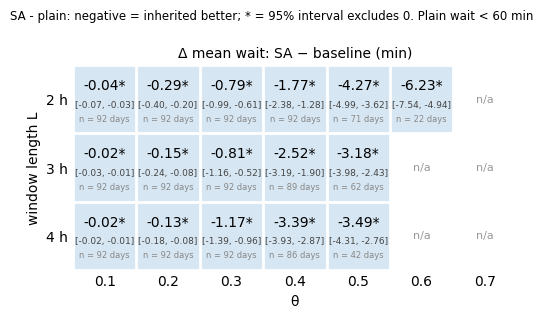

In [144]:
def heat_L_theta(df, q_max=30, min_days=15, need_sig=False,
                 metrics=(("p95", "Δ p95 (min)", 1, 1), ("P(W>15)", "Δ P(W>15) (pp)", 100, 1))):
    """Colore = segno della differenza (blu chiaro < 0, rosa chiaro > 0). need_sig=True: colora solo se l'intervallo esclude 0."""
    s = summarize_days(df, by=("L", "theta"), q_max=q_max, metrics=tuple(m[0] for m in metrics))
    Ls, ths = sorted(s["L"].unique()), sorted(s["theta"].unique())
    cmap = ListedColormap(["#d6e6f2", "#f6d9d6"])                 # negativo, positivo
    fig, axs = plt.subplots(1, len(metrics), figsize=(5.2 * len(metrics), 3.2))
    for ax, (m, title, k, d) in zip(np.atleast_1d(axs), metrics):
        g = s[s.metric == m].set_index(["L", "theta"])
        sign = np.full((len(Ls), len(ths)), np.nan); cells = {}
        for a, L in enumerate(Ls):
            for b, t in enumerate(ths):
                if (L, t) not in g.index or g.loc[(L, t), "days"] < min_days:
                    cells[(a, b)] = None; continue
                r = g.loc[(L, t)]; sig = r.ci_lo > 0 or r.ci_hi < 0
                if sig or not need_sig: sign[a, b] = 1.0 if r["mean"] > 0 else 0.0
                cells[(a, b)] = (f"{r['mean']*k:+.{d}f}{'*' if sig else ''}",
                 f"[{r.ci_lo*k:+.{d}f}, {r.ci_hi*k:+.{d}f}]",
                 f"n = {int(r['days'])} days")

                
        ax.imshow(np.ma.masked_invalid(sign), cmap=cmap, vmin=0, vmax=1, aspect="auto")
        for (a, b), c in cells.items():
            if c is None:
                ax.text(b, a, "n/a", ha="center", va="center", fontsize=8, color="#999")
            else:
                ax.text(b, a - 0.2, c[0], ha="center", va="center", fontsize=10)
                ax.text(b, a + 0.08, c[1], ha="center", va="center", fontsize=6.5, color="#444")
                ax.text(b, a + 0.28, c[2], ha="center", va="center", fontsize=6, color="#888")
        ax.set_xticks(range(len(ths))); ax.set_xticklabels([f"{t:g}" for t in ths]); ax.set_xlabel("θ")
        ax.set_yticks(range(len(Ls))); ax.set_yticklabels([f"{L} h" for L in Ls]); ax.set_ylabel("window length L")
        ax.set_title(title, fontsize=10)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_xticks(np.arange(-.5, len(ths)), minor=True); ax.set_yticks(np.arange(-.5, len(Ls)), minor=True)
        ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="both", length=0)
    fig.suptitle(f"SA - plain: negative = inherited better; * = 95% interval excludes 0. "
                 f"Plain wait < {q_max} min", fontsize=8.5)
    fig.tight_layout(); plt.show()

heat_L_theta(two_arm(agg, "q_sa_med"), q_max=60,
             metrics=(("q_fluid", "Δ mean wait: SA − baseline (min)", 1, 2),))

In [133]:
def summ(g):
    return pd.Series({"cases": len(g), "days": g["day"].nunique(),
                      "mean Δq (min)": g["dq"].mean(), "median Δq": g["dq"].median(),
                      "median Δq (%)": 100 * g["dq_rel"].median(),
                      "improved >0.1 min (%)": 100 * (g["dq"] < -0.1).mean(),
                      "Δ coverage (pp)": 100 * g["dcov"].mean()})
print(agg.groupby("theta").apply(summ, include_groups=False).round(2).to_string())

       cases  days  mean Δq (min)  median Δq  median Δq (%)  improved >0.1 min (%)  Δ coverage (pp)
theta                                                                                              
0.1    276.0  92.0          -0.03       0.00           0.00                  10.51             0.02
0.2    276.0  92.0          -0.19      -0.04          -4.20                  36.96             0.07
0.3    276.0  92.0          -0.92      -0.48         -14.13                  80.80            -0.02
0.4    267.0  92.0          -2.54      -1.59         -20.12                  89.51            -0.42
0.5    175.0  87.0          -3.70      -3.47         -22.61                  93.14            -0.69
0.6     31.0  28.0          -6.28      -5.86         -29.66                  96.77            -1.45
0.7      3.0   3.0          -7.97      -7.97         -29.43                 100.00            -1.54
